# GISPR Module 7 — Visualizing Spatial Data: Static Maps to Interactive Web Maps

**Course:** GIS Spatial Analysis with Python and R (GISPR)
**Module:** 7 — Visualization: Symbology, Classification, Cartography, and Web Maps
**Builds on:** Modules 3–4 (the WRIA 8 salmon watersheds, CRS), Modules 5–6 (the WRIA 8 DEM and NLCD rasters, the watershed suitability screen)

**NOTE:** 
- For Python, you'll need to install leafmap - see [Qiusheng's leafmap page](https://leafmap.org/) and run `conda install -c conda-forge leafmap --freeze-installed` in your open source gispr conda environment
- For R, you'll need to install the `tmap` from CRAN


---

### What you'll accomplish this module

By the end of this notebook you'll be able to:

| # | Learning outcome | Where |
|---|---|---|
| 1 | Load the WRIA 8 data you already know — watersheds, streams, salmon observations, monitoring sites, DEM, land cover — from one `data/` folder | Section 1 |
| 2 | Move from a debugging plot to a publication-quality static map | Section 2 |
| 3 | Match the visual variable to the data — and normalize before you map | Section 3 |
| 4 | Apply and defend a classification method; use fixed breaks for comparison maps | Section 4 |
| 5 | Add the cartographic furniture: legend, scale bar, north arrow, credits, CRS | Section 5 |
| 6 | Layer rasters and vectors on one figure without silent CRS misalignment | Section 6 |
| 7 | Publish to the browser — `folium` and `leafmap` (Python), `leaflet` and `mapview` (R) | Section 7 |
| 8 | Drive ArcGIS Pro symbology and layouts from `arcpy.mp`; bridge to R | Section 8 |
| 9 | Build a report-ready map end to end (Lab) — ⭐ extra credit | Section 9 |
| 10 | Wrap it in a reusable function you carry into Module 8 — ⭐ extra credit | Section 10 |

### How this module is graded — lighter than before

| | What | Counts as |
|---|---|---|
| ✅ **Required** | Run **Sections 1–8** top to bottom and **save the notebook with its outputs** | Homework |
| ✅ **Required** | Answer the **🍍 Self-Check Questions** in the answers cell near the end | Homework |
| ⭐ Extra credit | The **🔧 Try it yourself** prompts | Extra credit |
| ⭐ Extra credit | **Section 9** (Lab: the report map) and **Section 10** (the reusable map function) | Extra credit |

The point is to show the notebook runs for you on the course data and that you can explain what the maps are doing.
Python cells are enough for the required part; the R cells are welcome. 🏠 LOCAL ONLY cells (ArcPy, R-ArcGIS Bridge)
count as run if they print their "not available" note. Details are in the **✅ Homework** block at the end.

### Kernel reminder
- 🔵 **`[R]`** cells — switch kernel to **R** before running
- 🟢 **`[Python]`** cells — switch kernel to **Python 3** (or your cloned ArcGIS Pro env) before running
- 🟠 **`[Python / ArcPy]`** and **`[R / R-ArcGIS Bridge]`** cells — 🏠 **LOCAL ONLY**: need ArcGIS Pro on the same machine. Elsewhere they print a note and skip.
- 📋 **`[Terminal]`** cells — paste the command into your terminal / Anaconda Prompt, **not** in a notebook cell

Run the cells **in order within each language** — later cells reuse variables made earlier.

> **The framing problem for this module:**
> Your Module 6 watershed screen runs clean: for each of the 15 WRIA 8 watersheds you have mean elevation, mean slope,
> percent forest, and the share of gentle, low-elevation, non-water land — the first screen for floodplain restoration.
> Now imagine you need to present a map on the work for public comment. Nobody will read your code. They will judge the map.
>
> The analysis is done. Communicating it is the work that's left — and it is not a lesser kind of work.

> **A warning you should take personally:** every map is an argument. The default settings in every library
> on this page will happily make an argument you did not intend and cannot defend. This module is about
> owning that argument on purpose.

---
## Section 1 — Setup: Copy the Course Data into `Module 7/data/`

No new data tonight. Everything is the WRIA 8 (Cedar–Sammamish) data you've used since Module 3. To keep every path
in this notebook short, **copy the files below into a `data/` folder next to this notebook** before you run anything.

| Copy this | From | Into | What it is |
|---|---|---|---|
| `salmon_watersheds.gdb` (whole folder) | `Module 3/GISPR_Module3_Data/data/` | `Module 7/data/` | `watersheds` (15 HUC-12s), `streams` (464 NHDPlus V2 flowlines), `wria8_boundary` — EPSG:2926 |
| `salmon_observations_hosted_backup.gpkg` | `Module 3/GISPR_Module3_Data/data/` | `Module 7/data/` | 60 salmon observations (Chinook, Coho, Sockeye; fall 2024) — the backup of the hosted layer |
| `monitoring_sites.csv` | `Module 3/GISPR_Module3_Data/data/` | `Module 7/data/` | 800 stream monitoring sites with a water temperature (°C) |
| `wria8_dem_30m.tif` | `module5_rasters.zip` (Module 5) | `Module 7/data/` | USGS 3DEP DEM, 30 m, EPSG:32610 |
| `wria8_nlcd2021_30m.tif` | `module5_rasters.zip` (Module 5) | `Module 7/data/` | NLCD 2021 land cover, same 30 m grid |

When you're done, the folder looks like this:

```
Module 7/
├── GISPR_Module7_Visualization.ipynb
└── data/
    ├── salmon_watersheds.gdb/
    ├── salmon_observations_hosted_backup.gpkg
    ├── monitoring_sites.csv
    ├── wria8_dem_30m.tif
    └── wria8_nlcd2021_30m.tif
```

**Shortcut:** the next cell looks for each file in the usual places — your `Module 3` and `Module 5` folders, or
`GISPR_Module3_Data.zip` and `module5_rasters.zip` in the course repo — and copies or unzips whatever is missing.
Copying by hand in File Explorer is just as good. Outputs from tonight go to `outputs/module7/`.

> **You don't need your Module 6 outputs.** The setup cell re-derives the Module 6 watershed summary from the DEM and
> NLCD with the same thresholds (slope < 15 %, elevation < 1000 m, not open water), so everyone starts from identical numbers.

🟢 **`[Python]`**

In [ ]:
# [Python] Optional copy helper — fills data/ from your Module 3 / Module 5 folders or the course-repo zips
# Safe to re-run: it only copies what's missing. Skip it if you copied the files by hand.
from pathlib import Path
import shutil, zipfile

DATA = Path("data")
DATA.mkdir(exist_ok=True)

NEEDED = ["salmon_watersheds.gdb", "salmon_observations_hosted_backup.gpkg", "monitoring_sites.csv",
          "wria8_dem_30m.tif", "wria8_nlcd2021_30m.tif"]

# Places these files usually live, relative to this notebook (edit or add your own)
FOLDERS = [Path("../Module 3/GISPR_Module3_Data/data"), Path("../GISPR_Module3_Data/data"),
           Path("GISPR_Module3_Data/data"), Path("../Module 5/GISPR_Module5_Data"),
           Path("../Module 5/module5_rasters"), Path("module5_rasters"), Path("../module5_rasters")]
ZIPS    = [Path("GISPR_Module3_Data.zip"), Path("../GISPR_Module3_Data.zip"),
           Path("module5_rasters.zip"), Path("../module5_rasters.zip"), Path("../Module 5/module5_rasters.zip")]

for name in NEEDED:
    if (DATA / name).exists():
        print(f"✓ {name:42} already in data/")
        continue
    src = next((f / name for f in FOLDERS if (f / name).exists()), None)
    if src is not None:
        (shutil.copytree if src.is_dir() else shutil.copy2)(src, DATA / name)
        print(f"→ {name:42} copied from {src.parent}")
        continue
    for z in (z for z in ZIPS if z.exists()):
        with zipfile.ZipFile(z) as zf:
            members = [m for m in zf.namelist() if Path(m).parts and name in Path(m).parts]
            for m in members:                           # strip any leading folders (e.g. data/)
                rel = Path(*Path(m).parts[Path(m).parts.index(name):])
                if m.endswith("/"):
                    continue
                (DATA / rel).parent.mkdir(parents=True, exist_ok=True)
                (DATA / rel).write_bytes(zf.read(m))
        if members:
            print(f"→ {name:42} unzipped from {z}")
            break
    else:
        print(f"✗ {name:42} NOT FOUND — copy it into data/ by hand (see the table above)")

→ salmon_watersheds.gdb                      unzipped from GISPR_Module3_Data.zip
→ salmon_observations_hosted_backup.gpkg     unzipped from GISPR_Module3_Data.zip
→ monitoring_sites.csv                       unzipped from GISPR_Module3_Data.zip
→ wria8_dem_30m.tif                          copied from module5_rasters
→ wria8_nlcd2021_30m.tif                     copied from module5_rasters


🔵 **`[R]`**

In [ ]:
# [R] Optional copy helper — the same idea in R (skip it if you copied the files by hand)
DATA <- "data"
dir.create(DATA, showWarnings = FALSE)
needed  <- c("salmon_watersheds.gdb", "salmon_observations_hosted_backup.gpkg", "monitoring_sites.csv",
             "wria8_dem_30m.tif", "wria8_nlcd2021_30m.tif")
folders <- c("../Module 3/GISPR_Module3_Data/data", "../GISPR_Module3_Data/data", "GISPR_Module3_Data/data",
             "../Module 5/GISPR_Module5_Data", "../Module 5/module5_rasters", "module5_rasters")
for (f in needed) {
  if (file.exists(file.path(DATA, f))) { cat("OK  ", f, "already in data/\n"); next }
  src <- Filter(file.exists, file.path(folders, f))
  if (length(src)) {
    file.copy(src[1], DATA, recursive = TRUE)
    cat("COPY", f, "from", dirname(src[1]), "\n")
  } else cat("MISSING", f, "- copy it into data/ by hand (or unzip the course-repo zips)\n")
}

OK   salmon_watersheds.gdb already in data/
OK   salmon_observations_hosted_backup.gpkg already in data/
OK   monitoring_sites.csv already in data/
OK   wria8_dem_30m.tif already in data/
OK   wria8_nlcd2021_30m.tif already in data/


### The setup cell

It does four things, in this order:

1. **Loads** the vectors from `salmon_watersheds.gdb`, the salmon points, and the monitoring sites (a CSV of lat/lon → points).
2. **Reprojects every vector to the rasters' CRS — EPSG:32610 (UTM 10N, metres).** Same decision as Module 6: moving
   ~500 features is exact and cheap; warping 6.9 million cells is neither. Metres also make the scale bar honest.
3. **Rebuilds the Module 6 watershed summary** — `elev_mean`, `slope_mean`, `pct_forest`, `pct_suitable` — plus three
   attributes this module needs: `area_km2`, `stream_km`, and the salmon totals per watershed.
4. **Writes a hillshade** to `outputs/module7/` for the layered maps in Sections 5–10.

Two details are in here on purpose, because real data has them:

- **Five watersheds have no salmon observations in this dataset.** That is *not surveyed here*, not *zero salmon*. A map
  that silently colours them as zero is lying. You'll handle this explicitly in Section 3.
- **The watersheds are very uneven in size.** Lake Washington–Sammamish River is 461 km²; Rock Creek is 38 km². That's
  what makes Section 3 work.

🟢 **`[Python]`**

In [3]:
# [Python] Setup — load the WRIA 8 data, align the CRS, rebuild the Module 6 summary, write a hillshade
import os, warnings
# Natural breaks (mapclassify) runs scikit-learn's KMeans. On Windows that prints a wall of harmless warnings
# (no `wmic` on Windows 11, an MKL memory-leak note, mixed OpenMP libraries). These lines quiet them — results are identical.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))
os.environ.setdefault("OMP_NUM_THREADS", "1")
warnings.filterwarnings("ignore", message=r"\s*(Could not find the number of physical cores|KMeans is known to have a memory leak|Found Intel OpenMP)")

from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask
from rasterio.features import rasterize
import matplotlib.pyplot as plt

DATA = Path("data")
OUT  = Path("outputs/module7")
OUT.mkdir(parents=True, exist_ok=True)
WS_GDB = DATA / "salmon_watersheds.gdb"
for f in ["salmon_watersheds.gdb", "salmon_observations_hosted_backup.gpkg", "monitoring_sites.csv",
          "wria8_dem_30m.tif", "wria8_nlcd2021_30m.tif"]:
    assert (DATA / f).exists(), f"Missing data/{f} — run the copy helper above or copy it by hand"

MAP_EPSG    = 32610   # the rasters' CRS — UTM zone 10N, metres. Every map tonight is drawn in it.
COURSE_EPSG = 2926    # the Module 3–4 vectors as stored — WA State Plane North, US survey feet

# ── 1. Vectors (lower-case column names, as in Modules 3–6) ──────────────────
watersheds = gpd.read_file(WS_GDB, layer="watersheds").rename(columns=str.lower).to_crs(MAP_EPSG)
wria8      = gpd.read_file(WS_GDB, layer="wria8_boundary").rename(columns=str.lower).to_crs(MAP_EPSG)
streams    = gpd.read_file(WS_GDB, layer="streams").rename(columns=str.lower).to_crs(MAP_EPSG)
streams    = streams[streams["stream_order"] > 0].copy()   # order 0 = coastline, pipelines, unordered connectors

salmon = (gpd.read_file(DATA / "salmon_observations_hosted_backup.gpkg")
            .rename(columns=str.lower).to_crs(MAP_EPSG))
sites_df = pd.read_csv(DATA / "monitoring_sites.csv")
sites = gpd.GeoDataFrame(sites_df.rename(columns={"value": "temp_c"}),
                         geometry=gpd.points_from_xy(sites_df["longitude"], sites_df["latitude"]),
                         crs=4326).to_crs(MAP_EPSG)

# HUC-10 sub-basins — the first 10 digits of the HUC-12 (used for comparison maps in Sections 4 and 10)
SUBBASIN = {"1711001201": "Cedar River", "1711001202": "Lake Sammamish", "1711001203": "Sammamish River",
            "1711001204": "Lake Washington", "1711001902": "Puget Sound frontal"}
watersheds["subbasin"] = watersheds["huc12"].str[:10].map(SUBBASIN)
sites = sites.sjoin(watersheds[["watershed_id", "subbasin", "geometry"]], how="left").drop(columns="index_right")

# ── 2. Rasters, clipped to WRIA 8 ────────────────────────────────────────────
with rasterio.open(DATA / "wria8_dem_30m.tif") as src:
    dem_arr, clip_tr = mask(src, wria8.geometry, crop=True, nodata=-9999, filled=True)
    profile = src.profile | dict(height=dem_arr.shape[1], width=dem_arr.shape[2], transform=clip_tr,
                                 compress="deflate")
with rasterio.open(DATA / "wria8_nlcd2021_30m.tif") as src:
    lc, _ = mask(src, wria8.geometry, crop=True, nodata=0, filled=True)
dem = np.where(dem_arr[0] == -9999, np.nan, dem_arr[0]).astype("float32")
lc  = lc[0]
CELL = profile["transform"].a                       # 30 m
valid = ~np.isnan(dem)

def horn(z, cell):
    """Horn (1981) 3×3 finite differences — the same kernel ArcGIS Slope and Hillshade use."""
    p = np.pad(z, 1, mode="edge")
    a, b, c = p[:-2, :-2], p[:-2, 1:-1], p[:-2, 2:]
    d, f    = p[1:-1, :-2],             p[1:-1, 2:]
    g, h, i = p[2:, :-2],  p[2:, 1:-1], p[2:, 2:]
    dzdx = ((c + 2 * f + i) - (a + 2 * d + g)) / (8 * cell)
    dzdy = ((g + 2 * h + i) - (a + 2 * b + c)) / (8 * cell)
    return dzdx, dzdy

def hillshade(z, cell, azimuth=315, altitude=45):
    """ESRI hillshade formula. Carry this forward — Module 8 uses it."""
    dzdx, dzdy = horn(z, cell)
    slope  = np.arctan(np.hypot(dzdx, dzdy))
    aspect = np.arctan2(dzdy, -dzdx)
    zen, az = np.radians(90 - altitude), np.radians((360 - azimuth + 90) % 360)
    hs = np.cos(zen) * np.cos(slope) + np.sin(zen) * np.sin(slope) * np.cos(az - aspect)
    return np.clip(255 * hs, 1, 255)

# ── 3. Rebuild the Module 6 watershed summary (same thresholds as the Module 6 lab) ──
dzdx, dzdy = horn(dem, CELL)
slope_pct = 100 * np.hypot(dzdx, dzdy)
suitable  = (slope_pct < 15) & (dem < 1000) & (lc != 11) & valid
zones = rasterize(((geom, k + 1) for k, geom in enumerate(watersheds.geometry)),
                  out_shape=dem.shape, transform=clip_tr, fill=0, dtype="int32")

def zonal_mean(arr):
    """Mean of arr per watershed — cell-centre zonal statistics, the same idea as rasterstats."""
    ok = valid & (zones > 0)
    tot = np.bincount(zones[ok], weights=arr[ok], minlength=len(watersheds) + 1)
    cnt = np.bincount(zones[ok], minlength=len(watersheds) + 1)
    return (tot / np.maximum(cnt, 1))[1:]

watersheds["elev_mean"]    = zonal_mean(dem).round(0)
watersheds["slope_mean"]   = zonal_mean(slope_pct).round(1)
watersheds["pct_forest"]   = (100 * zonal_mean(np.isin(lc, [41, 42, 43]).astype(float))).round(1)
watersheds["pct_suitable"] = (100 * zonal_mean(suitable.astype(float))).round(1)

# ── 4. Attributes for Section 3: size, stream length, salmon totals ──────────
watersheds["area_km2"]  = (watersheds.area / 1e6).round(1)
streams["length_km"]    = streams.length / 1000
watersheds["stream_km"] = watersheds["watershed_id"].map(
    streams.groupby("watershed_id")["length_km"].sum()).fillna(0).round(1)
watersheds["drainage_density"] = (watersheds["stream_km"] / watersheds["area_km2"]).round(2)   # km per km²

obs = salmon.sjoin(watersheds[["watershed_id", "geometry"]], how="left")
watersheds["salmon_counted"] = watersheds["watershed_id"].map(obs.groupby("watershed_id")["count"].sum())
watersheds["n_surveys"]      = watersheds["watershed_id"].map(obs.groupby("watershed_id").size())
watersheds["salmon_per_km"]  = (watersheds["salmon_counted"] / watersheds["stream_km"]).round(2)
# Watersheds with no observations stay NaN on purpose — "not surveyed here" is not "zero salmon".

# ── 5. Write the clipped DEM and a hillshade for the layered maps ───────────
dem_path = OUT / "wria8_dem_clip.tif"
hs_path  = OUT / "wria8_hillshade.tif"
with rasterio.open(dem_path, "w", **profile) as dst:
    dst.write(np.where(valid, dem, -9999).astype("float32"), 1)
with rasterio.open(hs_path, "w", **(profile | dict(dtype="uint8", nodata=0))) as dst:
    dst.write(np.where(valid, hillshade(np.where(valid, dem, 0), CELL), 0).astype("uint8"), 1)

print(f"watersheds : {len(watersheds)} polygons | streams: {len(streams)} lines | "
      f"salmon: {len(salmon)} points | sites: {len(sites)} points | all EPSG:{watersheds.crs.to_epsg()}")
print(f"DEM        : {dem.shape[0]:,} × {dem.shape[1]:,} cells at {CELL:g} m | {np.nanmin(dem):.1f} to {np.nanmax(dem):.0f} m")
print(f"no salmon observations in: {int(watersheds['salmon_counted'].isna().sum())} watersheds")
watersheds[["watershed_id", "watershed_name", "subbasin", "area_km2", "elev_mean", "slope_mean",
            "pct_forest", "pct_suitable", "salmon_counted"]].sort_values("pct_suitable", ascending=False)

watersheds : 15 polygons | streams: 422 lines | salmon: 60 points | sites: 800 points | all EPSG:32610
DEM        : 2,503 × 2,602 cells at 30 m | -0.4 to 1650 m
no salmon observations in: 5 watersheds


,watershed_id,watershed_name,subbasin,area_km2,elev_mean,slope_mean,pct_forest,pct_suitable,salmon_counted
11,WS-12,Swamp Creek,Sammamish River,64.2,125.0,NaN,5.6,95.0,11.0
10,WS-11,North Creek,Sammamish River,74.5,108.0,NaN,7.2,93.8,15.0
9,WS-10,Bear Creek,Sammamish River,121.9,105.0,NaN,33.5,89.9,179.0
12,WS-13,Bear Creek-Sammamish River,Sammamish River,106.2,80.0,NaN,18.7,87.3,162.0
6,WS-07,Madsen Creek-Cedar River,Cedar River,100.5,133.0,NaN,33.5,81.5,273.0
14,WS-15,Shell Creek-Frontal Puget Sound,Puget Sound frontal,104.5,97.0,NaN,14.8,77.5,NaN
5,WS-06,Rock Creek,Cedar River,37.7,241.0,NaN,69.9,76.4,NaN
4,WS-05,Rock Creek-Cedar River,Cedar River,53.6,319.0,NaN,88.5,70.6,129.0
13,WS-14,Lake Washington-Sammamish River,Lake Washington,460.8,73.0,NaN,8.8,66.0,53.0
8,WS-09,Lake Sammamish-Sammamish River,Lake Sammamish,115.3,110.0,NaN,23.0,59.5,71.0


🔵 **`[R]`**

In [ ]:
# [R] Setup — the same data, the same CRS decision, the same Module 6 summary (terra + sf)
library(sf)
library(terra)
library(dplyr)

DATA <- "data"
OUT  <- "outputs/module7"; dir.create(OUT, recursive = TRUE, showWarnings = FALSE)
WS_GDB <- file.path(DATA, "salmon_watersheds.gdb")
stopifnot("Missing files in data/ - run the copy helper or copy them by hand" =
            all(file.exists(file.path(DATA, c("salmon_watersheds.gdb", "salmon_observations_hosted_backup.gpkg",
                                              "monitoring_sites.csv", "wria8_dem_30m.tif",
                                              "wria8_nlcd2021_30m.tif")))))
MAP_EPSG <- 32610                                    # the rasters' CRS - UTM 10N, metres

lower_names <- function(x) {                          # lower-case attributes, leave the geometry column alone
  keep <- names(x) != attr(x, "sf_column"); names(x)[keep] <- tolower(names(x)[keep]); x
}
read_ws <- function(layer) st_transform(lower_names(st_read(WS_GDB, layer = layer, quiet = TRUE)), MAP_EPSG)
watersheds <- read_ws("watersheds")
wria8      <- read_ws("wria8_boundary")
streams    <- read_ws("streams") |> filter(stream_order > 0)
salmon     <- st_transform(lower_names(st_read(file.path(DATA, "salmon_observations_hosted_backup.gpkg"),
                                               quiet = TRUE)), MAP_EPSG)
sites      <- read.csv(file.path(DATA, "monitoring_sites.csv")) |>
  rename(temp_c = value) |>
  st_as_sf(coords = c("longitude", "latitude"), crs = 4326) |>
  st_transform(MAP_EPSG)

subbasin_names <- c("1711001201" = "Cedar River", "1711001202" = "Lake Sammamish",
                    "1711001203" = "Sammamish River", "1711001204" = "Lake Washington",
                    "1711001902" = "Puget Sound frontal")
watersheds$subbasin <- unname(subbasin_names[substr(watersheds$huc12, 1, 10)])
sites <- st_join(sites, watersheds[, c("watershed_id", "subbasin")])

# Rasters clipped to WRIA 8
wv   <- vect(wria8)
dem  <- mask(crop(rast(file.path(DATA, "wria8_dem_30m.tif")), wv), wv)
nlcd <- mask(crop(rast(file.path(DATA, "wria8_nlcd2021_30m.tif")), wv), wv)

# Module 6 summary - same thresholds as the Module 6 lab
slope_pct <- tan(terrain(dem, v = "slope", unit = "radians")) * 100
suitable  <- (slope_pct < 15) & (dem < 1000) & !(nlcd %in% 11)
forest    <- nlcd %in% c(41, 42, 43)
zone_mean <- function(r) terra::extract(r, vect(watersheds), fun = mean, na.rm = TRUE)[, 2]
watersheds$elev_mean    <- round(zone_mean(dem))
watersheds$slope_mean   <- round(zone_mean(slope_pct), 1)
watersheds$pct_forest   <- round(100 * zone_mean(forest), 1)
watersheds$pct_suitable <- round(100 * zone_mean(suitable), 1)

# Attributes for Section 3
watersheds$area_km2 <- round(as.numeric(st_area(watersheds)) / 1e6, 1)
streams$length_km   <- as.numeric(st_length(streams)) / 1000
skm <- tapply(streams$length_km, streams$watershed_id, sum)
watersheds$stream_km        <- round(ifelse(is.na(skm[watersheds$watershed_id]), 0, skm[watersheds$watershed_id]), 1)
watersheds$drainage_density <- round(watersheds$stream_km / watersheds$area_km2, 2)
obs <- st_join(salmon, watersheds[, "watershed_id"])
tot <- tapply(obs$count, obs$watershed_id, sum)
watersheds$salmon_counted <- as.numeric(tot[watersheds$watershed_id])          # NA = no observations here
watersheds$salmon_per_km  <- round(watersheds$salmon_counted / watersheds$stream_km, 2)

st_agr(watersheds) <- "constant"; st_agr(streams) <- "constant"   # attributes describe whole features

# Hillshade for the layered maps
hs <- shade(terrain(dem, "slope", unit = "radians"), terrain(dem, "aspect", unit = "radians"),
            angle = 45, direction = 315)
names(hs) <- "hillshade"
writeRaster(hs, file.path(OUT, "wria8_hillshade_r.tif"), overwrite = TRUE)

cat(nrow(watersheds), "watersheds |", nrow(streams), "streams |", nrow(salmon), "salmon |",
    nrow(sites), "sites | EPSG:", st_crs(watersheds)$epsg, "\n")
cat("no salmon observations in:", sum(is.na(watersheds$salmon_counted)), "watersheds\n")
# R and Python differ by a few tenths: terra::extract counts cell centres, as rasterstats does, but its
# slope kernel and the clip edge differ slightly. The rankings are identical.
st_drop_geometry(watersheds)[order(-watersheds$pct_suitable),
                             c("watershed_name", "subbasin", "area_km2", "elev_mean", "pct_forest", "pct_suitable")]

Linking to GEOS 3.13.1, GDAL 3.11.4, PROJ 9.7.0; sf_use_s2() is TRUE


Warning message:
package ‘sf’ was built under R version 4.5.2 


terra 1.9.50


Warning message:
package ‘terra’ was built under R version 4.5.3 



Attaching package: ‘dplyr’

The following objects are masked from ‘package:terra’:

    intersect, union

The following objects are masked from ‘package:stats’:

    filter, lag

The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Warning message:
package ‘dplyr’ was built under R version 4.5.2 


15 watersheds | 422 streams | 60 salmon | 800 sites | EPSG: 32610 
no salmon observations in: 5 watersheds


                    watershed_name            subbasin area_km2
12                     Swamp Creek     Sammamish River     64.2
11                     North Creek     Sammamish River     74.5
10                      Bear Creek     Sammamish River    121.9
13      Bear Creek-Sammamish River     Sammamish River    106.2
7         Madsen Creek-Cedar River         Cedar River    100.5
6                       Rock Creek         Cedar River     37.7
15 Shell Creek-Frontal Puget Sound Puget Sound frontal    104.5
5           Rock Creek-Cedar River         Cedar River     53.6
14 Lake Washington-Sammamish River     Lake Washington    460.8
9   Lake Sammamish-Sammamish River      Lake Sammamish    115.3
8                   Issaquah Creek      Lake Sammamish    145.9
4         Taylor Creek-Cedar River         Cedar River     78.9
2                        Rex River         Cedar River     59.1
3   Chester Morse Lake-Cedar River         Cedar River     87.3
1           Headwaters Cedar River      

### 🔧 Try it yourself — the data ⭐ *(extra credit — optional)*

1. Sort the summary by `pct_forest` instead of `pct_suitable`. Which watersheds swap places, and why would a forest-cover
   map and a suitability map tell the council different stories about the Cedar River headwaters?
2. Print `watersheds[["watershed_name", "area_km2", "stream_km"]].sort_values("stream_km")`. Which watershed has the most
   stream kilometres? Hold on to that answer — Section 3 is going to complicate it.
3. Change the suitability threshold to `slope_pct < 10` and re-run. Which watersheds lose the most? (That's a Module 6
   question — but tonight the answer has to survive being put on a map.)

In [4]:
# What does the watershed geodataframe look like?
watersheds.head()

,watershed_id,watershed_name,huc12,wria,wria_name,area_acres,geometry,subbasin,elev_mean,slope_mean,pct_forest,pct_suitable,area_km2,stream_km,drainage_density,salmon_counted,n_surveys,salmon_per_km
0,WS-01,Headwaters Cedar River,171100120101,8.0,Cedar-Sammamish,16220.5,"MULTIPOLYGON (((611779.252 5245869.534, 611842...",Cedar River,1068.0,NaN,91.7,6.7,65.6,52.8,0.80,NaN,NaN,NaN
1,WS-02,Rex River,171100120102,8.0,Cedar-Sammamish,14602.4,"MULTIPOLYGON (((606416.462 5239662.131, 606403...",Cedar River,915.0,NaN,92.2,9.3,59.1,33.8,0.57,NaN,NaN,NaN
2,WS-03,Chester Morse Lake-Cedar River,171100120103,8.0,Cedar-Sammamish,21575.4,"MULTIPOLYGON (((603544.736 5250592.938, 603566...",Cedar River,826.0,NaN,81.5,8.8,87.3,60.7,0.70,NaN,NaN,NaN
3,WS-04,Taylor Creek-Cedar River,171100120104,8.0,Cedar-Sammamish,19504.0,"MULTIPOLYGON (((594074.771 5251928.492, 594059...",Cedar River,610.0,NaN,96.3,30.9,78.9,64.3,0.81,23.0,3.0,0.36
4,WS-05,Rock Creek-Cedar River,171100120105,8.0,Cedar-Sammamish,13248.4,"MULTIPOLYGON (((585182.673 5253943.753, 585237...",Cedar River,319.0,NaN,88.5,70.6,53.6,39.3,0.73,129.0,4.0,3.28


In [ ]:
list(watersheds)

['watershed_id',
 'watershed_name',
 'huc12',
 'wria',
 'wria_name',
 'area_acres',
 'geometry',
 'subbasin',
 'elev_mean',
 'slope_mean',
 'pct_forest',
 'pct_suitable',
 'area_km2',
 'stream_km',
 'drainage_density',
 'salmon_counted',
 'n_surveys',
 'salmon_per_km']

In [ ]:
# [Python] Try it yourself — Section 1 answers
cols = ["watershed_name", "subbasin", "pct_forest", "pct_suitable"]
summary = watersheds[cols].copy()
summary["rank_suitable"] = summary["pct_suitable"].rank(ascending=False, method="min").astype(int)
summary["rank_forest"]   = summary["pct_forest"].rank(ascending=False, method="min").astype(int)
summary["rank_shift"]    = summary["rank_suitable"] - summary["rank_forest"]

# 1. Sort by pct_forest and compare ranks with the pct_suitable ranking
print("1. Sorted by pct_forest (rank shift = suitable rank - forest rank):")
display(summary.sort_values("pct_forest", ascending=False))

# 2. Stream kilometres per watershed
print("\n2. Stream km per watershed:")
display(watersheds[["watershed_name", "area_km2", "stream_km"]].sort_values("stream_km"))

# 3. Re-run the suitability screen at slope < 10 % (without overwriting the original columns)
suitable10 = (slope_pct < 10) & (dem < 1000) & (lc != 11) & valid
pct10 = (100 * zonal_mean(suitable10.astype(float))).round(1)
change = watersheds[["watershed_name", "area_km2", "pct_suitable"]].copy()
change["pct_suitable_10"] = pct10
change["loss_pts"] = (change["pct_suitable"] - change["pct_suitable_10"]).round(1)
change["loss_pct_of_original"] = (100 * change["loss_pts"] / change["pct_suitable"]).round(1)
print("\n3. Suitability, slope < 15 % vs. < 10 %:")
display(change.sort_values("loss_pts", ascending=False))


1. Sorted by pct_forest (rank shift = suitable rank - forest rank):


,watershed_name,subbasin,pct_forest,pct_suitable,rank_suitable,rank_forest,rank_shift
3,Taylor Creek-Cedar River,Cedar River,96.3,30.9,12,1,11
1,Rex River,Cedar River,92.2,9.3,13,2,11
0,Headwaters Cedar River,Cedar River,91.7,6.7,15,3,12
4,Rock Creek-Cedar River,Cedar River,88.5,70.6,8,4,4
2,Chester Morse Lake-Cedar River,Cedar River,81.5,8.8,14,5,9
5,Rock Creek,Cedar River,69.9,76.4,7,6,1
7,Issaquah Creek,Lake Sammamish,68.8,47.3,11,7,4
6,Madsen Creek-Cedar River,Cedar River,33.5,81.5,5,8,-3
9,Bear Creek,Sammamish River,33.5,89.9,3,8,-5
8,Lake Sammamish-Sammamish River,Lake Sammamish,23.0,59.5,10,10,0



2. Stream km per watershed:


,watershed_name,area_km2,stream_km
5,Rock Creek,37.7,2.9
14,Shell Creek-Frontal Puget Sound,104.5,15.1
11,Swamp Creek,64.2,24.5
10,North Creek,74.5,27.8
1,Rex River,59.1,33.8
4,Rock Creek-Cedar River,53.6,39.3
0,Headwaters Cedar River,65.6,52.8
12,Bear Creek-Sammamish River,106.2,55.2
8,Lake Sammamish-Sammamish River,115.3,56.1
6,Madsen Creek-Cedar River,100.5,57.8



3. Suitability, slope < 15 % vs. < 10 %:


,watershed_name,area_km2,pct_suitable,pct_suitable_10,loss_pts,loss_pct_of_original
4,Rock Creek-Cedar River,53.6,70.6,55.4,15.2,21.5
14,Shell Creek-Frontal Puget Sound,104.5,77.5,63.0,14.5,18.7
7,Issaquah Creek,145.9,47.3,34.4,12.9,27.3
5,Rock Creek,37.7,76.4,63.9,12.5,16.4
12,Bear Creek-Sammamish River,106.2,87.3,74.9,12.4,14.2
13,Lake Washington-Sammamish River,460.8,66.0,54.1,11.9,18.0
8,Lake Sammamish-Sammamish River,115.3,59.5,48.3,11.2,18.8
6,Madsen Creek-Cedar River,100.5,81.5,71.3,10.2,12.5
9,Bear Creek,121.9,89.9,80.0,9.9,11.0
3,Taylor Creek-Cedar River,78.9,30.9,21.7,9.2,29.8


**Answers — Section 1 "Try it yourself"**

1. **Forest vs. suitability ranking.** The two rankings are nearly inverted. The Cedar headwaters (Headwaters Cedar River, Rex River, Chester Morse Lake) are the most forested (82–92 %) but rank 13th–15th on suitability (7–9 %). Swamp Creek and North Creek swap the other way: they rank 1st–2nd on suitability (94–95 %) and 14th–15th on forest (6–7 %). Forest cover is high where slopes are steep, so it marks land that is steep and wooded. Suitability marks gentle, low, non-water land, which in this basin is mostly the developed lowland. A forest map would flag the Cedar headwaters as the most intact, while a suitability map would show them as nearly useless for floodplain restoration. The two maps answer different questions (protect vs. restore).
2. **Stream kilometres.** Lake Washington–Sammamish River has the most stream km (about 164 km). It is also by far the largest watershed (461 km²), so the total mostly reflects size. Rock Creek has the fewest (2.9 km). Section 3's point: normalize by area (drainage density) before mapping.
3. **Slope < 10 %.** Rock Creek–Cedar River loses the most in absolute points (about 15 points, 70.6 to 55.4), followed by Shell Creek–Frontal Puget Sound (14.5) and Issaquah Creek (12.9). In relative terms the Cedar headwaters lose the most: Headwaters Cedar River drops about 51 % and Rex River about 44 %, but from a very small base. Swamp Creek and North Creek barely change (about 7 to 8 points), so their lead is robust.


---
## Section 2 — From Debugging Plot to Map

`gdf.plot()` is for simple maps - we want to use other tools for polished maps.

ArcGIS Pro is *opinionated*: drop a layer in and you get a frame, a coordinate system, and a Contents pane
nagging you toward a legend. **matplotlib gives you an Axes and nothing else.** That's the trade of working
in code — total control, zero guardrails.

So build the map in layers, and watch what each one buys you. The layer is the Module 6 result — `pct_suitable`,
the share of each watershed that's gentle (< 15 % slope), low (< 1000 m), and not open water:

| Step | Call | What it buys |
|---|---|---|
| 1 | `.plot()` | Do the geometries exist? Are they where you expect? |
| 2 | `+ column=` | The attribute becomes visible |
| 3 | `+ scheme=`, `k=` | Continuous values become classes |
| 4 | `+ legend`, title, credits | A reader can now verify your claim |

Steps 1–2 are for you. Steps 3–4 are for everyone else. **Ship step 4.**

🟢 **`[Python]`**

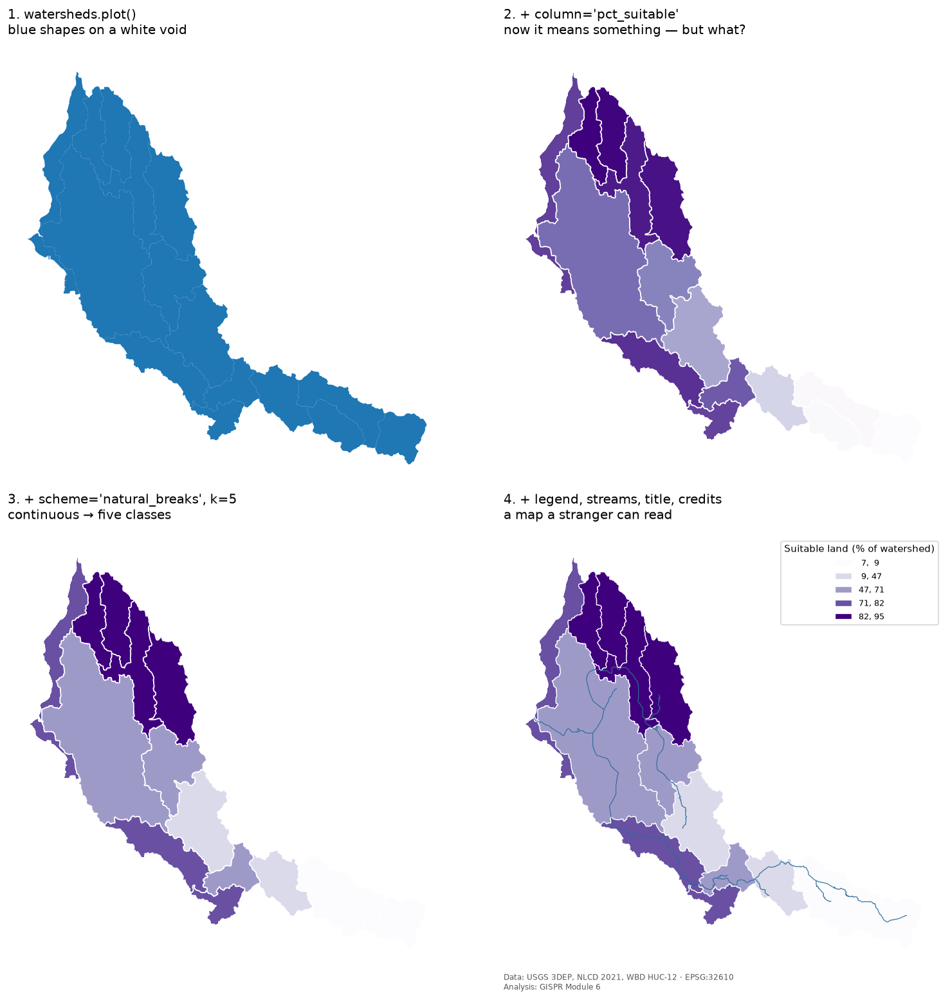

Panel 1 is our simpe quick map; Panel 4 is a complete map. The difference is about six lines of code.


In [5]:
# [Python] Build the map in four layers — run and watch each panel improve
fig, axes = plt.subplots(2, 2, figsize=(13, 13))

# ── 1. The debugging view — this is what .plot() gives you ───────────────────
watersheds.plot(ax=axes[0, 0])
axes[0, 0].set_title("1. watersheds.plot()\nblue shapes on a white void", loc="left")

# ── 2. Encode the attribute ─────────────────────────────────────────────────
watersheds.plot(ax=axes[0, 1], column="pct_suitable", cmap="Purples", edgecolor="white")
axes[0, 1].set_title("2. + column='pct_suitable'\nnow it means something — but what?", loc="left")

# ── 3. Classify it ──────────────────────────────────────────────────────────
watersheds.plot(ax=axes[1, 0], column="pct_suitable", cmap="Purples", edgecolor="white",
                scheme="natural_breaks", k=5)
axes[1, 0].set_title("3. + scheme='natural_breaks', k=5\ncontinuous → five classes", loc="left")

# ── 4. Make it readable ─────────────────────────────────────────────────────
ax = axes[1, 1]
watersheds.plot(ax=ax, column="pct_suitable", cmap="Purples", edgecolor="white", linewidth=0.8,
                scheme="natural_breaks", k=5, legend=True,
                legend_kwds={"title": "Suitable land (% of watershed)", "loc": "upper right",
                             "fontsize": 8, "title_fontsize": 9, "fmt": "{:.0f}"})
streams[streams["stream_order"] >= 3].plot(ax=ax, color="#2b6c99", linewidth=0.7)
ax.set_title("4. + legend, streams, title, credits\na map a stranger can read", loc="left")
ax.text(0, -0.01, "Data: USGS 3DEP, NLCD 2021, WBD HUC-12 · EPSG:32610\nAnalysis: GISPR Module 6",
        transform=ax.transAxes, va="top", fontsize=7, color="0.35")      # below the map, never under the legend

for a in axes.ravel():
    a.set_axis_off()
plt.tight_layout()
plt.show()
print("Panel 1 is our simpe quick map; Panel 4 is a complete map. The difference is about six lines of code.")

🔵 **`[R]`**

Warning message:
package ‘tmap’ was built under R version 4.5.3 


ℹ tmap modes "plot" - "view"
ℹ toggle with ]8;;x-r-run:tmap::ttm()tmap::ttm()]8;;
This message is displayed once per session.


Warning message:
package ‘ggplot2’ was built under R version 4.5.3 


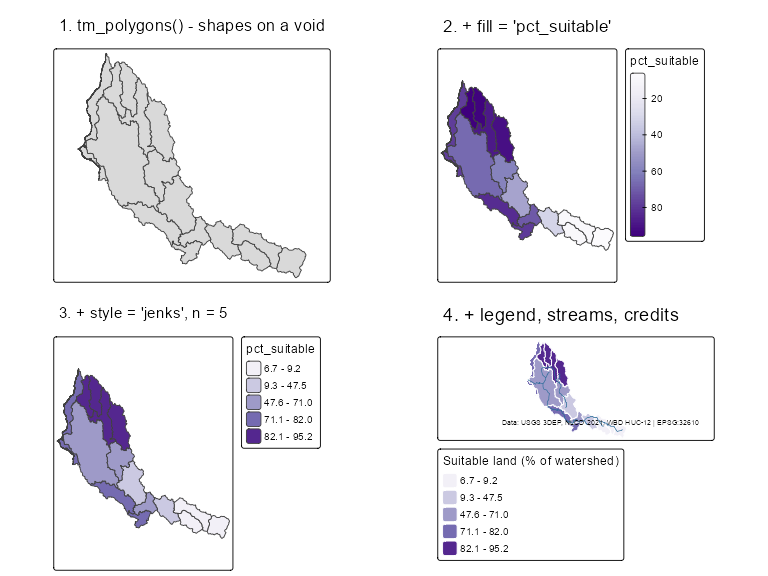

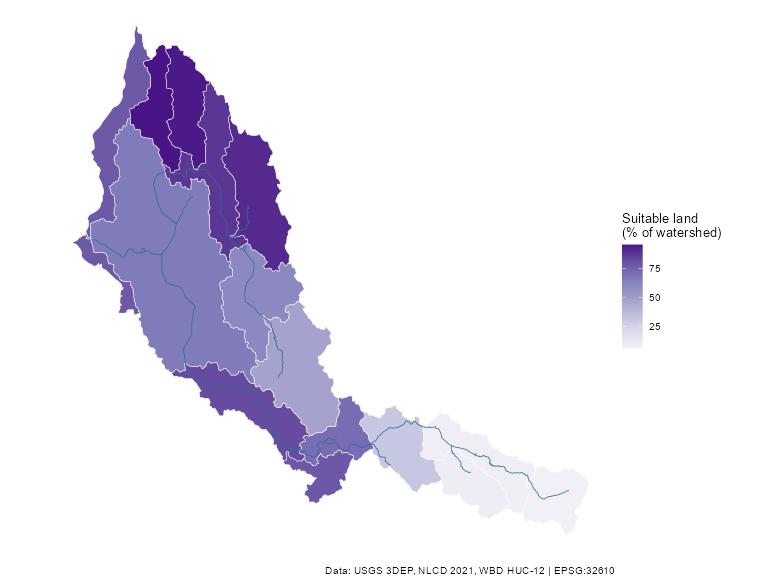

In [ ]:
# [R] The same four layers with sf + tmap (tmap v4 syntax — check packageVersion("tmap") >= "4.0")
library(sf)
library(tmap)
tmap_mode("plot")   # static

# 1. The debugging view
p1 <- tm_shape(watersheds) + tm_polygons() +
  tm_title("1. tm_polygons() - shapes on a void")

# 2. Encode the attribute
p2 <- tm_shape(watersheds) +
  tm_polygons(fill = "pct_suitable", fill.scale = tm_scale_continuous(values = "brewer.purples")) +
  tm_title("2. + fill = 'pct_suitable'")

# 3. Classify it
p3 <- tm_shape(watersheds) +
  tm_polygons(fill = "pct_suitable",
              fill.scale = tm_scale_intervals(style = "jenks", n = 5, values = "brewer.purples")) +
  tm_title("3. + style = 'jenks', n = 5")

# 4. Make it readable
p4 <- tm_shape(watersheds) +
  tm_polygons(fill = "pct_suitable", col = "white",
              fill.scale  = tm_scale_intervals(style = "jenks", n = 5, values = "brewer.purples"),
              fill.legend = tm_legend(title = "Suitable land (% of watershed)")) +
  tm_shape(streams[streams$stream_order >= 3, ]) + tm_lines(col = "#2b6c99", lwd = 0.7) +
  tm_credits("Data: USGS 3DEP, NLCD 2021, WBD HUC-12 | EPSG:32610", size = 0.5) +
  tm_title("4. + legend, streams, credits")

tmap_arrange(p1, p2, p3, p4, nrow = 2)

# ggplot2 equivalent of panel 4 — when you need map + non-map panels in one figure
library(ggplot2)
ggplot(watersheds) +
  geom_sf(aes(fill = pct_suitable), colour = "white") +
  geom_sf(data = streams[streams$stream_order >= 3, ], colour = "#2b6c99", linewidth = 0.3) +
  scale_fill_distiller(palette = "Purples", direction = 1, name = "Suitable land\n(% of watershed)") +
  labs(caption = "Data: USGS 3DEP, NLCD 2021, WBD HUC-12 | EPSG:32610") +
  theme_void()

### 🔧 Try it yourself — building in layers ⭐ *(extra credit — optional)*

1. Delete `legend=True` from panel 4 and look at it again. How would a reader know whether dark purple is
   a lot of suitable land or a little?
2. Swap `cmap="Purples"` for `cmap="jet"`. Look at panel 4 hard. Where do you *see* boundaries between watersheds
   that the classification never drew? (This is the rainbow-ramp problem, and it's why `jet` is effectively banned in
   scientific cartography.)
3. Change `stream_order >= 3` to `>= 1`. Does the map get more informative, or just busier?

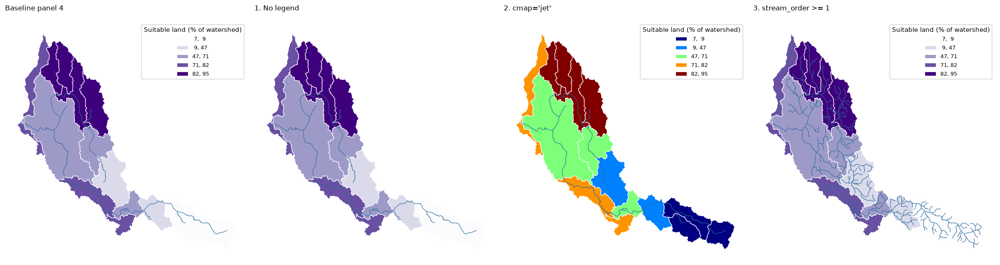

Streams drawn: 128 at order >= 3 vs. 422 at order >= 1


In [25]:
# [Python] Try it yourself — Section 2: variants of panel 4
def panel4(ax, title, legend=True, cmap="Purples", min_order=3):
    watersheds.plot(ax=ax, column="pct_suitable", cmap=cmap, edgecolor="white", linewidth=0.8,
                    scheme="natural_breaks", k=5, legend=legend,
                    legend_kwds={"title": "Suitable land (% of watershed)", "loc": "upper right",
                                 "fontsize": 8, "title_fontsize": 9, "fmt": "{:.0f}"} if legend else None)
    streams[streams["stream_order"] >= min_order].plot(ax=ax, color="#2b6c99", linewidth=0.7)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_axis_off()

fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
panel4(axes[0], "Baseline panel 4")
panel4(axes[1], "1. No legend", legend=False)
panel4(axes[2], "2. cmap='jet'", cmap="jet")
panel4(axes[3], "3. stream_order >= 1", min_order=1)
plt.tight_layout()
plt.show()
print("Streams drawn:", (streams["stream_order"] >= 3).sum(), "at order >= 3 vs.", (streams["stream_order"] >= 1).sum(), "at order >= 1")


**Answers — Section 2 "Try it yourself"**

1. **No legend.** Nothing tells the reader what the shades mean. Dark purple could be a lot or a little suitable land, and the class breaks and units are missing, so the map cannot be checked.
2. **`jet`.** The rainbow ramp is not perceptually ordered, and its bright cyan/yellow bands create apparent edges inside the data that the five classes never drew. Lightness does not rise steadily with value, so the reader cannot tell which class is higher.
3. **`stream_order >= 1`.** The map gets busier, not more informative. The many small headwater streams hide the watershed fill and the boundaries, and the main stems that carry the story are harder to pick out. For a watershed-level suitability map, order >= 3 is the better choice.


---
## Section 3 — Symbology: Match the Visual Variable to the Data

Symbology is the decision about **what you encode and how**. Get the pairing wrong and the map lies —
fluently, and with a straight face.

| Your data is… | Use | Not |
|---|---|---|
| A rate, ratio, or density (per km², percent of area) | Choropleth — fill colour | — |
| A raw count or magnitude (totals, sums) | **Graduated symbols** sized by value | ❌ Choropleth — you'll map polygon *size* |
| Categories with no order (land cover, species) | Unique values — distinct hues | ❌ A sequential ramp — invents a ranking |
| An ordered sequence (low → high; stream order) | Sequential ramp (`viridis`, `Purples`) or line width | ❌ A rainbow ramp — invents breaks |
| Divergence around a meaningful midpoint | Diverging ramp (`RdBu`), midpoint pinned | ❌ Sequential — hides the midpoint |

### The one that gets everyone

**Never map a raw count as a choropleth.** A big polygon has more of *everything* — more stream kilometres, more
parcels, more survey sites — because it's *big*. Colour the polygon by the count and you have drawn a map of polygon
area with extra steps.

Our watersheds make this concrete: Lake Washington–Sammamish River is more than twelve times the area of Rock Creek.
Run the next cell.

🟢 **`[Python]`**

In [6]:
# [Python] Raw count vs. normalized — the same data, the opposite conclusion
summary = (watersheds[["watershed_name", "area_km2", "stream_km", "drainage_density"]]
           .sort_values("stream_km", ascending=False))
print(summary.to_string(index=False))

by_raw     = summary["watershed_name"].tolist()
by_density = summary.sort_values("drainage_density", ascending=False)["watershed_name"].tolist()
top = by_raw[0]
print(f"\n{top}: #1 of 15 by raw stream km, #{by_density.index(top) + 1} of 15 by drainage density (km per km²).")
print("Two defensible-looking maps. Two opposite stories about where the streams are. Same data.")

                 watershed_name  area_km2  stream_km  drainage_density
Lake Washington-Sammamish River     460.8      163.7              0.36
                 Issaquah Creek     145.9       92.6              0.63
                     Bear Creek     121.9       68.2              0.56
       Taylor Creek-Cedar River      78.9       64.3              0.81
 Chester Morse Lake-Cedar River      87.3       60.7              0.70
       Madsen Creek-Cedar River     100.5       57.8              0.58
 Lake Sammamish-Sammamish River     115.3       56.1              0.49
     Bear Creek-Sammamish River     106.2       55.2              0.52
         Headwaters Cedar River      65.6       52.8              0.80
         Rock Creek-Cedar River      53.6       39.3              0.73
                      Rex River      59.1       33.8              0.57
                    North Creek      74.5       27.8              0.37
                    Swamp Creek      64.2       24.5              0.38
Shell 

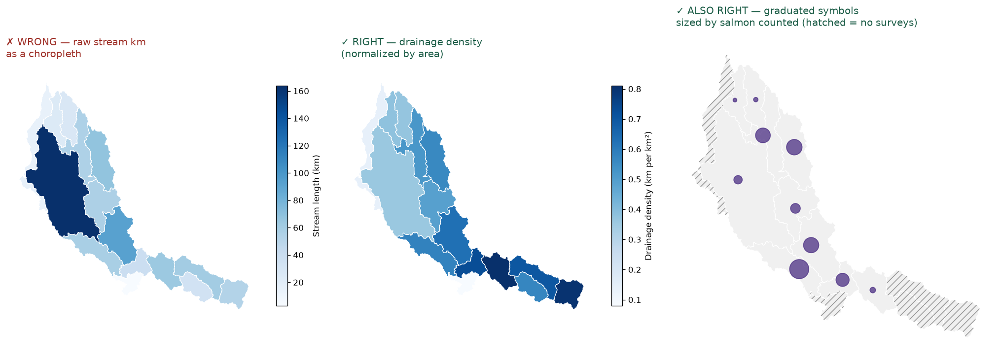

Left and centre use the SAME stream network and disagree about which watershed is stream-rich.
Only one of them answers the question 'where is the stream network densest?'


In [7]:
# [Python] Draw both maps side by side — and one honest alternative
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5))

# ── WRONG: raw total as a choropleth ────────────────────────────────────────
watersheds.plot(ax=axes[0], column="stream_km", cmap="Blues", edgecolor="white", linewidth=0.8,
                legend=True, legend_kwds={"shrink": 0.6, "label": "Stream length (km)"})
axes[0].set_title("✗ WRONG — raw stream km\nas a choropleth", loc="left", color="#9E2F27")

# ── RIGHT: normalize first ──────────────────────────────────────────────────
watersheds.plot(ax=axes[1], column="drainage_density", cmap="Blues", edgecolor="white", linewidth=0.8,
                legend=True, legend_kwds={"shrink": 0.6, "label": "Drainage density (km per km²)"})
axes[1].set_title("✓ RIGHT — drainage density\n(normalized by area)", loc="left", color="#1B5C46")

# ── ALSO RIGHT: keep the count, change the visual variable ──────────────────
# Salmon counted is a raw total → graduated symbols. Five watersheds have NO observations in this
# dataset — they get their own hatched class instead of silently looking like zero.
watersheds.plot(ax=axes[2], facecolor="0.94", edgecolor="white", linewidth=0.8)
watersheds[watersheds["salmon_counted"].isna()].plot(ax=axes[2], facecolor="none", edgecolor="0.6",
                                                     hatch="///", linewidth=0)
pts = watersheds.dropna(subset=["salmon_counted"]).copy()
pts["geometry"] = pts.representative_point()
pts.plot(ax=axes[2], markersize=pts["salmon_counted"] * 2, color="#4B2E83", alpha=0.75)
axes[2].set_title("✓ ALSO RIGHT — graduated symbols\nsized by salmon counted (hatched = no surveys)",
                  loc="left", color="#1B5C46")

for a in axes:
    a.set_axis_off()
plt.tight_layout(); plt.show()
print("Left and centre use the SAME stream network and disagree about which watershed is stream-rich.")
print("Only one of them answers the question 'where is the stream network densest?'")

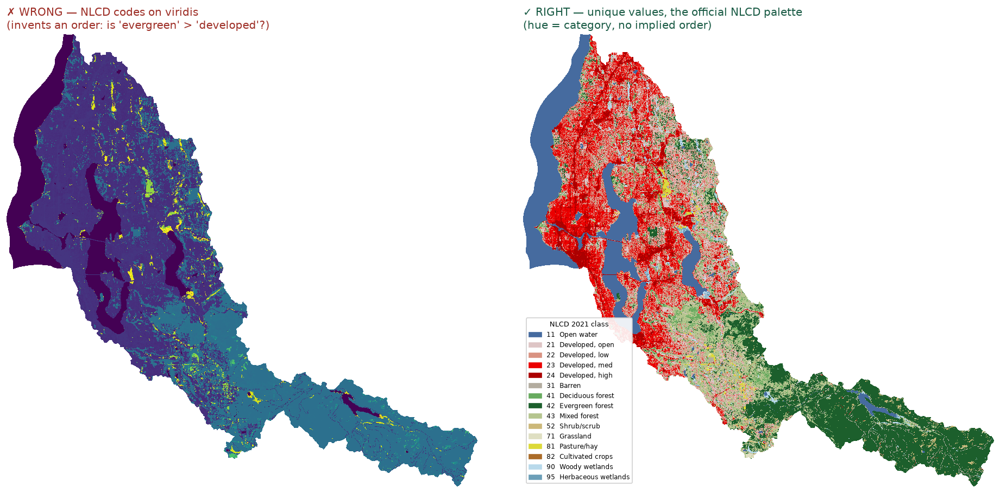

In [8]:
# [Python] Categories get distinct hues — NLCD land cover with its official palette vs. a sequential ramp
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

NLCD = {11: ("Open water", "#466b9f"), 21: ("Developed, open", "#dec5c5"), 22: ("Developed, low", "#d99282"),
        23: ("Developed, med", "#eb0000"), 24: ("Developed, high", "#ab0000"), 31: ("Barren", "#b3ac9f"),
        41: ("Deciduous forest", "#68ab5f"), 42: ("Evergreen forest", "#1c5f2c"), 43: ("Mixed forest", "#b5c58f"),
        52: ("Shrub/scrub", "#ccb879"), 71: ("Grassland", "#dfdfc2"), 81: ("Pasture/hay", "#dcd939"),
        82: ("Cultivated crops", "#ab6c28"), 90: ("Woody wetlands", "#b8d9eb"), 95: ("Herbaceous wetlands", "#6c9fb8"),
        12: ("Perennial ice/snow", "#d1def8")}
present = [c for c in sorted(NLCD) if (lc == c).any()]
lc_idx  = np.full(lc.shape, np.nan)
for k, c in enumerate(present):
    lc_idx[lc == c] = k

fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
axes[0].imshow(np.where(valid, lc, np.nan), cmap="viridis", interpolation="nearest")
axes[0].set_title("✗ WRONG — NLCD codes on viridis\n(invents an order: is 'evergreen' > 'developed'?)",
                  loc="left", color="#9E2F27")
cmap = ListedColormap([NLCD[c][1] for c in present])
axes[1].imshow(lc_idx, cmap=cmap, norm=BoundaryNorm(np.arange(len(present) + 1) - 0.5, len(present)),
               interpolation="nearest")
axes[1].legend(handles=[Patch(color=NLCD[c][1], label=f"{c}  {NLCD[c][0]}") for c in present],
               loc="lower left", fontsize=7, title="NLCD 2021 class", title_fontsize=8, framealpha=0.9)
axes[1].set_title("✓ RIGHT — unique values, the official NLCD palette\n(hue = category, no implied order)",
                  loc="left", color="#1B5C46")
for a in axes:
    a.set_axis_off()
plt.tight_layout(); plt.show()

🔵 **`[R]`**

                  watershed_name area_km2 stream_km drainage_density
 Lake Washington-Sammamish River    460.8     163.7             0.36
                  Issaquah Creek    145.9      92.6             0.63
                      Bear Creek    121.9      68.2             0.56
        Taylor Creek-Cedar River     78.9      64.3             0.81
  Chester Morse Lake-Cedar River     87.3      60.7             0.70
        Madsen Creek-Cedar River    100.5      57.8             0.58
  Lake Sammamish-Sammamish River    115.3      56.1             0.49
      Bear Creek-Sammamish River    106.2      55.2             0.52
          Headwaters Cedar River     65.6      52.8             0.80
          Rock Creek-Cedar River     53.6      39.3             0.73
                       Rex River     59.1      33.8             0.57
                     North Creek     74.5      27.8             0.37
                     Swamp Creek     64.2      24.5             0.38
 Shell Creek-Frontal Puget Sound  

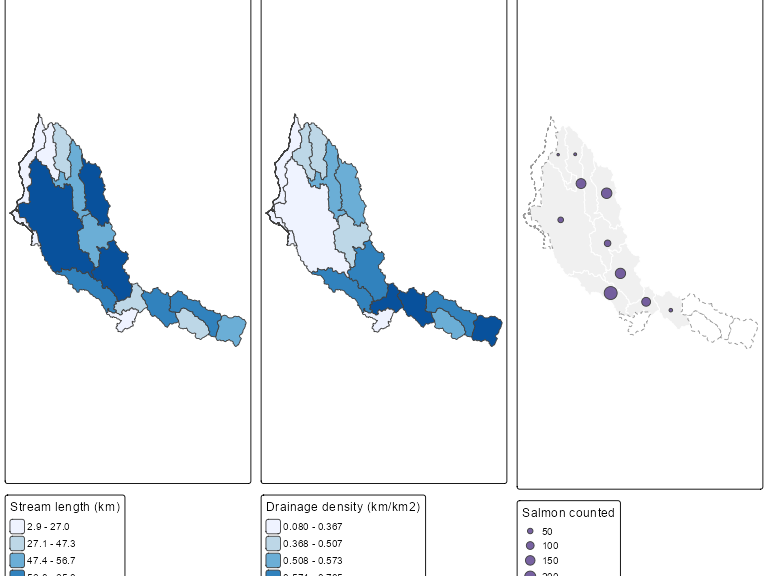

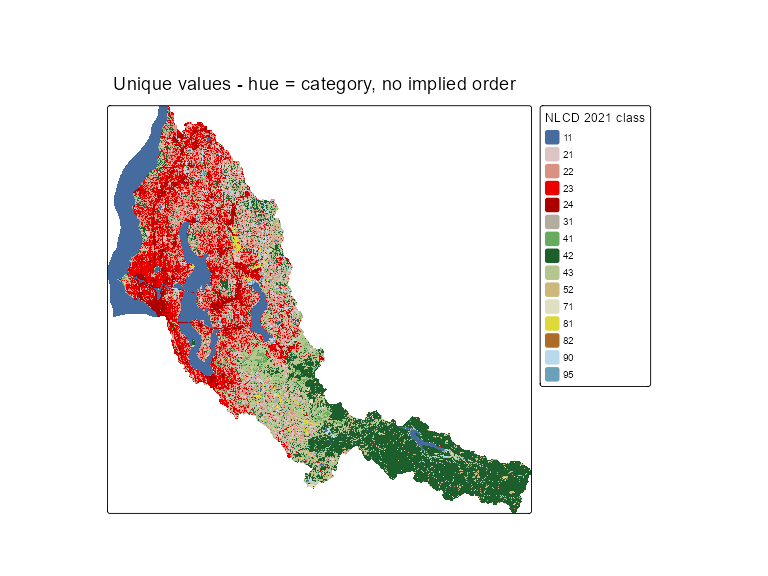

In [ ]:
# [R] Raw count vs. normalized with tmap
library(tmap)

# ── The ranking check — the same inversion you saw in Python ────────────────
tab <- st_drop_geometry(watersheds)[order(-watersheds$stream_km),
                                    c("watershed_name", "area_km2", "stream_km", "drainage_density")]
print(tab, row.names = FALSE)
top <- tab$watershed_name[1]
cat("\n", top, ": #1 by raw stream km, #", which(tab$watershed_name[order(-tab$drainage_density)] == top),
    " by drainage density\n", sep = "")

# ── ✗ WRONG — raw total as a choropleth ────────────────────────────────────
m_wrong <- tm_shape(watersheds) +
  tm_polygons(fill = "stream_km", fill.scale = tm_scale_intervals(style = "quantile", values = "brewer.blues"),
              fill.legend = tm_legend(title = "Stream length (km)")) +
  tm_title("WRONG - raw total choropleth")

# ── ✓ RIGHT — normalize before you map ─────────────────────────────────────
m_right <- tm_shape(watersheds) +
  tm_polygons(fill = "drainage_density",
              fill.scale = tm_scale_intervals(style = "quantile", values = "brewer.blues"),
              fill.legend = tm_legend(title = "Drainage density (km/km2)")) +
  tm_title("RIGHT - normalized")

# ── ✓ ALSO RIGHT — keep the count, change the visual variable; show the gaps ─
cent <- st_point_on_surface(watersheds[!is.na(watersheds$salmon_counted), ])
m_symb <- tm_shape(watersheds) +
  tm_polygons(fill = "grey94", col = "white") +
  tm_shape(watersheds[is.na(watersheds$salmon_counted), ]) +
  tm_polygons(fill = "white", col = "grey60", lty = "dashed") +
  tm_shape(cent) +
  tm_symbols(size = "salmon_counted", fill = "#4B2E83", fill_alpha = 0.75,
             size.legend = tm_legend(title = "Salmon counted")) +
  tm_title("ALSO RIGHT - graduated symbols (dashed = no surveys)")

tmap_arrange(m_wrong, m_right, m_symb, nrow = 1)

# ── Categories: NLCD with its official palette — a named vector of colours ──
nlcd_cols <- c("11" = "#466b9f", "21" = "#dec5c5", "22" = "#d99282", "23" = "#eb0000", "24" = "#ab0000",
               "31" = "#b3ac9f", "41" = "#68ab5f", "42" = "#1c5f2c", "43" = "#b5c58f", "52" = "#ccb879",
               "71" = "#dfdfc2", "81" = "#dcd939", "82" = "#ab6c28", "90" = "#b8d9eb", "95" = "#6c9fb8",
               "12" = "#d1def8")
tm_shape(as.factor(nlcd)) +
  tm_raster(col.scale = tm_scale_categorical(values = nlcd_cols),
            col.legend = tm_legend(title = "NLCD 2021 class")) +
  tm_title("Unique values - hue = category, no implied order")

### 🔧 Try it yourself — symbology ⭐ *(extra credit — optional)*

1. Map `salmon_counted` as a choropleth, then map `salmon_per_km`. Does the ranking change the way stream km did?
   What happens to the five unsurveyed watersheds in each version if you leave out `missing_kwds`?
2. The graduated-symbol panel multiplies by 2 (`markersize=pts["salmon_counted"] * 2`). That multiplier is a
   cartographic decision, not a technicality — try 0.5 and 8. At what point does the map stop being readable?
3. **The professional question:** the council has both stream maps in front of them. Which do you show, and what exactly
   do you say when someone asks why the other one looks different? Write the two sentences out. That sentence is part of the
   Section 9 extra credit.

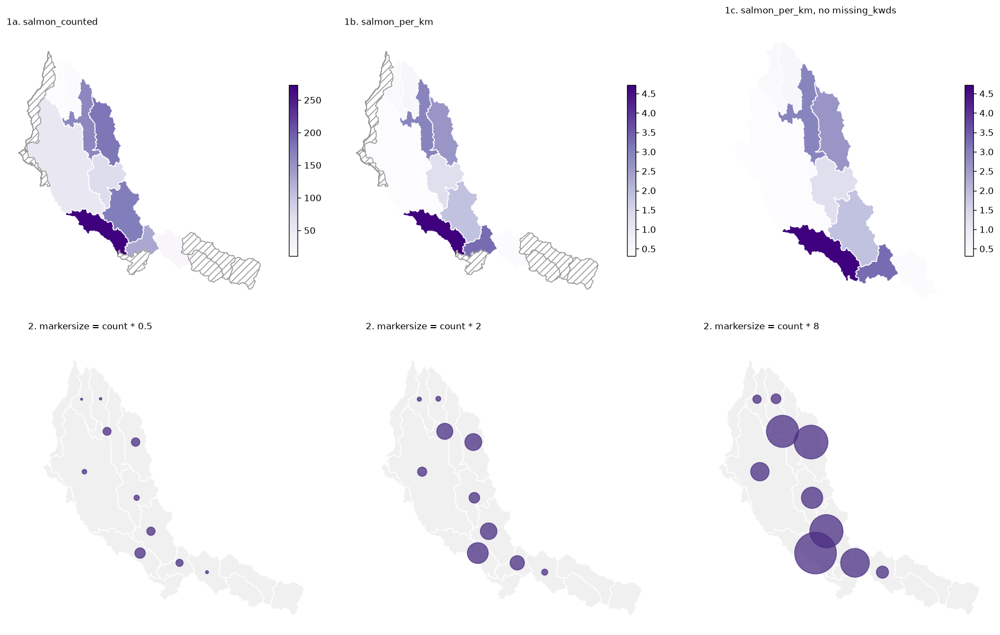

,watershed_name,salmon_counted,stream_km,salmon_per_km,rank_count,rank_rate
6,Madsen Creek-Cedar River,273.0,57.8,4.72,1,1
9,Bear Creek,179.0,68.2,2.62,2,4
7,Issaquah Creek,173.0,92.6,1.87,3,5
12,Bear Creek-Sammamish River,162.0,55.2,2.93,4,3
4,Rock Creek-Cedar River,129.0,39.3,3.28,5,2
8,Lake Sammamish-Sammamish River,71.0,56.1,1.27,6,6
13,Lake Washington-Sammamish River,53.0,163.7,0.32,7,10
3,Taylor Creek-Cedar River,23.0,64.3,0.36,8,9
10,North Creek,15.0,27.8,0.54,9,7
11,Swamp Creek,11.0,24.5,0.45,10,8


In [26]:
# [Python] Try it yourself — Section 3
miss = {"color": "white", "edgecolor": "0.6", "hatch": "///", "label": "No surveys"}
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# 1. Choropleth of the count vs. the rate; the last panel drops missing_kwds
for ax, col, kw, ttl in [(axes[0, 0], "salmon_counted", miss, "1a. salmon_counted"),
                         (axes[0, 1], "salmon_per_km", miss, "1b. salmon_per_km"),
                         (axes[0, 2], "salmon_per_km", None, "1c. salmon_per_km, no missing_kwds")]:
    watersheds.plot(ax=ax, column=col, cmap="Purples", edgecolor="white", legend=True,
                    legend_kwds={"shrink": 0.6}, missing_kwds=kw)
    ax.set_title(ttl, loc="left", fontsize=10)

# 2. Graduated-symbol multiplier: 0.5, 2, 8
pts = watersheds.dropna(subset=["salmon_counted"]).copy()
pts["geometry"] = pts.representative_point()
for ax, mult in zip(axes[1], [0.5, 2, 8]):
    watersheds.plot(ax=ax, facecolor="0.94", edgecolor="white")
    pts.plot(ax=ax, markersize=pts["salmon_counted"] * mult, color="#4B2E83", alpha=0.75)
    ax.set_title(f"2. markersize = count * {mult}", loc="left", fontsize=10)

for ax in axes.ravel():
    ax.set_axis_off()
plt.tight_layout()
plt.show()

ranks = watersheds.dropna(subset=["salmon_counted"]).assign(
    rank_count=lambda d: d["salmon_counted"].rank(ascending=False).astype(int),
    rank_rate=lambda d: d["salmon_per_km"].rank(ascending=False).astype(int),
)[["watershed_name", "salmon_counted", "stream_km", "salmon_per_km", "rank_count", "rank_rate"]]
ranks.sort_values("rank_count")


**Answers — Section 3 "Try it yourself"**

1. **Count vs. rate.** The ranking changes, but less than it did for stream km. Madsen Creek–Cedar River is #1 on both. Below that the order shifts: Rock Creek–Cedar River moves from 5th by count to 2nd by rate, and Bear Creek–Sammamish River from 4th to 3rd. Lake Washington–Sammamish River falls from 7th to last (0.32 per km). Its 164 km of streams dilute a modest count, the same size effect as before. Without `missing_kwds`, GeoPandas silently leaves the five unsurveyed watersheds out of the map, so they look like empty space or background rather than "not surveyed" (see panel 1c). Blank is not zero, and the hatched "No surveys" class says so.
2. **Symbol multiplier.** At 0.5 the symbols are too small to compare, and the larger counts are barely distinguishable from the small ones. At 2 the sizes are readable and the symbols don't overlap. At 8 the largest circles swallow neighbouring watersheds and cover the geography, and the smaller ones are lost beneath them. The map stops being readable somewhere between about 2 and 8. The multiplier should be chosen so the largest symbol is clearly bigger than the smallest without hiding the base map.
3. **What to show the council.** Show the drainage-density map. Suggested wording: "Drainage density is stream length divided by watershed area, so it compares watersheds fairly regardless of size. The raw-kilometre map mostly shows which watersheds are biggest. Lake Washington–Sammamish River has the most stream km only because it is more than twelve times the size of Rock Creek."


---
## Section 4 — Classification: Same Data, Five Stories

Classification is how continuous values become classes. **The method is an argument you are making on the
reader's behalf** — usually without telling them.

The layer for this section is the 800 monitoring sites in `monitoring_sites.csv` — a summer water temperature (°C) at
each site. Lots of values, a skewed distribution, and a set of thresholds that actually matter: Washington's aquatic-life
temperature criteria (WAC 173-201A-200) — **12 °C** char spawning and rearing, **16 °C** core summer salmonid habitat,
**17.5 °C** salmonid spawning, rearing and migration, **20 °C** warm-water species.

> The site temperatures are single synthetic readings placed on the real WRIA 8 streams; the criteria are written for the
> 7-day average of daily maximums (7-DADMax). We're borrowing the thresholds, not making a compliance call.

| Method | `scheme=` / `style=` | What it does | Use it when | The catch |
|---|---|---|---|---|
| Equal interval | `equal_interval` / `equal` | Cuts the *range* into n equal bins | Values are evenly spread; bins are intuitive | Skewed data → most features in one class |
| Quantile | `quantiles` / `quantile` | Equal *count* per class | You want visual contrast | Always looks good. Invents differences where none exist |
| Natural breaks | `natural_breaks` / `jenks` | Minimizes within-class variance | Clustered data, single map | **Breaks are computed from this dataset only** |
| Standard deviation | `std_mean` / `sd` | Classes by distance from the mean | Showing deviation from typical | Needs a roughly normal distribution |
| Manual / fixed | `user_defined` / `fixed` | You supply the breaks | Regulatory thresholds; **any comparison** | You have to justify them — which is the point |

> ⚠ **Spelling trap:** GeoPandas wants `scheme="quantiles"` (plural); tmap wants `style = "quantile"` (singular).
> Each one rejects the other's spelling.

### The one that gets everyone

**Jenks is not "the best."** Jenks minimizes within-class variance *for the dataset you handed it*. That is
not the same as being the most honest, and it is actively wrong for comparison.

> **Comparing two maps — two years, two sub-basins, before/after?**
> The breaks must be **identical and manual**. Natural breaks recomputed per map means the two legends
> mean different things, and the comparison is meaningless. It will look completely fine. Nobody will catch
> it in review. That's what makes it dangerous.

🟢 **`[Python]`**

In [9]:
# [Python] The same field, five methods, five stories
import mapclassify

vals = sites["temp_c"]
WAC_BREAKS = [12, 16, 17.5, 20]          # WAC 173-201A-200 aquatic-life criteria, °C

methods = {
    "Equal interval":  mapclassify.EqualInterval(vals, k=5),
    "Quantile":        mapclassify.Quantiles(vals, k=5),
    "Natural breaks":  mapclassify.NaturalBreaks(vals, k=5),
    "Std. deviation":  mapclassify.StdMean(vals),
    "Manual (WAC)":    mapclassify.UserDefined(vals, bins=WAC_BREAKS),
}
for name, m in methods.items():
    print(f"{name:15} breaks: {', '.join(f'{b:.1f}' for b in m.bins)}")
    print(f"{'':15} counts: {[int(c) for c in m.counts]}")
print(f"\nSame {len(vals)} sites. Five different sets of breaks. Five different maps.")
print("Any of them can be defended. Only one of them is tied to something the council already uses.")

Equal interval  breaks: 9.6, 12.6, 15.7, 18.7, 21.7
                counts: [24, 100, 193, 408, 75]
Quantile        breaks: 13.5, 15.7, 16.8, 17.9, 21.7
                counts: [160, 170, 152, 160, 158]
Natural breaks  breaks: 11.2, 13.9, 16.0, 17.9, 21.7
                counts: [68, 123, 176, 275, 158]
Std. deviation  breaks: 10.2, 13.0, 18.4, 21.1, 21.7
                counts: [37, 99, 559, 103, 2]
Manual (WAC)    breaks: 12.0, 16.0, 17.5, 20.0, 21.7
                counts: [95, 272, 212, 210, 11]

Same 800 sites. Five different sets of breaks. Five different maps.
Any of them can be defended. Only one of them is tied to something the council already uses.


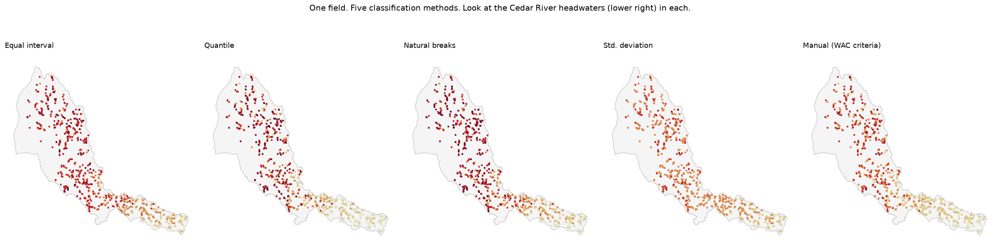

If you can see the upper Cedar change character across these panels — that's the lesson.
Nothing about the data changed. Only the argument did.


In [10]:
# [Python] Draw all five — this is the cell to look at, not the numbers above
fig, axes = plt.subplots(1, 5, figsize=(21, 5.6))
specs = [("Equal interval", "equal_interval", {}),
         ("Quantile", "quantiles", {}),                     # plural in GeoPandas
         ("Natural breaks", "natural_breaks", {}),
         ("Std. deviation", "std_mean", {}),
         ("Manual (WAC criteria)", "user_defined", {"classification_kwds": {"bins": WAC_BREAKS}})]

for ax, (title, scheme, extra) in zip(axes, specs):
    wria8.plot(ax=ax, facecolor="0.96", edgecolor="0.7", linewidth=0.6)
    sites.plot(ax=ax, column="temp_c", cmap="YlOrRd", scheme=scheme, k=5, markersize=7,
               edgecolor="0.3", linewidth=0.15, **extra)
    ax.set_title(title, fontsize=11, loc="left")
    ax.set_axis_off()
plt.suptitle("One field. Five classification methods. Look at the Cedar River headwaters (lower right) in each.",
             y=1.02, fontsize=12)
plt.tight_layout(); plt.show()
print("If you can see the upper Cedar change character across these panels — that's the lesson.")
print("Nothing about the data changed. Only the argument did.")

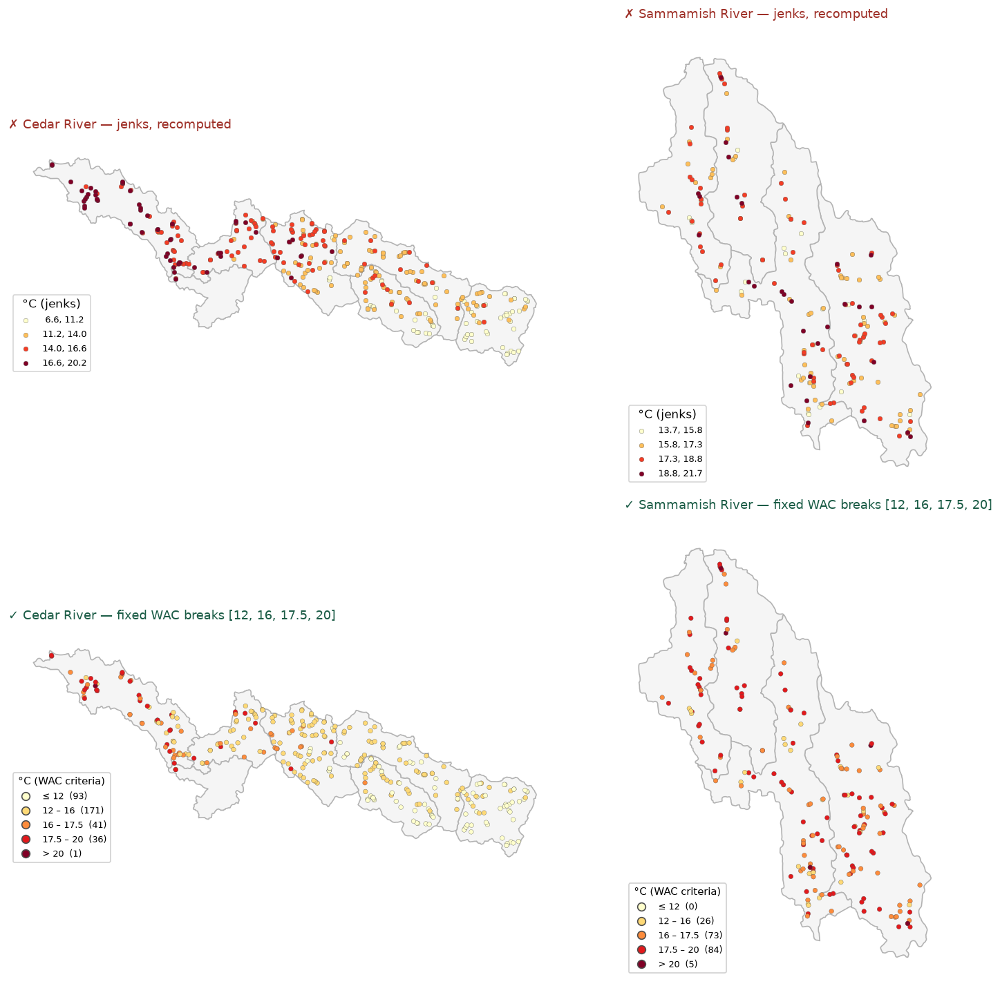

Cedar River      jenks breaks: [11.  13.8 16.5 20.2]   | sites above 16 °C: 23%
Sammamish River  jenks breaks: [15.8 17.3 18.7 21.7]   | sites above 16 °C: 86%

Top row: the same colour means a different temperature in each panel. Both look equally 'hot'.
Bottom row: the same colour means the same temperature. Now the difference is visible — and true.


In [11]:
# [Python] Fixed breaks: the only defensible choice for a comparison map
# Scenario: the council wants the Cedar River sub-basin next to the Sammamish River sub-basin.
from matplotlib.lines import Line2D

def plot_fixed_points(gdf, ax, column, bins, cmap="YlOrRd", size=16, title=None):
    """Fixed-break point map: colour i ALWAYS means class i, and the legend lists every class — even empty ones.
    (GeoPandas 1.x can't draw an empty point class when markersize is set, so we draw the legend ourselves.
    That's also the honest legend for a comparison: '(0)' is information.)"""
    edges  = list(bins)
    idx    = np.digitize(gdf[column], edges, right=True)            # class 0 … len(edges)
    colors = plt.get_cmap(cmap)(np.linspace(0, 1, len(edges) + 1))
    gdf.plot(ax=ax, color=colors[idx], markersize=size, edgecolor="0.3", linewidth=0.2)
    labels = [f"≤ {edges[0]:g}"] + [f"{a:g} – {b:g}" for a, b in zip(edges, edges[1:])] + [f"> {edges[-1]:g}"]
    counts = np.bincount(idx, minlength=len(labels))
    ax.legend(handles=[Line2D([], [], marker="o", ls="", markersize=7, markerfacecolor=c, markeredgecolor="0.3",
                              label=f"{lab}  ({n})") for c, lab, n in zip(colors, labels, counts)],
              title=title, loc="lower left", fontsize=8, title_fontsize=9, framealpha=0.9)

pair = [("Cedar River", sites[sites["subbasin"] == "Cedar River"]),
        ("Sammamish River", sites[sites["subbasin"] == "Sammamish River"])]

fig, axes = plt.subplots(2, 2, figsize=(13, 12))
# ── ✗ WRONG — natural breaks recomputed per panel ───────────────────────────
for ax, (name, gdf) in zip(axes[0], pair):
    watersheds[watersheds["subbasin"] == name].plot(ax=ax, facecolor="0.96", edgecolor="0.7")
    gdf.plot(ax=ax, column="temp_c", cmap="YlOrRd", scheme="natural_breaks", k=4, markersize=16,
             edgecolor="0.3", linewidth=0.2, legend=True,
             legend_kwds={"fontsize": 8, "loc": "lower left", "title": "°C (jenks)", "fmt": "{:.1f}"})
    ax.set_title(f"✗ {name} — jenks, recomputed", loc="left", color="#9E2F27", fontsize=11)
# ── ✓ RIGHT — identical manual breaks, shared legend meaning ────────────────
for ax, (name, gdf) in zip(axes[1], pair):
    watersheds[watersheds["subbasin"] == name].plot(ax=ax, facecolor="0.96", edgecolor="0.7")
    plot_fixed_points(gdf, ax, "temp_c", WAC_BREAKS, title="°C (WAC criteria)")
    ax.set_title(f"✓ {name} — fixed WAC breaks {WAC_BREAKS}", loc="left", color="#1B5C46", fontsize=11)
for a in axes.ravel():
    a.set_axis_off()
plt.tight_layout(); plt.show()

for name, gdf in pair:
    print(f"{name:16} jenks breaks: {np.round(mapclassify.NaturalBreaks(gdf['temp_c'], k=4).bins, 1)}"
          f"   | sites above 16 °C: {100 * (gdf['temp_c'] > 16).mean():.0f}%")
print("\nTop row: the same colour means a different temperature in each panel. Both look equally 'hot'.")
print("Bottom row: the same colour means the same temperature. Now the difference is visible — and true.")

🔵 **`[R]`**

equal     breaks: 6.6, 9.6, 12.6, 15.7, 18.7, 21.7
quantile  breaks: 6.6, 13.5, 15.7, 16.8, 17.9, 21.7
jenks     breaks: 6.6, 11.2, 14, 16.1, 17.9, 21.7
sd        breaks: 4.8, 7.5, 10.2, 13, 15.7, 18.4, 21.1, 23.9

Same sites. Four different sets of breaks. Four different maps.


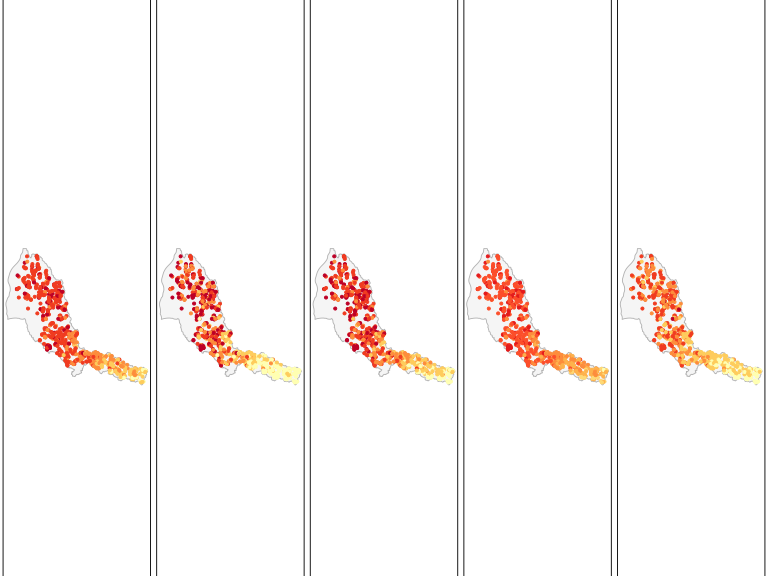

Cedar River      jenks: 6.6, 11.2, 14, 16.6, 20.2 | above 16 C: 23%
Sammamish River  jenks: 13.7, 15.8, 17.3, 18.8, 21.7 | above 16 C: 86%
That gap is the size of the error in a jenks comparison map.


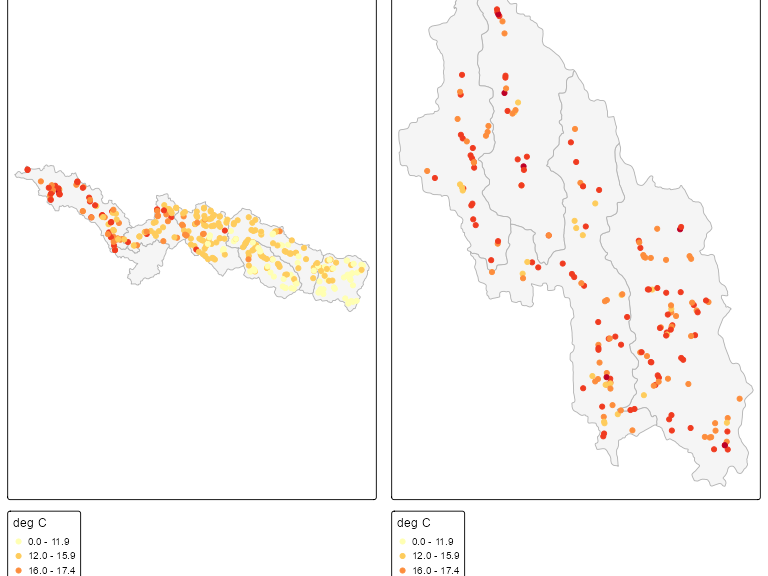

In [ ]:
# [R] Classification with tmap — same methods, same names (tmap spells it "quantile", singular)
library(tmap)
library(classInt)

vals <- sites$temp_c
WAC_BREAKS <- c(12, 16, 17.5, 20)        # WAC 173-201A-200 aquatic-life criteria, deg C
for (s in c("equal", "quantile", "jenks", "sd")) {
  brks <- classIntervals(vals, n = 5, style = s)$brks
  cat(sprintf("%-9s breaks: %s\n", s, paste(round(brks, 1), collapse = ", ")))
}
cat("\nSame sites. Four different sets of breaks. Four different maps.\n")

maps <- lapply(c("equal", "quantile", "jenks", "sd"), function(s) {
  tm_shape(wria8) + tm_polygons(fill = "grey96", col = "grey70") +
  tm_shape(sites) +
    tm_dots(fill = "temp_c", size = 0.25,
            fill.scale  = tm_scale_intervals(style = s, n = 5, values = "brewer.yl_or_rd"),
            fill.legend = tm_legend_hide()) +
    tm_title(paste0("style = '", s, "'"))
})
m_fixed <- tm_shape(wria8) + tm_polygons(fill = "grey96", col = "grey70") +
  tm_shape(sites) +
  tm_dots(fill = "temp_c", size = 0.25,
          fill.scale  = tm_scale_intervals(style = "fixed", breaks = c(0, WAC_BREAKS, 25),
                                           values = "brewer.yl_or_rd"),
          fill.legend = tm_legend_hide()) +
  tm_title("style = 'fixed' (WAC criteria)")
do.call(tmap_arrange, c(maps, list(m_fixed), list(nrow = 1)))

# ── The comparison map: identical breaks in BOTH panels ────────────────────
cmp <- lapply(c("Cedar River", "Sammamish River"), function(sb) {
  tm_shape(watersheds[watersheds$subbasin == sb, ]) + tm_polygons(fill = "grey96", col = "grey70") +
  tm_shape(sites[sites$subbasin %in% sb, ]) +
    tm_dots(fill = "temp_c", size = 0.4,
            fill.scale  = tm_scale_intervals(style = "fixed", breaks = c(0, WAC_BREAKS, 25),
                                             values = "brewer.yl_or_rd"),
            fill.legend = tm_legend(title = "deg C")) +
    tm_title(paste(sb, "- fixed WAC breaks"))
})
tmap_arrange(cmp[[1]], cmp[[2]], nrow = 1)

# Jenks recomputed per sub-basin — how far apart are the breaks?
for (sb in c("Cedar River", "Sammamish River")) {
  v <- sites$temp_c[sites$subbasin %in% sb]
  cat(sprintf("%-16s jenks: %s | above 16 C: %.0f%%\n", sb,
              paste(round(classIntervals(v, 4, style = "jenks")$brks, 1), collapse = ", "), 100 * mean(v > 16)))
}
cat("That gap is the size of the error in a jenks comparison map.\n")

### 🔧 Try it yourself — classification ⭐ *(extra credit — optional)*

1. Change `k=5` to `k=3` and `k=7` in the five-panel figure. Which methods are most sensitive to the class
   count? (Watch quantile.)
2. Run `mapclassify.Quantiles(vals, k=5).counts` — every class has the same count *by construction*. Now
   explain why a quantile map always looks well-balanced even when the data isn't.
3. Compute Jenks breaks for the Cedar River sites alone and for all 800 sites. How far apart are they? That gap
   is the size of the error in the ✗ panels above.
4. **The defensible answer:** pick the method you'd take to the council and write one sentence starting
   "I used ___ breaks because ___." If your sentence is "because it looked best," try again.

In [27]:
# [Python] Try it yourself — Section 4
# 1. Sensitivity to class count: breaks and class sizes for k = 3, 5, 7
for k in (3, 5, 7):
    print(f"k = {k}")
    for name, cls in {"Equal interval": mapclassify.EqualInterval, "Quantile": mapclassify.Quantiles,
                      "Natural breaks": mapclassify.NaturalBreaks}.items():
        m = cls(vals, k=k)
        print(f"  {name:15} breaks {np.round(m.bins, 1)}  counts {m.counts.astype(int).tolist()}")
print(f"\nStd. deviation ignores k: breaks {np.round(mapclassify.StdMean(vals).bins, 1)}")

# 2. Quantile counts by construction vs. how spread out the values are inside each class
q = mapclassify.Quantiles(vals, k=5)
print("\nQuantile counts:", q.counts.astype(int).tolist())
print("Class ranges (°C):", [f"{lo:.1f}–{hi:.1f}" for lo, hi in
      zip([vals.min(), *q.bins[:-1]], q.bins)])
print(f"Skew of temp_c: {vals.skew():.2f}")

# 3. Jenks on Cedar River sites vs. all 800 sites
cedar = sites.loc[sites["subbasin"] == "Cedar River", "temp_c"]
jk_all, jk_cedar = (mapclassify.NaturalBreaks(v, k=5).bins for v in (vals, cedar))
print("\nJenks, all sites   :", np.round(jk_all, 1))
print("Jenks, Cedar sites :", np.round(jk_cedar, 1))
print("Difference (°C)    :", np.round(jk_cedar - jk_all, 1))


k = 3
  Equal interval  breaks [11.6 16.7 21.7]  counts [84, 369, 347]
  Quantile        breaks [15.1 17.2 21.7]  counts [276, 265, 259]
  Natural breaks  breaks [13.  16.4 21.7]  counts [141, 286, 373]
k = 5
  Equal interval  breaks [ 9.6 12.6 15.7 18.7 21.7]  counts [24, 100, 193, 408, 75]
  Quantile        breaks [13.5 15.7 16.8 17.9 21.7]  counts [160, 170, 152, 160, 158]
  Natural breaks  breaks [11.2 14.  16.2 18.  21.7]  counts [68, 129, 201, 255, 147]
k = 7
  Equal interval  breaks [ 8.8 10.9 13.1 15.2 17.4 19.5 21.7]  counts [13, 47, 81, 142, 273, 217, 27]
  Quantile        breaks [12.5 14.5 15.9 16.7 17.5 18.4 21.7]  counts [122, 107, 125, 116, 109, 106, 115]
  Natural breaks  breaks [ 9.5 11.6 13.5 15.2 16.8 18.3 21.7]  counts [23, 61, 80, 119, 199, 203, 115]

Std. deviation ignores k: breaks [10.2 13.  18.4 21.1 21.7]

Quantile counts: [160, 170, 152, 160, 158]
Class ranges (°C): ['6.6–13.5', '13.5–15.7', '15.7–16.8', '16.8–17.9', '17.9–21.7']
Skew of temp_c: -0.80

Jenks, 

**Answers — Section 4 "Try it yourself"**

1. **Class count.** Quantile is the most sensitive: its class sizes stay equal, so its breaks shift every time k changes (the first break goes from 15.1 °C at k=3 to 12.5 °C at k=7). Equal interval keeps the same class width but its class counts swing widely (for example 408 sites in one class at k=5 and 273 at k=7). Natural breaks moves least in the middle of the range but still re-draws the class boundaries each time. Std. deviation ignores k entirely. For all three, the count of classes is another argument you make for the reader.
2. **Quantile counts.** The counts are `[160, 170, 152, 160, 158]`, equal by construction, so the map always looks balanced. The temperature data are left-skewed (skew about -0.8) and cluster at 16–18 °C. Quantile spends many classes on that dense middle and puts the whole sparse cool tail (6.6 to 13.5 °C) into a single class. A 0.2 °C difference between two sites can fall in different classes while a 7 °C range sits in one. The legend looks even, but the class widths are not.
3. **Jenks gap.** Cedar-only breaks are 0.6 to 1.5 °C below the all-sites breaks: `[10.6, 12.8, 14.9, 17.1, 20.2]` against `[11.2, 14.0, 16.1, 17.9, 21.7]`. A colour in a Cedar-only map therefore means a different temperature than the same colour in the basin-wide map. That gap is the size of the error in a Jenks comparison map, which is why comparisons need identical manual breaks such as the WAC criteria.


---
## Section 5 — Cartographic Elements: What Makes a Map Verifiable

A map is a **claim about the world**. These elements are what let a reader check the claim instead of
taking it on trust.

| Element | Why it's non-negotiable |
|---|---|
| **Legend with units** | "Suitability" means nothing. "Suitable land (% of watershed: slope < 15 %, elevation < 1000 m, not open water)" is checkable. |
| **The NoData class** | If 5 of 15 watersheds have no salmon surveys, that must be *visible*. Silence implies zero. |
| **Title** | States the claim in words, so the reader knows what they're looking at. |
| **Scale bar** | Distance. Required for print; largely redundant on a zoomable web map. |
| **North arrow** | Only when rotation isn't obvious. A north-up map doesn't need one. |
| **Credits: source, vintage, CRS, author** | This is what makes the map survive the room. When someone asks "what projection is this, and does it distort area?" — the answer is already on the map. |

ArcGIS Pro's Layout view hands you most of this for free. In matplotlib **every one of these is a line of
code you have to write.** That's the cost of the control.

🟢 **`[Python]`**

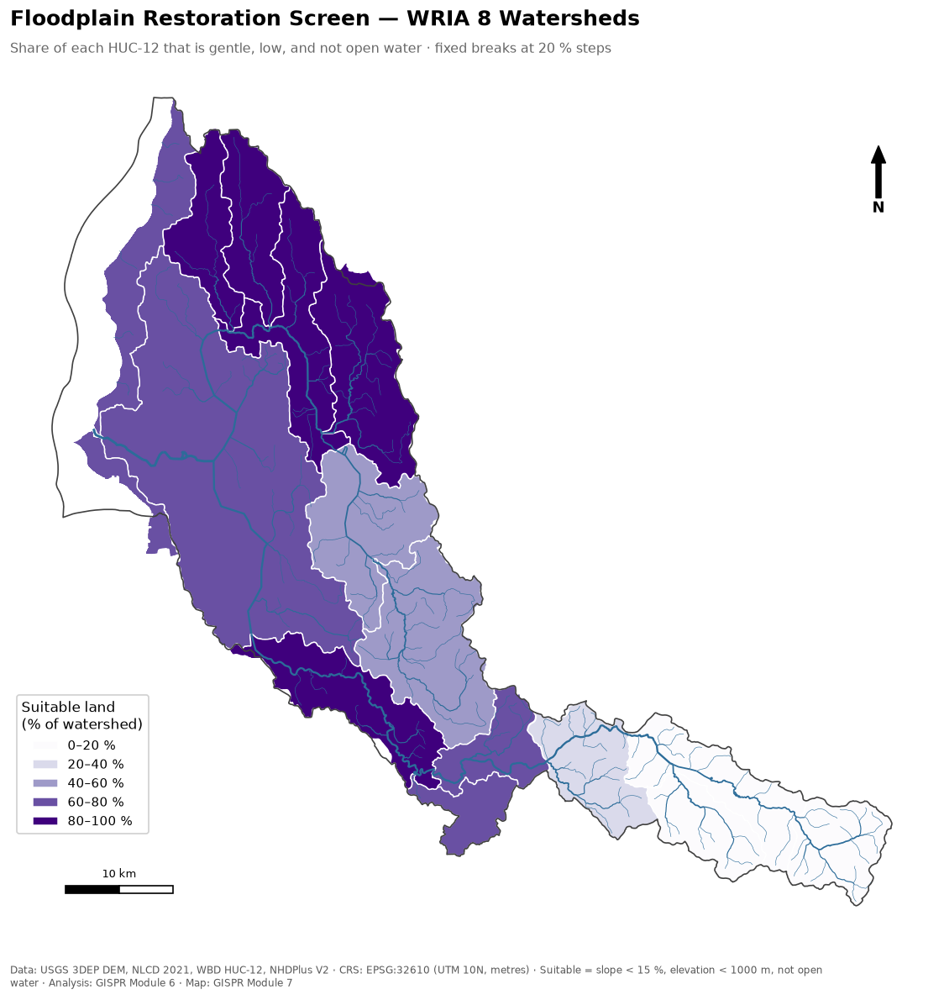

Every element above answers a question a reviewer would otherwise have to ask you in person.


In [12]:
# [Python] The full furniture — reusable helpers you carry into Module 8
from matplotlib.patches import Rectangle

SUIT_BINS   = [20, 40, 60, 80, 100]                                   # fixed, round, explainable
SUIT_LABELS = ["0–20 %", "20–40 %", "40–60 %", "60–80 %", "80–100 %"]
CREDITS = ("Data: USGS 3DEP DEM, NLCD 2021, WBD HUC-12, NHDPlus V2 · CRS: EPSG:32610 (UTM 10N, metres) · "
           "Suitable = slope < 15 %, elevation < 1000 m, not open water · Analysis: GISPR Module 6 · Map: GISPR Module 7")

def add_scale_bar(ax, length_m=10000, label=None, loc=(0.06, 0.06), height_frac=0.008):
    """Two-tone scale bar. Assumes a projected CRS in metres — another reason we map in EPSG:32610."""
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    bx, by, bh = x0 + loc[0] * (x1 - x0), y0 + loc[1] * (y1 - y0), (y1 - y0) * height_frac
    ax.add_patch(Rectangle((bx, by), length_m / 2, bh, facecolor="black", edgecolor="black", zorder=5))
    ax.add_patch(Rectangle((bx + length_m / 2, by), length_m / 2, bh, facecolor="white", edgecolor="black", zorder=5))
    ax.text(bx + length_m / 2, by + bh * 2.2, label or f"{length_m / 1000:.0f} km", ha="center", fontsize=8, zorder=5)

def add_north_arrow(ax, loc=(0.94, 0.90)):
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    x, y = x0 + loc[0] * (x1 - x0), y0 + loc[1] * (y1 - y0)
    ax.annotate("N", xy=(x, y), xytext=(x, y - 0.07 * (y1 - y0)), ha="center", va="center", fontsize=11,
                fontweight="bold", arrowprops=dict(facecolor="black", width=3.5, headwidth=10), zorder=5)

def add_credits(ax, text, fontsize=7):
    """Credits under the map, wrapped to the map's width so they never run off the figure."""
    import textwrap
    width_in = ax.get_position().width * ax.figure.get_figwidth()            # map width in inches
    chars = max(40, int(width_in * 72 / (0.55 * fontsize)))                  # ~0.55 em per character
    ax.text(0, -0.02, textwrap.fill(text, chars), transform=ax.transAxes, va="top", fontsize=fontsize, color="0.35")

fig, ax = plt.subplots(figsize=(11, 10))
watersheds.plot(ax=ax, column="pct_suitable", cmap="Purples", scheme="user_defined",
                classification_kwds={"bins": SUIT_BINS}, edgecolor="white", linewidth=0.9, legend=True,
                legend_kwds={"title": "Suitable land\n(% of watershed)", "labels": SUIT_LABELS, "loc": "lower left",
                             "bbox_to_anchor": (0.0, 0.12),
                             "fontsize": 9, "title_fontsize": 10, "frameon": True, "framealpha": 0.92})
streams.plot(ax=ax, color="#2b6c99", linewidth=streams["stream_order"].clip(1, 5) * 0.35)   # width = stream order
wria8.boundary.plot(ax=ax, color="0.25", linewidth=1.0)

ax.set_title("Floodplain Restoration Screen — WRIA 8 Watersheds", fontsize=15, fontweight="bold", loc="left", pad=12)
ax.text(0, 1.005, "Share of each HUC-12 that is gentle, low, and not open water · fixed breaks at 20 % steps",
        transform=ax.transAxes, fontsize=9.5, color="0.4")
ax.set_axis_off()
add_scale_bar(ax, 10000)
add_north_arrow(ax)
add_credits(ax, CREDITS)
plt.tight_layout()
plt.show()
print("Every element above answers a question a reviewer would otherwise have to ask you in person.")

In [13]:
# [Python] Export at print resolution — then actually open the file
fig.savefig(OUT / "suitability_map_300dpi.png", dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(OUT / "suitability_map_screen.png", dpi=96,  bbox_inches="tight", facecolor="white")
fig.savefig(OUT / "suitability_map.pdf", bbox_inches="tight", facecolor="white")   # vector — scales forever

for f in sorted(OUT.glob("suitability_map*")):
    print(f"{f.name:32} {f.stat().st_size:>10,} bytes")
print(f"\nOutput folder: {OUT.resolve()}")
print("Open the 300 dpi PNG at 100%. Is the legend text legible? The scale bar label? The credits?")
print("Screen-legible is not print-legible — 7 pt credits disappear on paper.")

suitability_map.pdf                 503,931 bytes
suitability_map_300dpi.png          763,242 bytes
suitability_map_300dpi_r.png        603,172 bytes
suitability_map_r.pdf               223,699 bytes
suitability_map_screen.png          179,836 bytes

Output folder: C:\Users\mwebe\OneDrive\UW Program\GISPR\GitHubRepo\modules\outputs\module7
Open the 300 dpi PNG at 100%. Is the legend text legible? The scale bar label? The credits?
Screen-legible is not print-legible — 7 pt credits disappear on paper.


🔵 **`[R]`**

ℹ tmap modes "plot" - "view"


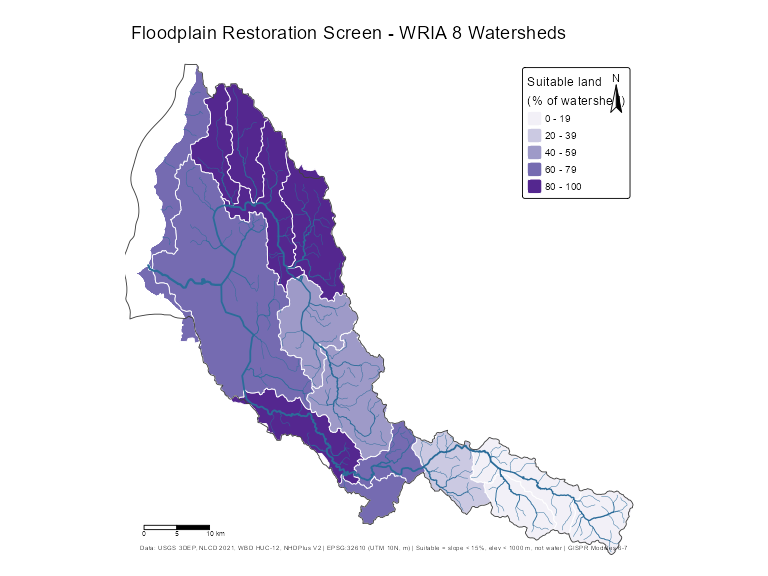

Map saved to c:\Users\mwebe\OneDrive\UW Program\GISPR\GitHubRepo\modules\outputs\module7\suitability_map_300dpi_r.png
Resolution: 2700 by 2400 pixels
Size: 9 by 8 inches (300 dpi)
Map saved to C:\Users\mwebe\OneDrive\UW Program\GISPR\GitHubRepo\modules\outputs\module7\suitability_map_r.pdf
Size: 9 by 8 inches
Saved to: C:\Users\mwebe\OneDrive\UW Program\GISPR\GitHubRepo\modules\outputs\module7 


In [ ]:
# [R] Cartographic elements with tmap — the furniture is built in (tmap v4: tm_scalebar, tm_title)
library(tmap)
tmap_mode("plot")

SUIT_BREAKS <- c(0, 20, 40, 60, 80, 100)
CREDITS <- paste("Data: USGS 3DEP, NLCD 2021, WBD HUC-12, NHDPlus V2 | EPSG:32610 (UTM 10N, m) |",
                 "Suitable = slope < 15%, elev < 1000 m, not water | GISPR Modules 6-7")
streams$lwd <- pmin(streams$stream_order, 5) * 0.5                  # line width = stream order
st_agr(streams) <- "constant"

m <- tm_shape(watersheds) +
       tm_polygons(fill = "pct_suitable", col = "white",
                   fill.scale  = tm_scale_intervals(style = "fixed", breaks = SUIT_BREAKS, values = "brewer.purples"),
                   fill.legend = tm_legend(title = "Suitable land\n(% of watershed)")) +
     tm_shape(streams) + tm_lines(col = "#2b6c99", lwd = "lwd", lwd.scale = tm_scale_asis(), lwd.legend = tm_legend_hide()) +
     tm_shape(wria8) + tm_borders(col = "grey25", lwd = 1) +
     tm_scalebar(breaks = c(0, 5, 10), position = c("left", "bottom")) +
     tm_compass(type = "arrow", position = c("right", "top")) +
     tm_credits(CREDITS, size = 0.5, position = c("left", "bottom")) +
     tm_title("Floodplain Restoration Screen - WRIA 8 Watersheds") +
     tm_layout(frame = FALSE, legend.position = c("right", "top"),
               legend.bg.color = "white", legend.bg.alpha = 0.9)
m

# ── Export at print resolution ─────────────────────────────────────────────
tmap_save(m, file.path(OUT, "suitability_map_300dpi_r.png"), dpi = 300, width = 9, height = 8)
tmap_save(m, file.path(OUT, "suitability_map_r.pdf"), width = 9, height = 8)       # vector
cat("Saved to:", normalizePath(OUT), "\n")

# ggplot2 equivalent, when you need map + chart panels in one figure
# library(ggplot2); library(ggspatial)
# ggplot() +
#   geom_sf(data = watersheds, aes(fill = cut(pct_suitable, SUIT_BREAKS)), colour = "white") +
#   geom_sf(data = streams, colour = "#2b6c99", linewidth = 0.2) +
#   scale_fill_brewer(palette = "Purples", name = "Suitable land (%)") +
#   annotation_scale(location = "bl") + annotation_north_arrow(location = "tr", style = north_arrow_minimal()) +
#   labs(title = "Floodplain Restoration Screen - WRIA 8", caption = CREDITS) + theme_void()

### 🔧 Try it yourself — cartographic elements ⭐ *(extra credit — optional)*

1. Open `suitability_map_300dpi.png` at 100% zoom. Now open the 96 dpi version. Which one could you hand to a print shop?
2. Replace `"labels": SUIT_LABELS` with nothing and re-run. GeoPandas writes `6.70, 20.00` — the data minimum, to two
   decimals. Which legend would the council rather read?
3. Delete `add_credits(...)` and imagine someone asks "is this in feet or metres, and how old is this land cover?"
   Every element you remove is a question you have to answer live, from memory.
4. Add the salmon observations as points (`salmon.plot(ax=ax, ...)`). Does the map get more informative, or just busier?
   Cartography is subtraction as often as addition.

suitability_map_300dpi.png     2810 x 2970 px  (9.4 x 9.9 in at 300 dpi, 29.3 x 30.9 in at 96 dpi)
suitability_map_screen.png     899 x 952 px  (3.0 x 3.2 in at 300 dpi, 9.4 x 9.9 in at 96 dpi)


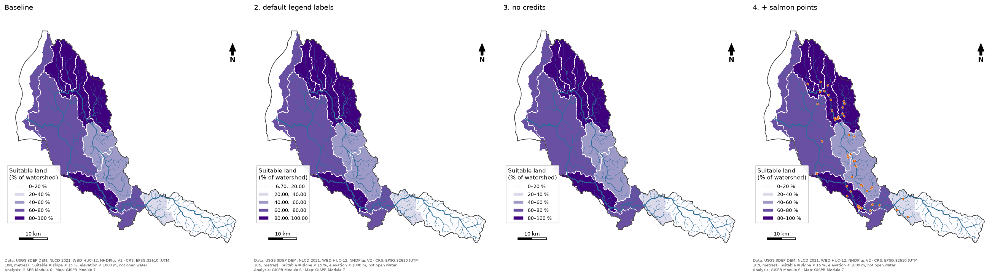

In [28]:
# [Python] Try it yourself — Section 5
import matplotlib.image as mpimg

# 1. Pixel size of the exports: 300 dpi vs. 96 dpi
for f in ["suitability_map_300dpi.png", "suitability_map_screen.png"]:
    h, w = mpimg.imread(OUT / f).shape[:2]
    print(f"{f:30} {w} x {h} px  ({w / 300:.1f} x {h / 300:.1f} in at 300 dpi, {w / 96:.1f} x {h / 96:.1f} in at 96 dpi)")

# 2-4. Baseline vs. default legend labels vs. no credits vs. + salmon points
def furniture_map(ax, labels=True, credits=True, show_salmon=False):
    lk = {"title": "Suitable land\n(% of watershed)", "loc": "lower left", "bbox_to_anchor": (0, 0.12),
          "fontsize": 8, "title_fontsize": 9, "framealpha": 0.92} | ({"labels": SUIT_LABELS} if labels else {})
    watersheds.plot(ax=ax, column="pct_suitable", cmap="Purples", scheme="user_defined",
                    classification_kwds={"bins": SUIT_BINS}, edgecolor="white", linewidth=0.9,
                    legend=True, legend_kwds=lk)
    streams.plot(ax=ax, color="#2b6c99", linewidth=streams["stream_order"].clip(1, 5) * 0.35)
    wria8.boundary.plot(ax=ax, color="0.25", linewidth=1.0)
    if show_salmon:
        salmon.plot(ax=ax, color="#d95f02", markersize=12, edgecolor="white", linewidth=0.3, zorder=6)
    ax.set_axis_off()
    add_scale_bar(ax, 10000)
    add_north_arrow(ax)
    if credits:
        add_credits(ax, CREDITS, fontsize=6)

fig2, axes2 = plt.subplots(1, 4, figsize=(22, 7))
for ax, kw, ttl in zip(axes2, [{}, {"labels": False}, {"credits": False}, {"show_salmon": True}],
                       ["Baseline", "2. default legend labels", "3. no credits", "4. + salmon points"]):
    furniture_map(ax, **kw)
    ax.set_title(ttl, loc="left", fontsize=11)
plt.tight_layout()
plt.show()


**Answers — Section 5 "Try it yourself"**

1. **300 dpi vs. 96 dpi.** The 300 dpi PNG is 2810 x 2970 px, about 9.4 x 9.9 in at print resolution. The 96 dpi file is only 899 x 952 px, which is about 3 in wide at 300 dpi and looks soft and pixelated on paper. Hand the print shop the 300 dpi PNG, or better the PDF, which is vector and scales without loss. The 96 dpi version is for the screen only.
2. **Legend labels.** The default labels read `6.70, 20.00`, `20.00, 40.00` and so on. They show the data minimum to two decimals, give no units and don't say whether a boundary value falls in the lower or upper class. The council would rather read the custom labels (`0–20 %`, `20–40 %`, ...), which are round, carry a unit and match the fixed breaks.
3. **No credits.** Without credits the map no longer says that it is in metres (EPSG:32610), that land cover is NLCD 2021, what "suitable" means, or who made it. Each of those becomes a question you must answer from memory, and none of them can be checked afterwards.
4. **Adding salmon points.** The map gets busier more than it gets informative. About 60 orange points cluster along the Cedar River, hide the stream lines and the watershed fill, and compete with the suitability colours for attention. They answer a different question (where fish were seen), so they belong on a separate map or a secondary inset rather than on the suitability map.


---
## Section 6 — Layering Rasters and Vectors

Your Module 5–6 rasters and your Module 3–4 vectors, on one figure. Two rules:

1. **Draw order is call order.** Hillshade first, at `alpha` 0.5–0.6. Vectors on top. Reverse them and your
   streams vanish — which looks like a data problem but is a z-order problem.
2. **Align the CRS *before* the first plot call.**

> ⚠ **matplotlib is not a GIS.** It plots *coordinates*, not geography. Hand it two layers in different
> CRS and it will render them into the same Axes without a word of complaint. ArcGIS Pro reprojects on the fly and
> hides this from you — in code, alignment is your job.
>
> This course's own data sets the trap for you: the geodatabase is in **EPSG:2926 (State Plane, US feet)**, the
> rasters are in **EPSG:32610 (UTM, metres)**. Forget one `to_crs()` and the streams land roughly a thousand
> kilometres from the DEM in coordinate space.

🟢 **`[Python]`**

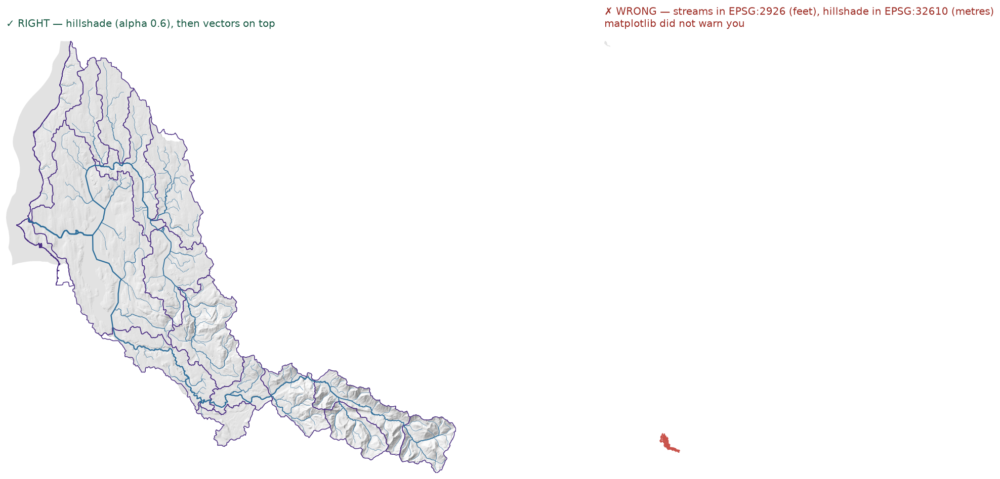

hillshade x range:      540,540 –      618,600  (metres, UTM)
streams   x range:    1,245,222 –    1,489,385  (feet, State Plane)
Both on the same Axes. Neither library raised a single warning.


In [14]:
# [Python] Hillshade + watersheds + streams — and the CRS trap, demonstrated with the course's own data
from rasterio.plot import show as rshow

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# ── ✓ RIGHT — same CRS, raster first, vectors on top ────────────────────────
ax = axes[0]
with rasterio.open(hs_path) as src:
    rshow(src, ax=ax, cmap="Greys_r", alpha=0.6)
watersheds.plot(ax=ax, facecolor="none", edgecolor="#4B2E83", linewidth=0.9)
streams.plot(ax=ax, color="#2b6c99", linewidth=streams["stream_order"].clip(1, 5) * 0.35)
ax.set_title("✓ RIGHT — hillshade (alpha 0.6), then vectors on top", loc="left", color="#1B5C46")

# ── ✗ WRONG — streams straight out of the geodatabase (EPSG:2926), raster in EPSG:32610 ──
ax = axes[1]
streams_as_stored = gpd.read_file(WS_GDB, layer="streams")                 # no to_crs()!
with rasterio.open(hs_path) as src:
    rshow(src, ax=ax, cmap="Greys_r", alpha=0.6)
streams_as_stored.plot(ax=ax, color="#C9524A", linewidth=1.5)
ax.set_title("✗ WRONG — streams in EPSG:2926 (feet), hillshade in EPSG:32610 (metres)\n"
             "matplotlib did not warn you", loc="left", color="#9E2F27")

for a in axes:
    a.set_axis_off()
plt.tight_layout(); plt.show()

with rasterio.open(hs_path) as src:
    print(f"hillshade x range: {src.bounds.left:>12,.0f} – {src.bounds.right:>12,.0f}  (metres, UTM)")
print(f"streams   x range: {streams_as_stored.total_bounds[0]:>12,.0f} – {streams_as_stored.total_bounds[2]:>12,.0f}"
      f"  (feet, State Plane)")
print("Both on the same Axes. Neither library raised a single warning.")

In [15]:
# [Python] The defensive check — steal this for every multi-layer script
def assert_aligned(*layers, target=None):
    """Raise loudly if any layer's CRS disagrees. Accepts GeoDataFrames and raster paths. Call before the first plot."""
    crs_list = []
    for lyr in layers:
        if hasattr(lyr, "crs"):
            crs_list.append(lyr.crs)
        else:
            with rasterio.open(lyr) as src:
                crs_list.append(src.crs)
    target = target or crs_list[0]
    bad = [i for i, c in enumerate(crs_list) if c != target]
    if bad:
        raise ValueError(f"CRS mismatch in layers {bad}: {[str(crs_list[i]) for i in bad]} != {target}")
    print(f"✓ all {len(layers)} layers aligned on {target}")
    return target

assert_aligned(watersheds, streams, salmon, sites, hs_path)                # passes

try:
    assert_aligned(watersheds, streams_as_stored, hs_path)                 # fails — exactly as it should
except ValueError as e:
    print("✗ caught:", e)

✓ all 5 layers aligned on EPSG:32610
✗ caught: CRS mismatch in layers [1]: ['EPSG:2926'] != EPSG:32610


🔵 **`[R]`**

OK - all 3 layers aligned on EPSG:32610


Error in assert_aligned(streams_as_stored, hs) : 
  CRS mismatch: 2926 / 32610


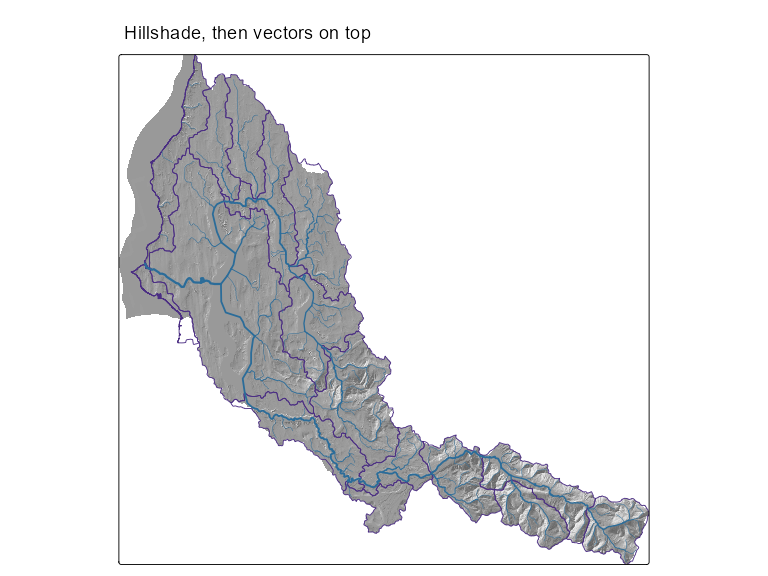

In [ ]:
# [R] Layering terra rasters under sf vectors with tmap — and the same defensive habit
library(terra)
library(sf)
library(tmap)

assert_aligned <- function(...) {
  layers <- list(...)
  codes  <- vapply(layers, function(l) {
    as.character(if (inherits(l, "SpatRaster")) terra::crs(l, describe = TRUE)$code else st_crs(l)$epsg)
  }, character(1))
  if (length(unique(codes)) > 1) stop("CRS mismatch: ", paste(codes, collapse = " / "))
  message("OK - all ", length(layers), " layers aligned on EPSG:", codes[1])
  invisible(codes[1])
}

assert_aligned(watersheds, streams, hs)                                   # passes
streams_as_stored <- lower_names(st_read(WS_GDB, layer = "streams", quiet = TRUE))
try(assert_aligned(streams_as_stored, hs))                               # fails - 2926 vs 32610

# ✓ RIGHT — check alignment FIRST, then raster, then vectors
tm_shape(hs) +
  tm_raster(col.scale = tm_scale_continuous(values = "brewer.greys"), col.legend = tm_legend_hide(),
            col_alpha = 0.6) +
tm_shape(watersheds) + tm_borders(col = "#4B2E83", lwd = 1) +
tm_shape(streams) + tm_lines(col = "#2b6c99", lwd = "lwd", lwd.scale = tm_scale_asis(), lwd.legend = tm_legend_hide()) +
tm_title("Hillshade, then vectors on top")

# NOTE: tmap (like Pro) reprojects on the fly, which is friendlier than matplotlib —
# but plain plot() / base graphics won't. Reproject explicitly when it matters.

### 🔧 Try it yourself — layering ⭐ *(extra credit — optional)*

1. Swap the draw order: plot `streams` before the hillshade. Where did they go? Now you know what a z-order bug looks
   like, so you won't spend an hour blaming the data.
2. Change hillshade `alpha` from 0.6 to 1.0. At what alpha does the terrain start competing with your watersheds instead
   of supporting them?
3. Re-run the setup with `hillshade(..., azimuth=135)` (light from the southeast). The Cascade ridges will read as valleys —
   your brain assumes light from the upper-left. That's a *perceptual* bug that no test will catch.
4. Wire `assert_aligned()` into the top of the Section 5 map. Make it a reflex.

✓ all 5 layers aligned on EPSG:32610


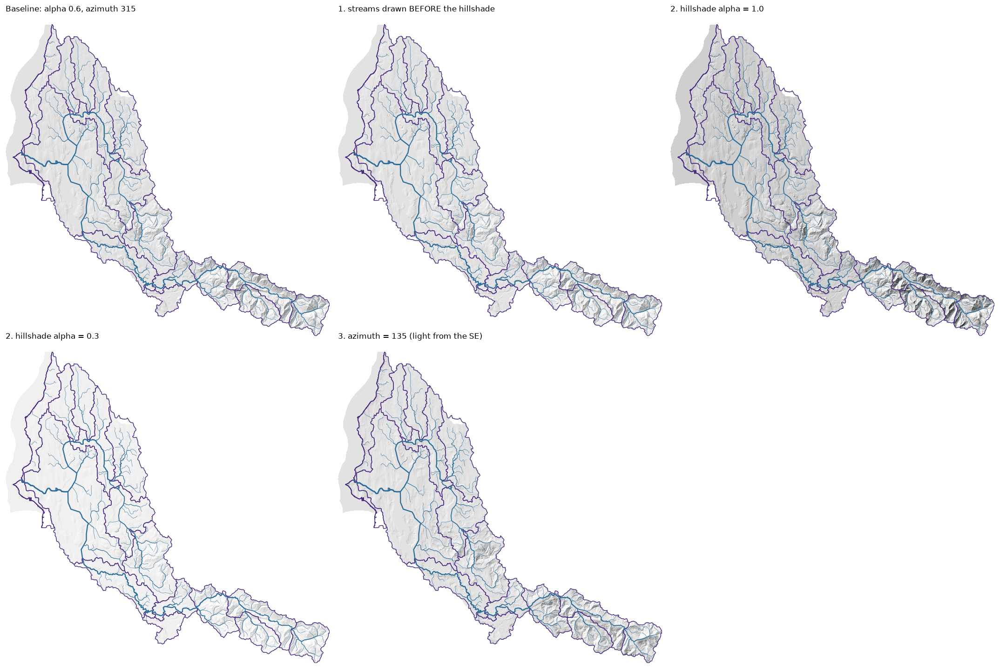

In [29]:
# [Python] Try it yourself — Section 6
hs_315 = hillshade(dem, CELL, azimuth=315)
hs_135 = hillshade(dem, CELL, azimuth=135)
extent = rasterio.transform.array_bounds(*dem.shape, clip_tr)          # (west, south, east, north)
extent = (extent[0], extent[2], extent[1], extent[3])                  # imshow wants (l, r, b, t)

def layered(ax, title, shade=hs_315, alpha=0.6, streams_first=False):
    def draw_streams():
        streams.plot(ax=ax, color="#2b6c99", linewidth=streams["stream_order"].clip(1, 5) * 0.35)
    if streams_first:
        draw_streams()
    ax.imshow(np.where(valid, shade, np.nan), cmap="Greys_r", extent=extent, alpha=alpha, interpolation="nearest")
    watersheds.plot(ax=ax, facecolor="none", edgecolor="#4B2E83", linewidth=0.9)
    if not streams_first:
        draw_streams()
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_axis_off()

# 4. Make the CRS check a reflex before any map is drawn
assert_aligned(watersheds, streams, wria8, salmon, hs_path)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
layered(axes[0, 0], "Baseline: alpha 0.6, azimuth 315")
layered(axes[0, 1], "1. streams drawn BEFORE the hillshade", streams_first=True)
layered(axes[0, 2], "2. hillshade alpha = 1.0", alpha=1.0)
layered(axes[1, 0], "2. hillshade alpha = 0.3", alpha=0.3)
layered(axes[1, 1], "3. azimuth = 135 (light from the SE)", shade=hs_135)
axes[1, 2].set_axis_off()
plt.tight_layout()
plt.show()


**Answers — Section 6 "Try it yourself"**

1. **Draw order.** With the hillshade at alpha 0.6, the streams drawn first are still visible but washed out, because the translucent grey layer sits over them (top row, middle panel). The stream lines also lose contrast against the terrain. With an opaque hillshade (alpha 1.0) drawn after the streams, they would disappear completely. In both cases the data are intact, so a "missing" layer is a z-order problem to check before blaming the data.
2. **Hillshade alpha.** At 0.3 the terrain is faint and supports the vectors. At 0.6 it is still supportive. At 1.0 the dark ridges in the Cedar headwaters (lower right) become the strongest feature on the map and compete with the watershed outlines and streams. The crossover is somewhere between 0.6 and 1.0; by 1.0 the terrain is clearly competing.
3. **Azimuth 135.** With light from the southeast, the relief in the Cedar headwaters can read as inverted, with ridges looking like valleys. Our visual system assumes light from the upper left (azimuth 315), so a shading that goes against it creates an illusion that no data check would flag. Keep 315 unless you have a reason not to.
4. **`assert_aligned()`.** The cell calls it before any plotting and it prints `✓ all 5 layers aligned on EPSG:32610` for the watersheds, streams, WRIA 8 boundary, salmon and hillshade. If any layer were still in EPSG:2926, it would stop with a `ValueError` before a misaligned map was drawn.


---
## Section 7 — Interactive Web Maps

Same layer, same breaks, now in a browser. One HTML file you can email to anyone — no licence, no install,
no ArcGIS Online credit.

### The four libraries, and the honest way to think about them

Each language gives you the same pair: one library that hands you a map in a single line, and one that
gives you control over every element. **They are not competitors — they're different moments in your day.**

| | Fast look (one line) | Full control (production) |
|---|---|---|
| **Python** | `leafmap` | `folium` |
| **R** | `mapview` | `leaflet` |

- **`leafmap` / `mapview`** — for *you*. Checking whether the join worked. Confirming the salmon points land on the
  streams. Batteries included: basemaps, popups, layer control, raster support, all by default.
- **`folium` / `leaflet`** — for *everyone else*. Explicit tooltips, controlled palettes, deliberate zoom
  bounds, a legend you wrote.

> ⚠ **The mistake to avoid:** `mapview` and `leafmap` are so convenient that people ship them. Interactive
> defaults are for exploration. A public deliverable needs decisions, not defaults.

### The rule that breaks everything

**Reproject to EPSG:4326 first.** Web maps assume lon/lat. `folium` and `leaflet` will not do it for you, and they
**fail silently** — our UTM metres would be read as degrees and the layer lands nowhere near Seattle (or nowhere at all).

### And the honest trade-off

Interactive is not strictly better than static. It can't be printed, it's harder to archive, and it invites
zoom levels your data doesn't support. **NHDPlus V2 flowlines were compiled at 1:100,000.** Let the public zoom to a
single back yard and you've implied precision you don't have. Set `min_zoom` / `max_zoom` on purpose.

### 7a — `folium`: explicit control (Python)

`folium` wraps Leaflet.js. Nothing is automatic, which is exactly why it's the right tool for a deliverable.

Two things that catch everyone:
- `folium.Choropleth` needs `key_on` to match a property in the GeoJSON — the string is
  `"feature.properties.<column>"` and getting it wrong produces a silently unstyled map.
- Tooltips are what make a map *stand alone*. Without one, a reader sees a colour and can't read a value.

🟢 **`[Python]`**

In [16]:
# [Python] folium — the deliverable version, with every decision made on purpose
import folium
import branca.colormap as cm

# ── RULE 1: reproject to 4326 BEFORE anything else ──────────────────────────
# Simplify for the web first (20 m tolerance in UTM) — the full-resolution outlines make a 2 MB HTML file
ws_ll      = watersheds.assign(geometry=watersheds.simplify(20)).to_crs(4326)
streams_ll = streams[streams["stream_order"] >= 2].pipe(lambda g: g.assign(geometry=g.simplify(10))).to_crs(4326)
salmon_ll  = salmon.to_crs(4326)
print(f"watersheds CRS: {watersheds.crs.to_epsg()}  ->  web CRS: {ws_ll.crs.to_epsg()}")
c = wria8.to_crs(4326).union_all().centroid
centre = [c.y, c.x]

m = folium.Map(location=centre, zoom_start=10, tiles="Esri.WorldGrayCanvas",   # CARTO tiles now need an API key; Esri's don't
               min_zoom=9, max_zoom=13)          # deliberate: don't let them zoom past 1:100,000 data

# ── Colour by the SAME fixed breaks as the static map ───────────────────────
palette = cm.StepColormap(["#f2f0f7", "#cbc9e2", "#9e9ac8", "#756bb1", "#54278f"],   # ColorBrewer Purples, 5 classes
                          vmin=0, vmax=100, index=[0] + SUIT_BINS,
                          caption="Suitable land (% of watershed) — slope < 15 %, elev < 1000 m, not water")
cols = ["watershed_name", "subbasin", "pct_suitable", "pct_forest", "elev_mean", "area_km2"]
folium.GeoJson(
    ws_ll[cols + ["geometry"]], name="Restoration screen",
    style_function=lambda f: {"fillColor": palette(f["properties"]["pct_suitable"]), "color": "white",
                              "weight": 1.2, "fillOpacity": 0.75},
    highlight_function=lambda f: {"weight": 3, "color": "#4B2E83"},
    tooltip=folium.GeoJsonTooltip(fields=cols, aliases=["Watershed:", "Sub-basin:", "Suitable (%):", "Forest (%):",
                                                        "Mean elevation (m):", "Area (km²):"], localize=True),
).add_to(m)

folium.GeoJson(streams_ll[["stream_name", "stream_order", "geometry"]], name="Streams (order ≥ 2)",
               style_function=lambda f: {"color": "#2b6c99", "weight": 0.6 * f["properties"]["stream_order"]},
               tooltip=folium.GeoJsonTooltip(fields=["stream_name", "stream_order"],
                                             aliases=["Stream:", "Order:"])).add_to(m)

sp = folium.FeatureGroup(name="Salmon observations (fall 2024)", show=False)
for _, r in salmon_ll.iterrows():
    folium.CircleMarker([r.geometry.y, r.geometry.x], radius=3 + r["count"] / 6, color="#4B2E83", weight=1,
                        fill=True, fill_opacity=0.6,
                        tooltip=f"{r['species']}: {r['count']} ({r['method']}, {r['obs_date']})").add_to(sp)
sp.add_to(m)

palette.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
folium_path = OUT / "restoration_screen_folium.html"
m.save(folium_path)
print(f"saved: {folium_path}  ({folium_path.stat().st_size:,} bytes)")
print("One self-contained HTML file. Email it, or drop it on any web server.")
m   # renders inline in Jupyter

watersheds CRS: 32610  ->  web CRS: 4326
saved: outputs\module7\restoration_screen_folium.html  (404,233 bytes)
One self-contained HTML file. Email it, or drop it on any web server.


In [17]:
# [Python] folium.Choropleth — the key_on trap, shown working (drainage density from Section 3)
m2 = folium.Map(location=centre, zoom_start=10, tiles="Esri.WorldGrayCanvas", min_zoom=9, max_zoom=13)
folium.Choropleth(
    geo_data=ws_ll[["watershed_id", "geometry"]].to_json(),
    data=ws_ll, columns=["watershed_id", "drainage_density"],
    key_on="feature.properties.watershed_id",          # <- the string that trips everyone
    fill_color="Blues", fill_opacity=0.75, line_opacity=0.4, nan_fill_color="lightgrey",
    legend_name="Drainage density (km of stream per km²) — normalized, see Section 3",
).add_to(m2)
# Choropleth alone has no tooltips — add a transparent layer on top for hover
folium.GeoJson(ws_ll, style_function=lambda f: {"fillOpacity": 0, "weight": 0},
               tooltip=folium.GeoJsonTooltip(fields=["watershed_name", "stream_km", "drainage_density"],
                                             aliases=["Watershed:", "Stream km:", "km per km²:"])).add_to(m2)
m2.save(OUT / "drainage_density_folium.html")
print("key_on must be 'feature.properties.<column>' — a typo here silently unstyles the map.")
print("Note we mapped the NORMALIZED value, not raw stream km. Section 3 applies on the web too.")
m2

key_on must be 'feature.properties.<column>' — a typo here silently unstyles the map.
Note we mapped the NORMALIZED value, not raw stream km. Section 3 applies on the web too.


### 7b — `leafmap`: batteries included (Python)

`leafmap` (Qiusheng Wu, 2021) is the Python analogue of R's `mapview`: a map in one line, with basemaps,
layer control, and popups already wired up. It's the fastest way to *look* at spatial data in a notebook.

**Two backends — and the choice matters:**

| Import | Backend | Use when |
|---|---|---|
| `import leafmap` | `ipyleaflet` | Interactive work *in* the notebook. Needs Jupyter widgets. Richer drawing tools. |
| `import leafmap.foliumap as leafmap` | `folium` | You need a **standalone HTML export**, or widgets aren't available (Colab, some Hubs, nbconvert). |

> **On JupyterHub, prefer `leafmap.foliumap`.** The ipyleaflet backend needs the widget extension enabled;
> the folium backend just works and exports clean HTML. Same API either way.

What `leafmap` gives you that raw `folium` doesn't:
- `add_gdf()` — a GeoDataFrame on the map with popups, one line
- `add_raster()` — a **local GeoTIFF** on a web map, correctly warped (the headline feature)
- `split_map()` — a before/after slider, ~3 lines
- `add_basemap("...")` — dozens of named basemaps without hunting for tile URLs


🟢 **`[Python]`**

In [18]:
# [Python] leafmap — the one-liner that replaces twenty lines of folium
import leafmap.foliumap as leafmap          # folium backend: clean HTML export, no widget extension needed

m3 = leafmap.Map(center=centre, zoom=10)
m3.add_basemap("Esri.WorldGrayCanvas")      # leafmap's folium backend uses its own basemap names
m3.add_gdf(ws_ll, layer_name="Watersheds (all attributes)", info_mode="on_hover")   # popups: every column
m3.add_gdf(salmon_ll, layer_name="Salmon observations")

leafmap_path = OUT / "watersheds_leafmap.html"
m3.to_html(str(leafmap_path))
print(f"saved: {leafmap_path}  ({leafmap_path.stat().st_size:,} bytes)")
print("Compare this cell to the folium cell above. A fraction of the code — and leafmap chose the colours,")
print("the popup fields and the zoom range for you. Fine for YOU. Think before you ship it.")
m3

saved: outputs\module7\watersheds_leafmap.html  (218,198 bytes)
Compare this cell to the folium cell above. A fraction of the code — and leafmap chose the colours,
the popup fields and the zoom range for you. Fine for YOU. Think before you ship it.


In [19]:
# [Python] leafmap's headline feature — a local GeoTIFF on a web map
# add_raster() reprojects the UTM GeoTIFF to web mercator and serves it as tiles.
# Requires: localtileserver + rioxarray. On JupyterHub it also needs jupyter-server-proxy.
m4 = leafmap.Map(center=centre, zoom=10)
m4.add_basemap("Esri.WorldGrayCanvas")
try:
    m4.add_raster(str(dem_path), colormap="terrain", layer_name="Elevation (m)", opacity=0.75)
    m4.add_gdf(ws_ll, layer_name="Watersheds")
    m4.to_html(str(OUT / "dem_leafmap.html"))
    print("✓ add_raster worked — the DEM is on a slippy map, reprojected for you.")
except Exception as e:
    print(f"✗ add_raster unavailable here ({type(e).__name__}: {str(e)[:80]})")
    print("  leafmap's raster support depends on localtileserver, which needs a tile server the browser can reach.")
    print("  Behind a strict proxy it fails. The next cell is the dependency-free fallback.")
m4

✓ add_raster worked — the DEM is on a slippy map, reprojected for you.


reprojected the hillshade to 4326 at 867 × 834 px and overlaid it as a PNG (205,494 bytes)
We reprojected the raster BY HAND. That's what add_raster was doing for you.



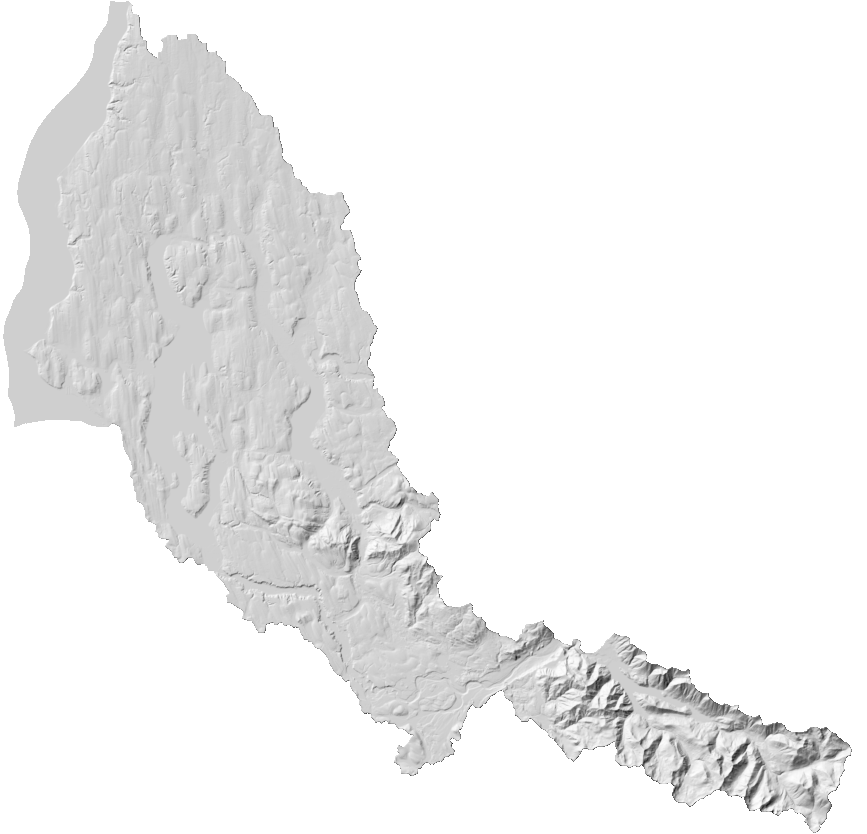

In [20]:
# [Python] Dependency-free raster fallback — ImageOverlay from a PNG (works anywhere folium works)
import matplotlib.image
from rasterio.warp import calculate_default_transform, reproject, Resampling

with rasterio.open(hs_path) as src:
    dst_crs = "EPSG:4326"
    # Downsample on the way: 30 m is ~2,600 px across — far more than a web overlay needs (watch the file size)
    transform, w, h = calculate_default_transform(src.crs, dst_crs, src.width, src.height, *src.bounds,
                                                  dst_width=src.width // 3, dst_height=src.height // 3)
    arr = np.zeros((h, w), dtype="uint8")
    reproject(source=rasterio.band(src, 1), destination=arr, src_transform=src.transform, src_crs=src.crs,
              dst_transform=transform, dst_crs=dst_crs, resampling=Resampling.bilinear, dst_nodata=0)
    west, south, east, north = rasterio.transform.array_bounds(h, w, transform)

rgba = plt.get_cmap("Greys_r")(arr / 255.0)
rgba[..., 3] = np.where(arr == 0, 0, 1)                     # NoData → transparent
png_path = OUT / "hillshade_4326.png"
matplotlib.image.imsave(png_path, rgba)

m5 = folium.Map(location=centre, zoom_start=10, tiles="Esri.WorldGrayCanvas", min_zoom=9, max_zoom=13)
folium.raster_layers.ImageOverlay(image=str(png_path), bounds=[[south, west], [north, east]],
                                  opacity=0.55, name="Hillshade").add_to(m5)
folium.GeoJson(ws_ll[["watershed_name", "pct_suitable", "geometry"]], name="Restoration screen",
               style_function=lambda f: {"fillColor": palette(f["properties"]["pct_suitable"]), "color": "white",
                                         "weight": 1, "fillOpacity": 0.45},
               tooltip=folium.GeoJsonTooltip(fields=["watershed_name", "pct_suitable"])).add_to(m5)
folium.LayerControl().add_to(m5)
m5.save(OUT / "hillshade_overlay_folium.html")
print(f"reprojected the hillshade to 4326 at {w} × {h} px and overlaid it as a PNG ({png_path.stat().st_size:,} bytes)")
print("We reprojected the raster BY HAND. That's what add_raster was doing for you.")
m5

In [21]:
# [Python] leafmap split_map — the before/after slider, in three lines
m6 = leafmap.Map(center=centre, zoom=11)
m6.split_map(left_layer="OpenTopoMap", right_layer="Esri.WorldImagery")
m6.to_html(str(OUT / "split_leafmap.html"))
print("Drag the slider. For 'before restoration / after restoration' this is the whole feature.")
m6

Drag the slider. For 'before restoration / after restoration' this is the whole feature.


### 7c — `leaflet`: explicit control (R)

R's `leaflet` is the direct analogue of `folium` — same JavaScript library underneath, same philosophy:
you make every decision. The pipe (`|>`) makes the layer stack read top to bottom.

Same rule as Python: **`st_transform(4326)` first.**

🔵 **`[R]`**

In [ ]:
# [R] leaflet — the deliverable version, every decision made on purpose
library(leaflet)
library(sf)

# ── RULE 1: reproject to 4326 BEFORE anything else ─────────────────────────
ws_ll      <- st_transform(st_simplify(watersheds, dTolerance = 20), 4326)     # simplify for the web first
streams_ll <- st_transform(st_simplify(streams[streams$stream_order >= 2, ], dTolerance = 10), 4326)
salmon_ll  <- st_transform(salmon, 4326)
cat("watersheds CRS:", st_crs(watersheds)$epsg, " ->  web CRS:", st_crs(ws_ll)$epsg, "\n")

# Same fixed breaks as the static map — the legend must mean the same thing
pal <- colorBin("Purples", domain = c(0, 100), bins = c(0, 20, 40, 60, 80, 100))

m_leaf <- leaflet(ws_ll, options = leafletOptions(minZoom = 9, maxZoom = 13)) |>   # deliberate zoom bounds
  addProviderTiles(providers$Esri.WorldGrayCanvas) |>   # CARTO tiles now need an API key
  addPolygons(fillColor = ~pal(pct_suitable), fillOpacity = 0.75, color = "white", weight = 1.2,
              label = ~paste0(watershed_name, ": ", pct_suitable, "% suitable"),
              popup = ~paste0("<b>", watershed_name, "</b><br>Sub-basin: ", subbasin,
                              "<br>Suitable: ", pct_suitable, "%<br>Forest: ", pct_forest,
                              "%<br>Mean elevation: ", elev_mean, " m"),
              group = "Restoration screen") |>
  addPolylines(data = streams_ll, color = "#2b6c99", weight = ~0.6 * stream_order,
               label = ~stream_name, group = "Streams (order >= 2)") |>
  addCircleMarkers(data = salmon_ll, radius = ~3 + count / 6, color = "#4B2E83", weight = 1, fillOpacity = 0.6,
                   label = ~paste0(species, ": ", count, " (", method, ")"), group = "Salmon observations") |>
  addLegend(pal = pal, values = c(0, 100), opacity = 0.9, position = "bottomright",
            title = "Suitable land<br>(% of watershed)") |>
  addLayersControl(overlayGroups = c("Restoration screen", "Streams (order >= 2)", "Salmon observations"),
                   options = layersControlOptions(collapsed = FALSE)) |>
  hideGroup("Salmon observations")
m_leaf

# Save a standalone HTML — the R equivalent of folium's m.save()
htmlwidgets::saveWidget(m_leaf, file.path(normalizePath(OUT), "restoration_screen_leaflet.html"),
                        selfcontained = TRUE)

Warning message:
package ‘leaflet’ was built under R version 4.5.2 


watersheds CRS: 32610  ->  web CRS: 4326 


<leaflet HTML widget>

🔵 **`[R]`**

### 7d — `mapview`: batteries included (R)

`mapview` is the R analogue of `leafmap` — and it is the single best ergonomic in either language for
*looking at* spatial data. `mapview(watersheds)` and you have an interactive map with a basemap, a popup
containing every attribute, and zoom-to-layer. No arguments required.

**Where it earns its place:**
- **Instant QA.** Did the join work? Do the salmon points sit on the streams? One line, one look.
- **The `+` operator.** `mapview(a) + mapview(b)` stacks layers with a layer control for free.
- **It reads rasters too.** `mapview(dem)` just works.
- **The popup is the attribute table** — often exactly what you need mid-debug.

> ⚠ **Do not ship it.** `mapview` picks the palette, the breaks, the basemap, and the popup contents *for*
> you. Those are the four decisions this whole module has been about. When the map is for someone else, move to `leaflet`.

**`tmap` has a third way:** `tmap_mode("view")` turns the *static map you already wrote* interactive with
one line. Same object, same breaks, now zoomable. If you built your map in `tmap`, this is the shortest
honest path to the browser.

🔵 **`[R]`**

GDAL version >= 3.1.0 | setting mapviewOptions(fgb = TRUE)


Warning message:
package ‘mapview’ was built under R version 4.5.2 


<leaflet HTML widget>

<leaflet HTML widget>

<leaflet HTML widget>

Warning message:
Found less unique colors (5) than unique zcol values (6)! 
Interpolating color vector to match number of zcol values. 


<leaflet HTML widget>

<leaflet HTML widget>
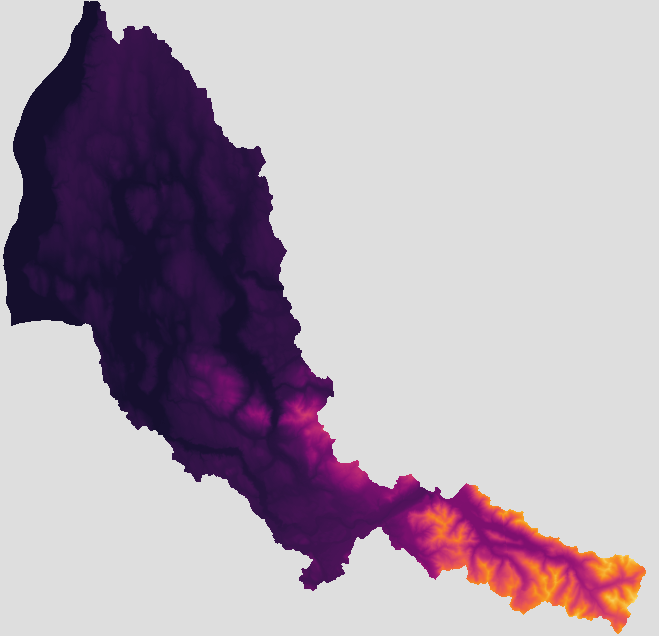

<leaflet HTML widget>

In [ ]:
# [R] mapview — instant QA, one line
library(mapview)
mapviewOptions(fgb = FALSE,                       # Jupyter can't serve FlatGeobuf side files → empty map
               basemaps = c("Esri.WorldGrayCanvas",  # first = default; CARTO tiles now need an API key
                            "OpenStreetMap",
                            "Esri.WorldImagery",
                            "OpenTopoMap"))
# ── The one-liner. This is the whole point. ────────────────────────────────
mapview(watersheds)

# Colour by an attribute — still one line
mapview(watersheds, zcol = "pct_suitable")

# Control what you get, when you need to — same fixed breaks as the static map
mapview(watersheds, zcol = "pct_suitable", at = c(0, 20, 40, 60, 80, 100),
        col.regions = RColorBrewer::brewer.pal(5, "Purples"), layer.name = "Suitable land (%)")

# ── The + operator: stack layers, get a layer control free ─────────────────
mapview(watersheds, zcol = "subbasin", alpha.regions = 0.2, legend = FALSE) +
  mapview(streams, color = "#2b6c99", lwd = 1, legend = FALSE) +
  mapview(salmon, zcol = "species")                                     # do the points sit on streams?

# ── It reads rasters too (aggregate first — 6.5 million cells is a lot for a browser) ──
mapview(aggregate(dem, 4), layer.name = "Elevation (m)") + mapview(watersheds, alpha.regions = 0)

# ── QA in practice — this is what mapview is actually for ──────────────────
mapview(watersheds[is.na(watersheds$salmon_counted), ], col.regions = "red")   # where are the survey gaps?

# ── Export. mapshot() writes standalone HTML or a PNG snapshot ────────────
# m <- mapview(watersheds, zcol = "pct_suitable")
# mapshot(m, url  = file.path(OUT, "watersheds_mapview.html"))
# mapshot(m, file = file.path(OUT, "watersheds_mapview.png"))   # needs webshot2

# ── tmap's third way: the static map you already wrote, now interactive ───
# tmap_mode("view"); m; tmap_mode("plot")      # 'm' is the Section 5 map

### 🔧 Try it yourself — interactive maps ⭐ *(extra credit — optional)*

1. **Break it on purpose.** Delete `.to_crs(4326)` from `ws_ll` in the folium cell and re-run. The map renders, the
   tiles load, and your watersheds are nowhere. No error. Now you'll recognise this in five seconds instead of an hour.
2. Set `max_zoom=18` on the folium map and zoom all the way in on a stream. NHDPlus V2 was compiled at 1:100,000.
   At z18 you're implying sub-metre precision you do not have. Is that map honest?
3. Compare `leafmap`'s `add_gdf()` output to the `folium` cell. List three decisions leafmap made for you.
   For each, decide whether you'd accept it in a public deliverable.
4. In the ImageOverlay cell, change `src.width // 3` to `// 1` and then `// 8`. Watch the PNG size. Where does the
   hillshade stop being worth its bytes?
5. `split_map()` with `OpenTopoMap` vs `Esri.WorldImagery`. For a floodplain restoration before/after, what would your
   two layers be?

In [30]:
# [Python] Try it yourself — Section 7
import tempfile

# 1. Skip to_crs(4326): what coordinates would folium be handed?
bad = watersheds.assign(geometry=watersheds.simplify(20))
minx, miny, maxx, maxy = bad.total_bounds
print(f"1. Without to_crs: x {minx:,.0f} to {maxx:,.0f}, y {miny:,.0f} to {maxy:,.0f}  (valid lon/lat: x -180..180, y -90..90)")
print(f"   With to_crs:    {np.round(ws_ll.total_bounds, 3)}  (lon/lat degrees)")

# 2. Ground resolution of web-map zoom levels at WRIA 8's latitude vs. the NHD 1:100,000 compilation scale
lat = centre[0]
print("\n2. Metres per screen pixel at the WRIA 8 latitude:")
for z in (13, 15, 18):
    mpp = 156543.03 * np.cos(np.radians(lat)) / 2**z
    print(f"   zoom {z}: {mpp:6.2f} m/px")
print("   1:100,000 data have about 50 m of positional uncertainty (a 0.5 mm plotting error at that scale).")

# 4. Hillshade overlay: PNG size and dimensions at several downsampling factors
print("\n4. Hillshade overlay size by downsample factor:")
with rasterio.open(hs_path) as src, tempfile.TemporaryDirectory() as tmp:
    for f in (1, 3, 8):
        tr, w_, h_ = calculate_default_transform(src.crs, "EPSG:4326", src.width, src.height, *src.bounds,
                                                 dst_width=src.width // f, dst_height=src.height // f)
        a = np.zeros((h_, w_), dtype="uint8")
        reproject(source=rasterio.band(src, 1), destination=a, src_transform=src.transform, src_crs=src.crs,
                  dst_transform=tr, dst_crs="EPSG:4326", resampling=Resampling.bilinear, dst_nodata=0)
        rg = plt.get_cmap("Greys_r")(a / 255.0)
        rg[..., 3] = np.where(a == 0, 0, 1)
        p = Path(tmp) / f"hs_{f}.png"
        matplotlib.image.imsave(p, rg)
        print(f"   // {f}: {w_:>4} x {h_:>4} px  {p.stat().st_size / 1024:8,.0f} KB")


1. Without to_crs: x 542,352 to 618,587, y 5,235,815 to 5,310,858  (valid lon/lat: x -180..180, y -90..90)
   With to_crs:    [-122.436   47.266 -121.43    47.949]  (lon/lat degrees)

2. Metres per screen pixel at the WRIA 8 latitude:
   zoom 13:  12.89 m/px
   zoom 15:   3.22 m/px
   zoom 18:   0.40 m/px
   1:100,000 data have about 50 m of positional uncertainty (a 0.5 mm plotting error at that scale).

4. Hillshade overlay size by downsample factor:
   // 1: 2602 x 2503 px     1,366 KB
   // 3:  867 x  834 px       201 KB
   // 8:  325 x  312 px        33 KB


**Answers — Section 7 "Try it yourself"**

1. **Skipping `.to_crs(4326)`.** The watersheds would be handed to folium with x values around 542,000–619,000 and y values around 5.24–5.31 million. Valid longitude is -180 to 180 and valid latitude is -90 to 90, so Leaflet reads UTM metres as degrees and draws the layer far off the map. There is no error, only a map with the basemap and no watersheds. After `to_crs`, the bounds are about -122.44 to -121.43 and 47.27 to 47.95, which is where WRIA 8 sits. If a layer is missing on a web map, check the CRS first.
2. **`max_zoom=18`.** At zoom 18 a screen pixel is about 0.4 m on the ground at this latitude, against about 13 m at zoom 13. NHDPlus V2 was compiled at 1:100,000, where positional error is on the order of tens of metres (my rule-of-thumb estimate, not a figure from the data). A stream line at z18 therefore implies centimetre-to-metre accuracy that it does not have, and a reader could wrongly conclude that a house is "in" the stream. The map is not honest at that zoom, which is why the folium cell caps `max_zoom` at 13.
3. **What `leafmap` chose for you.** From the cell and its comments: (a) the colours and styling of the layers (no fixed breaks, so no legend that matches the static map), which I would not accept in a public deliverable; (b) the popup contents, which show every column, including internal IDs and unrounded numbers, which I would not accept either, because a public map needs a curated tooltip; (c) the default zoom range and basemap behaviour, with no `min_zoom`/`max_zoom` guarding the data's precision. This is fine for a quick look but not for a public map.
4. **Overlay resolution.** Dividing by 1 gives a 2602 x 2503 px PNG of about 1.4 MB, by 3 about 200 KB (867 x 834 px), and by 8 about 33 KB (325 x 312 px). The size falls roughly with the pixel count, but the web map is capped at zoom 13, where a pixel is already about 13 m, so the full 30 m grid adds bytes without visible detail. Dividing by 3 is a reasonable choice. Dividing by 8 (about 100 m per cell) starts to blur ridges and valleys.
5. **Split-map layers.** For a floodplain restoration before/after, use two aerial imagery layers from different dates (for example NAIP or an earlier orthophoto on the left and current imagery on the right). If dated imagery isn't available, use the same Esri imagery on one side and a flood-extent or land-cover overlay on the other. The `OpenTopoMap` vs `Esri.WorldImagery` pairing in the cell is only a demo of the slider and doesn't show change over time.


---
## Section 8 — ArcPy Layouts and the R-ArcGIS Bridge

You already make every decision in this module — you make them in the **Symbology pane**. `arcpy.mp` is
that pane serialized into lines you can diff, loop, and put under version control.

Look at what these two lines are:

```python
sym.renderer.classificationMethod = "NaturalBreaks"
sym.renderer.breakCount = 5
```

That is exactly `style = "jenks", n = 5` in tmap. Same sentence, different accent.

**So why do it in `arcpy.mp` rather than clicking?** One word: **batch**. Five sub-basins, five identical
layouts, one loop, at 300 dpi, re-runnable when the data changes. That's not a cartography trick — it's the
entire argument of this course, and Module 7 is where it starts to pay.

| Task | ArcGIS Pro (`arcpy.mp`) | Open source |
|---|---|---|
| Apply graduated colours | `sym.renderer.classificationMethod` | `scheme=` / `style=` |
| Export a layout at 300 dpi | `lyt.exportToPNG(path, resolution=300)` | `fig.savefig(dpi=300)` / `tmap_save()` |
| Publish a web map | `arcpy.SharePackage` → AGOL (licence) | `m.save()` → any web server (free) |
| Batch the sub-basins | `for` loop over `lyt.exportToPNG` | `for` loop over `savefig` |

> **Environment note:** ArcPy only runs in the ArcGIS Pro Python environment (or a clone), with **Spatial Analyst**.
> The cell below is **self-contained** — run it on its own in an ArcGIS Pro notebook (open this notebook in Pro, or paste
> the cell into a Pro notebook saved in your `Module 7` folder). It rebuilds the Module 6 numbers with `arcpy.sa`, writes
> them to `outputs/module7/module7.gdb`, and drives the Symbology pane and layout export (`"CURRENT"` project).
> On JupyterHub it prints a note and skips.
>
> **Demo knobs:** set `METHOD` at the top of the cell (`"NaturalBreaks"` *is* Jenks in Pro, `"Quantile"`, `"EqualInterval"`, …)
> and re-run. The layer is re-symbolized in place (no duplicate layers), the class breaks Pro chose are printed, and each run
> writes PNGs with the method in the file name, so you can compare them side by side.

🟠 **`[Python / ArcPy]`**

In [ ]:
# [Python / ArcPy] Watershed summary → file gdb → graduated colours → layout export   🏠 LOCAL ONLY
# Self-contained: run it in ArcGIS Pro's notebook on its own. It rebuilds the Module 6 numbers with arcpy.sa
# (the same Extract → Slope → Con → Zonal Statistics chain as the Module 6 ArcPy lab) — no geopandas needed.
from pathlib import Path

DATA = Path("data")                     # ← if Pro can't find it, use the full path to your Module 7/data folder
OUT  = Path("outputs/module7")
OUT.mkdir(parents=True, exist_ok=True)
WS_GDB = DATA / "salmon_watersheds.gdb"
for f in ["salmon_watersheds.gdb", "wria8_dem_30m.tif", "wria8_nlcd2021_30m.tif"]:
    assert (DATA / f).exists(), f"Missing data/{f} — run the copy helper in Section 1 or copy it by hand"

SUBBASIN = {"1711001201": "Cedar River", "1711001202": "Lake Sammamish", "1711001203": "Sammamish River",
            "1711001204": "Lake Washington", "1711001902": "Puget Sound frontal"}     # HUC-10 → name

# ── Demo knobs — change one, re-run the cell, compare the PNGs in outputs/module7 ──────────────
METHOD        = "ManualInterval"        # "NaturalBreaks" (= Jenks in Pro) | "EqualInterval" | "Quantile"
                                        # "GeometricalInterval" | "StandardDeviation" | "ManualInterval"
N_CLASSES     = 5                       # ignored by StandardDeviation (Pro sets the classes)
MANUAL_BREAKS = [20, 40, 60, 80, 100]   # upper bounds — ManualInterval only (the notebook's fixed breaks)

try:
    import arcpy
    HAS_ARCPY = True
except ModuleNotFoundError:
    HAS_ARCPY = False

if HAS_ARCPY:
    from arcpy.sa import ExtractByMask, Slope, Con, ZonalStatisticsAsTable
    if arcpy.CheckOutExtension("Spatial") != "CheckedOut":
        raise RuntimeError("Spatial Analyst licence is not available")
    arcpy.env.overwriteOutput = True
    gdb = OUT / "module7.gdb"
    if not arcpy.Exists(str(gdb)):
        arcpy.management.CreateFileGDB(str(OUT), "module7.gdb")
    arcpy.env.workspace = str(gdb.resolve())
    DEM_A, NLCD_A = str((DATA / "wria8_dem_30m.tif").resolve()), str((DATA / "wria8_nlcd2021_30m.tif").resolve())
    WS_FC, WRIA_FC = str((WS_GDB / "watersheds").resolve()), str((WS_GDB / "wria8_boundary").resolve())
    arcpy.env.snapRaster = DEM_A                                     # every output on the DEM's 30 m grid
    arcpy.env.outputCoordinateSystem = arcpy.Describe(DEM_A).spatialReference   # UTM 10N, like the open-source maps

    # ── 1. Copy the watersheds out of the course gdb ────────────────────────
    fc = str((gdb / "watershed_summary").resolve())
    arcpy.management.CopyFeatures(WS_FC, fc)

    # ── 2. The Module 6 screen in ArcPy: slope < 15 %, elevation < 1000 m, not open water ──
    dem    = ExtractByMask(DEM_A, WRIA_FC)
    lc     = ExtractByMask(NLCD_A, WRIA_FC)
    slope  = Slope(dem, "PERCENT_RISE")
    suit   = Con((slope < 15) & (dem < 1000) & (lc != 11), 1, 0)   # mean of a 0/1 raster = share of the zone
    forest = Con((lc >= 41) & (lc <= 43), 1, 0)                     # NLCD 41–43 = forest

    for value_r, field, scale in [(dem, "elev_mean", 1), (suit, "pct_suitable", 100), (forest, "pct_forest", 100)]:
        tbl = f"zs_{field}"
        ZonalStatisticsAsTable(fc, "WATERSHED_ID", value_r, tbl, "DATA", "MEAN")
        means = {zone: mean for zone, mean in arcpy.da.SearchCursor(tbl, ["WATERSHED_ID", "MEAN"])}
        arcpy.management.AddField(fc, field, "DOUBLE")
        with arcpy.da.UpdateCursor(fc, ["WATERSHED_ID", field]) as cur:
            for zone, _ in cur:
                cur.updateRow([zone, round(means[zone] * scale, 1)])

    arcpy.management.AddField(fc, "subbasin", "TEXT", field_length=30)
    with arcpy.da.UpdateCursor(fc, ["HUC12", "subbasin"]) as cur:
        for huc12, _ in cur:
            cur.updateRow([huc12, SUBBASIN.get(huc12[:10], "")])

    print(f"✓ wrote {fc} ({int(arcpy.management.GetCount(fc)[0])} features)")
    for row in sorted(arcpy.da.SearchCursor(fc, ["WATERSHED_NAME", "pct_suitable"]), key=lambda r: -r[1]):
        print(f"   {row[0]:34} {row[1]:5.1f} % suitable")      # should match the Python setup table / Module 6 lab

    # ── 3. The Symbology pane, as parameters (needs a project: run inside ArcGIS Pro) ──
    try:
        aprx = arcpy.mp.ArcGISProject("CURRENT")
    except OSError:
        aprx = None
        print("Not running inside ArcGIS Pro — open Pro's notebook to drive symbology and layouts.")
    if aprx is not None:
        m    = aprx.activeMap or aprx.listMaps()[0]
        lyrs = m.listLayers("watershed_summary")          # re-use the layer — no duplicates on re-runs
        lyr  = lyrs[0] if lyrs else m.addDataFromPath(fc)
        sym  = lyr.symbology
        sym.updateRenderer("GraduatedColorsRenderer")
        sym.renderer.classificationField  = "pct_suitable"
        sym.renderer.classificationMethod = METHOD
        if METHOD != "StandardDeviation":
            sym.renderer.breakCount = N_CLASSES if METHOD != "ManualInterval" else len(MANUAL_BREAKS)
        sym.renderer.colorRamp = aprx.listColorRamps("Purples (5 Classes)")[0]
        if METHOD == "ManualInterval":                      # the same fixed breaks as every other map tonight
            lower = 0
            for brk, upper in zip(sym.renderer.classBreaks, MANUAL_BREAKS):
                brk.upperBound, brk.label = upper, f"{lower}–{upper} %"
                lower = upper
        lyr.symbology = sym
        print(f"✓ graduated colours applied: pct_suitable, {METHOD}, Purples")
        for brk in lyr.symbology.renderer.classBreaks:      # what Pro actually used — compare across methods
            print(f"   ≤ {brk.upperBound:6.1f}   {brk.label}")

        # ── 4. THE PAYOFF: one layout, one loop, one PNG per sub-basin (a bare layout is made if missing) ──
        lyts = aprx.listLayouts()
        lyt  = lyts[0] if lyts else aprx.createLayout(11, 8.5, "INCH", "Module 7 report")
        mfs  = lyt.listElements("MAPFRAME_ELEMENT")
        mf   = mfs[0] if mfs else lyt.createMapFrame(arcpy.Extent(0.5, 0.5, 10.5, 8.0), m, "Map Frame")
        for huc10, sb in SUBBASIN.items():
            lyr.definitionQuery = f"HUC12 LIKE '{huc10}%'"
            mf.camera.setExtent(mf.getLayerExtent(lyr, False, True))
            png = OUT / f"arcpy_{sb.replace(' ', '_').lower()}_{METHOD}.png"
            lyt.exportToPNG(str(png.resolve()), resolution=300)
            print(f"  exported {png.name}")
        lyr.definitionQuery = ""
else:
    print("ArcPy not available in this environment — expected on JupyterHub.")
    print("The line worth remembering:")
    print("    sym.renderer.classificationMethod = 'NaturalBreaks';  sym.renderer.breakCount = 5")
    print("...is the same decision as tmap's  style = 'jenks', n = 5")

🔵 **`[R]`**

In [ ]:
# [R / R-ArcGIS Bridge] Bridge the data out, map in tmap, bridge the result back   🏠 LOCAL ONLY
# Needs ArcGIS Pro + arcgisbinding on the same machine. Will NOT run on JupyterHub — RStudio or Positron locally.
if (requireNamespace("arcgisbinding", quietly = TRUE)) {
  library(arcgisbinding)
  arc.check_product()                                            # licence + Pro install handshake

  # ── Read a feature class straight out of the file gdb into sf ────────────
  ws_bridge <- arc.data2sf(arc.select(arc.open(file.path(normalizePath(DATA), "salmon_watersheds.gdb/watersheds"))))
  ws_bridge <- st_transform(ws_bridge, MAP_EPSG)

  # ── Do the cartography in tmap, where you have real control ──────────────
  ws_bridge$pct_suitable <- watersheds$pct_suitable[match(ws_bridge$WATERSHED_ID, watersheds$watershed_id)]
  m_bridge <- tm_shape(ws_bridge) +
    tm_polygons(fill = "pct_suitable",
                fill.scale = tm_scale_intervals(style = "fixed", breaks = c(0, 20, 40, 60, 80, 100),
                                                values = "brewer.purples"))
  tmap_save(m_bridge, file.path(OUT, "bridge_map.png"), dpi = 300)

  # ── Write the result back to a gdb for the Pro users on your team ────────
  arc.write(file.path(normalizePath(OUT), "module7.gdb/watershed_summary_r"), ws_bridge, overwrite = TRUE)
  cat("Wrote watershed_summary_r to module7.gdb - Pro sees it immediately.\n")
} else {
  cat("R-ArcGIS Bridge cell - LOCAL ONLY. Needs ArcGIS Pro + arcgisbinding on the same machine.\n")
  cat("The pattern: bridge the DATA out, do the CARTOGRAPHY in tmap/ggplot2, bridge the RESULT back.\n")
}
# arcgislayers: the modern alternative for ArcGIS Online / Portal layers
# library(arcgislayers); flayer <- arc_open("https://services.arcgis.com/.../FeatureServer/0"); arc_select(flayer)

*** Please call arc.check_product() to define a desktop license.
Map saved to c:\Users\mwebe\OneDrive\UW Program\GISPR\GitHubRepo\modules\outputs\module7\bridge_map.png
Resolution: 2116.655 by 2083.476 pixels
Size: 7.055517 by 6.94492 inches (300 dpi)
Wrote watershed_summary_r to module7.gdb - Pro sees it immediately.


---
## Section 9 — Lab: Build the Report Map ⭐ *Extra credit*

> ⭐ **Sections 9 and 10 are extra credit.** The required homework stops at Section 8. In the live session we work through
> this lab together; on your own, complete it for extra credit (see the ✅ Homework block).

**Scenario:** It's Tuesday. The WRIA 8 salmon recovery council meets at 1 pm. They need one map in the printed report
and one map on the public comment site. Your Module 6 restoration screen is done and defensible.

Steps 1–4 are the core; step 5 is for groups running ahead.

| Step | Task | The point |
|---|---|---|
| **1** | Load `watersheds` + `streams` + hillshade. Run `assert_aligned()` before you plot anything. | Most stalls happen here, not later. |
| **2** | Pick your symbology. Watersheds by `pct_suitable` (already normalized); streams by order (line width); optionally salmon as graduated symbols. | Section 3. |
| **3** | Try three classification methods. Pick one. **Write the sentence** that defends it. | Section 4. This sentence is the heart of the lab. |
| **4** | Add the furniture: legend with units, title, scale bar, credits with CRS. Export at 300 dpi. | Section 5. |
| **5** | Publish an interactive version — `folium`/`leafmap` or `leaflet`/`mapview`. Set `max_zoom` on purpose. | Section 7. |

> **The standard is not "does it run."** The standard is: **would you put your name on this?**
> Export at 300 dpi and *actually open the PNG*. Screen-legible is not print-legible.

**Known failure points** (so you don't lose 20 minutes):
- A file missing from `data/` — re-run the copy helper in Section 1 and read what it prints.
- `scheme=` needs `mapclassify` installed — the `ImportError` is unhelpful. And it's `"quantiles"` (plural) in GeoPandas.
- `contextily` basemaps are a network call. Behind an agency firewall they fail. Skip the basemap; the hillshade is your context.
- tmap v3 code (`palette=`, `style=` inside `tm_polygons`, `tm_scale_bar()`) prints "v3 code detected" warnings in v4.
  Check `packageVersion("tmap")`.
- Forgetting `.to_crs(4326)` before folium/leaflet. Silent. Always.

🟢 **`[Python]`**

✓ all 4 layers aligned on EPSG:32610
15 watersheds | pct_suitable 6.7–95.0 % | CRS EPSG:32610


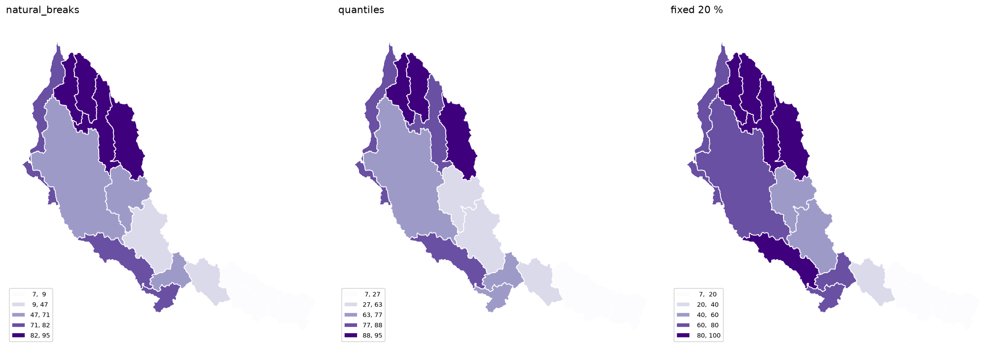


CHOICE: fixed 20 %
DEFENCE: I used fixed breaks at 20 % steps because the council will compare this screen with next year's (and with each sub-basin map), and recomputed breaks would make those maps incomparable even though each would look correct.


In [22]:
# [Python] Lab — your starting scaffold. Fill in the TODOs.

# ── STEP 1: load + verify ───────────────────────────────────────────────────
assert_aligned(watersheds, streams, salmon, hs_path)
print(f"{len(watersheds)} watersheds | pct_suitable {watersheds['pct_suitable'].min():.1f}–"
      f"{watersheds['pct_suitable'].max():.1f} % | CRS EPSG:{watersheds.crs.to_epsg()}")

# ── STEP 2: choose symbology ────────────────────────────────────────────────
LAB_FIELD = "pct_suitable"     # TODO: or pct_forest — but never a raw total like area_km2 or stream_km
LAB_CMAP  = "Purples"          # TODO: sequential for a percentage. Not jet. Not a qualitative palette.

# ── STEP 3: choose classification — and defend it ───────────────────────────
CANDIDATES = {
    "natural_breaks": {"scheme": "natural_breaks", "k": 5},
    "quantiles":      {"scheme": "quantiles", "k": 5},
    "fixed 20 %":     {"scheme": "user_defined", "classification_kwds": {"bins": SUIT_BINS}},
}
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
for ax, (name, kw) in zip(axes, CANDIDATES.items()):
    watersheds.plot(ax=ax, column=LAB_FIELD, cmap=LAB_CMAP, edgecolor="white", legend=True,
                    legend_kwds={"loc": "lower left", "fontsize": 8, "fmt": "{:.0f}"}, **kw)
    ax.set_title(name, loc="left"); ax.set_axis_off()
plt.tight_layout(); plt.show()

CHOICE = "fixed 20 %"          # TODO: change this to your pick
DEFENCE = (
    "I used fixed breaks at 20 % steps because the council will compare this screen with next year's "
    "(and with each sub-basin map), and recomputed breaks would make those maps incomparable even "
    "though each would look correct."
)
# TODO: rewrite DEFENCE in your own words. If it says "because it looked best," try again.
print(f"\nCHOICE: {CHOICE}\nDEFENCE: {DEFENCE}")

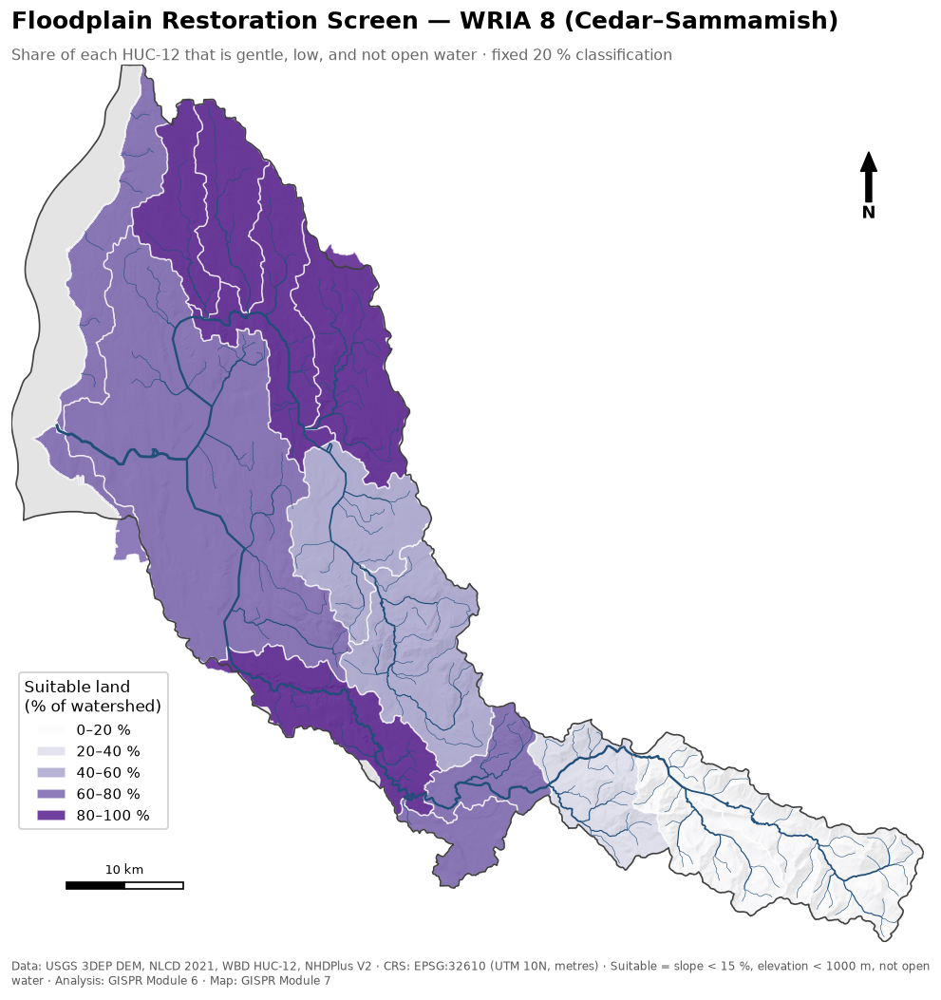

exported: outputs\module7\LAB_report_map_300dpi.png (1,686,422 bytes)
Now OPEN it at 100%. Can you read the legend? The scale bar label? The credits?
If not, the map is not done — regardless of whether the code ran.


In [23]:
# [Python] Lab — STEP 4: the report map, with all the furniture
fig, ax = plt.subplots(figsize=(11, 10))
with rasterio.open(hs_path) as src:
    rshow(src, ax=ax, cmap="Greys_r", alpha=0.55)
legend_kw = {"title": "Suitable land\n(% of watershed)", "loc": "lower left", "bbox_to_anchor": (0.0, 0.12),
             "fontsize": 9, "title_fontsize": 10, "frameon": True, "framealpha": 0.92}
if CHOICE == "fixed 20 %":
    legend_kw["labels"] = SUIT_LABELS
watersheds.plot(ax=ax, column=LAB_FIELD, cmap=LAB_CMAP, alpha=0.75, edgecolor="white", linewidth=0.9,
                legend=True, legend_kwds=legend_kw, **CANDIDATES[CHOICE])
streams.plot(ax=ax, color="#1f4e79", linewidth=streams["stream_order"].clip(1, 5) * 0.35)
wria8.boundary.plot(ax=ax, color="0.25", linewidth=1.0)

ax.set_title("Floodplain Restoration Screen — WRIA 8 (Cedar–Sammamish)", fontsize=15, fontweight="bold",
             loc="left", pad=12)
ax.text(0, 1.005, f"Share of each HUC-12 that is gentle, low, and not open water · {CHOICE} classification",
        transform=ax.transAxes, fontsize=9.5, color="0.4")
ax.set_axis_off()
add_scale_bar(ax, 10000); add_north_arrow(ax); add_credits(ax, CREDITS)

lab_png = OUT / "LAB_report_map_300dpi.png"
plt.savefig(lab_png, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"exported: {lab_png} ({lab_png.stat().st_size:,} bytes)")
print("Now OPEN it at 100%. Can you read the legend? The scale bar label? The credits?")
print("If not, the map is not done — regardless of whether the code ran.")

🔵 **`[R]`**

OK - all 4 layers aligned on EPSG:32610
ℹ tmap modes "plot" - "view"

CHOICE: fixed 
DEFENCE: I used fixed breaks at 20% steps because the council will compare this screen with next year's and with each sub-basin map, and recomputed breaks would make those maps incomparable even though each would look correct. 


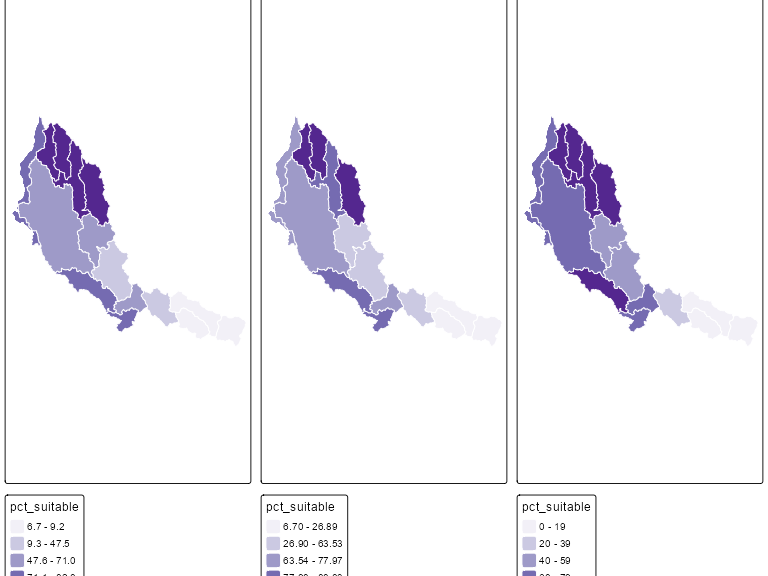

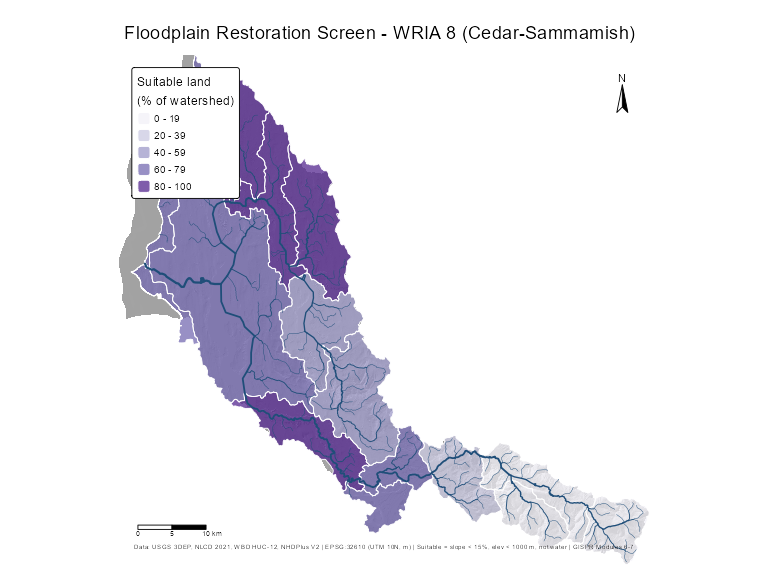

Map saved to c:\Users\mwebe\OneDrive\UW Program\GISPR\GitHubRepo\modules\outputs\module7\LAB_report_map_300dpi_r.png
Resolution: 2700 by 2400 pixels
Size: 9 by 8 inches (300 dpi)

exported: outputs/module7/LAB_report_map_300dpi_r.png 
Now OPEN it at 100%. Can you read the legend? The scale bar label? The credits?


In [ ]:
# [R] Lab — the same five steps in R
library(sf)
library(terra)
library(tmap)

# ── STEP 1: load + verify ──────────────────────────────────────────────────
assert_aligned(watersheds, streams, salmon, hs)

# ── STEP 2: symbology — the field is already normalized (a percentage) ─────
LAB_FIELD <- "pct_suitable"     # TODO: or pct_forest — never a raw total

# ── STEP 3: three candidates, pick one, defend it ──────────────────────────
tmap_mode("plot")
cand <- list(jenks    = tm_scale_intervals(style = "jenks",    n = 5, values = "brewer.purples"),
             quantile = tm_scale_intervals(style = "quantile", n = 5, values = "brewer.purples"),   # singular
             fixed    = tm_scale_intervals(style = "fixed", breaks = c(0, 20, 40, 60, 80, 100),
                                           values = "brewer.purples"))
do.call(tmap_arrange, c(lapply(names(cand), function(nm)
  tm_shape(watersheds) + tm_polygons(fill = LAB_FIELD, col = "white", fill.scale = cand[[nm]]) + tm_title(nm)),
  list(nrow = 1)))

CHOICE  <- "fixed"              # TODO: change this to your pick
DEFENCE <- paste("I used fixed breaks at 20% steps because the council will compare this screen with next",
                 "year's and with each sub-basin map, and recomputed breaks would make those maps",
                 "incomparable even though each would look correct.")
# TODO: rewrite DEFENCE in your own words. "Because it looked best" is not a defence.
cat("\nCHOICE:", CHOICE, "\nDEFENCE:", DEFENCE, "\n")

# ── STEP 4: the report map ─────────────────────────────────────────────────
lab_map <- tm_shape(hs) +
    tm_raster(col.scale = tm_scale_continuous(values = "brewer.greys"), col.legend = tm_legend_hide(),
              col_alpha = 0.55) +
  tm_shape(watersheds) +
    tm_polygons(fill = LAB_FIELD, col = "white", fill_alpha = 0.75, fill.scale = cand[[CHOICE]],
                fill.legend = tm_legend(title = "Suitable land\n(% of watershed)")) +
  tm_shape(streams) + tm_lines(col = "#1f4e79", lwd = "lwd", lwd.scale = tm_scale_asis(), lwd.legend = tm_legend_hide()) +
  tm_scalebar(breaks = c(0, 5, 10), position = c("left", "bottom")) +
  tm_compass(type = "arrow", position = c("right", "top")) +
  tm_credits(CREDITS, size = 0.5, position = c("left", "bottom")) +
  tm_title("Floodplain Restoration Screen - WRIA 8 (Cedar-Sammamish)") +
  tm_layout(frame = FALSE, legend.position = c("left", "top"))
lab_map
lab_png <- file.path(OUT, "LAB_report_map_300dpi_r.png")
tmap_save(lab_map, lab_png, dpi = 300, width = 9, height = 8)
cat("\nexported:", lab_png, "\nNow OPEN it at 100%. Can you read the legend? The scale bar label? The credits?\n")

# ── STEP 5: the interactive version — the SAME object, one line ────────────
# tmap_mode("view"); lab_map; tmap_mode("plot")

---
## Section 10 — Extended Application: Wrap It in a Function ⭐ *Extra credit*

**Scenario extension:** the council now wants the same map for each of the five HUC-10 sub-basins — Cedar River,
Lake Sammamish, Sammamish River, Lake Washington, Puget Sound frontal — plus a WRIA-wide overview. Six maps, identical
cartography, comparable legends.

This is the payoff. Not "matplotlib can draw a polygon" — but *the Tuesday request takes 30 seconds instead of
3 hours, and every map is identical because the same code drew it.*

`map_watersheds()` below is a **carry-forward function**: it joins `inspect_raster()` and `raster_pipeline()`
from Modules 5–6 in your personal toolkit. Module 8 turns it into the last cell of an end-to-end pipeline.

🟢 **`[Python]`**

✓ all 4 layers aligned on EPSG:32610
  ✓ WRIA 8 overview        -> map_wria_8_overview.png                  412,835 bytes
✓ all 4 layers aligned on EPSG:32610
  ✓ Cedar River            -> map_cedar_river.png                      246,014 bytes
✓ all 4 layers aligned on EPSG:32610
  ✓ Lake Sammamish         -> map_lake_sammamish.png                   340,994 bytes
✓ all 4 layers aligned on EPSG:32610
  ✓ Sammamish River        -> map_sammamish_river.png                  325,110 bytes
✓ all 4 layers aligned on EPSG:32610
  ✓ Lake Washington        -> map_lake_washington.png                  313,989 bytes
✓ all 4 layers aligned on EPSG:32610
  ✓ Puget Sound frontal    -> map_puget_sound_frontal.png              156,115 bytes

Six maps. Identical breaks, identical legend, identical furniture.
Re-run it next year when the data changes. That is the whole argument of this course.
✓ all 4 layers aligned on EPSG:32610


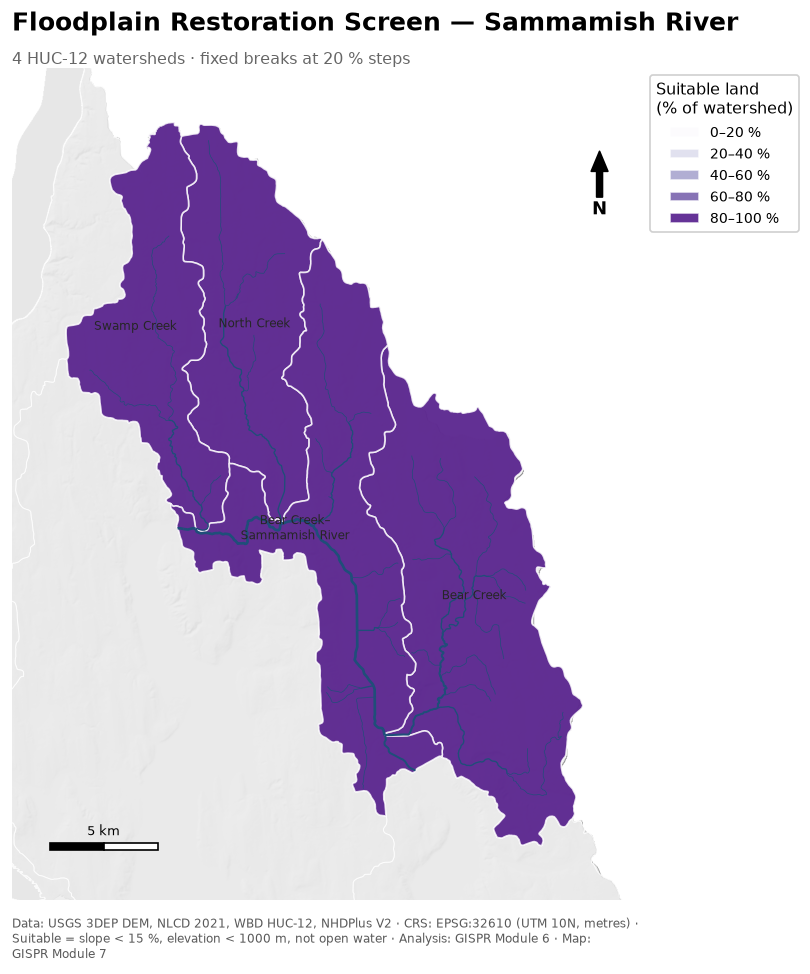

In [24]:
# [Python] A reusable, parameterized map function — carry this into Module 8
def map_watersheds(ws, streams=None, hillshade_path=None, *, column="pct_suitable", bins=SUIT_BINS,
                   labels=SUIT_LABELS, cmap="Purples", legend_title="Suitable land\n(% of watershed)",
                   title="Floodplain Restoration Screen", subtitle=None, context=None, credits=CREDITS,
                   scale_m=10000, out_path=None, dpi=300, figsize=(10, 10)):
    """Render a report-ready watershed map in EPSG:32610.

    Fixed `bins` by default — so every map this function draws is comparable to every other one.
    That is the entire reason it takes `bins` and not `scheme`.
    `context` (optional) is drawn in light grey underneath, so a sub-basin map shows where it sits.
    Returns the matplotlib Figure.
    """
    assert_aligned(*[x for x in (ws, streams, context, hillshade_path) if x is not None])
    fig, ax = plt.subplots(figsize=figsize)
    xmin, ymin, xmax, ymax = ws.buffer(2500).total_bounds

    if hillshade_path is not None:
        with rasterio.open(hillshade_path) as src:
            rshow(src, ax=ax, cmap="Greys_r", alpha=0.5)
    if context is not None:
        context.plot(ax=ax, facecolor="0.92", edgecolor="white", linewidth=0.6, alpha=0.8)
    ws.plot(ax=ax, column=column, cmap=cmap, scheme="user_defined", classification_kwds={"bins": list(bins)},
            alpha=0.8, edgecolor="white", linewidth=1, legend=True,
            legend_kwds={"title": legend_title, "labels": list(labels), "loc": "upper left",
                         "bbox_to_anchor": (1.01, 1.0), "fontsize": 8.5,      # outside the frame: works for any extent
                         "title_fontsize": 9.5, "frameon": True, "framealpha": 0.92})
    if streams is not None:
        s = streams.clip(ws.union_all())
        s.plot(ax=ax, color="#1f4e79", linewidth=s["stream_order"].clip(1, 5) * 0.4)
    for _, r in ws.iterrows():                                   # label every watershed — no hunting for the legend
        p = r.geometry.representative_point()
        ax.annotate(r["watershed_name"].replace("-", "–\n", 1), (p.x, p.y), ha="center", va="center",
                    fontsize=7, color="0.15")

    ax.set_xlim(xmin, xmax); ax.set_ylim(ymin, ymax)
    ax.set_title(title, fontsize=15, fontweight="bold", loc="left", pad=12)
    if subtitle:
        ax.text(0, 1.005, subtitle, transform=ax.transAxes, fontsize=9.5, color="0.4")
    ax.set_axis_off()
    add_scale_bar(ax, scale_m); add_north_arrow(ax); add_credits(ax, credits)
    if out_path:
        fig.savefig(out_path, dpi=dpi, bbox_inches="tight", facecolor="white")
    return fig


# ── THE PAYOFF: six maps, identical cartography, one loop ───────────────────
targets = [("WRIA 8 overview", watersheds)] + [(sb, watersheds[watersheds["subbasin"] == sb])
                                               for sb in SUBBASIN.values()]
for label, sel in targets:
    p = OUT / f"map_{label.replace(' ', '_').lower()}.png"
    fig = map_watersheds(sel, streams, hs_path, context=watersheds,
                         title=f"Floodplain Restoration Screen — {label}",
                         subtitle=f"{len(sel)} HUC-12 watershed{'s' if len(sel) > 1 else ''} · fixed breaks at 20 % steps",
                         scale_m=10000 if len(sel) > 3 else 5000, out_path=p, dpi=150)
    plt.close(fig)
    print(f"  ✓ {label:22} -> {p.name:38} {p.stat().st_size:>9,} bytes")
print("\nSix maps. Identical breaks, identical legend, identical furniture.")
print("Re-run it next year when the data changes. That is the whole argument of this course.")

# Show one of them
fig = map_watersheds(watersheds[watersheds["subbasin"] == "Sammamish River"], streams, hs_path, context=watersheds,
                     title="Floodplain Restoration Screen — Sammamish River",
                     subtitle="4 HUC-12 watersheds · fixed breaks at 20 % steps", scale_m=5000, figsize=(9, 9))
plt.show()

🔵 **`[R]`**

OK - all 3 layers aligned on EPSG:32610
Map saved to c:\Users\mwebe\OneDrive\UW Program\GISPR\GitHubRepo\modules\outputs\module7\map_cedar_river_r.png
Resolution: 1200 by 1200 pixels
Size: 8 by 8 inches (150 dpi)
  OK Cedar River          -> map_cedar_river_r.png
OK - all 3 layers aligned on EPSG:32610
[plot mode] fit legend/component: Some legend items or map compoments
do not fit well, and are therefore rescaled.
ℹ Set the tmap option `component.autoscale = FALSE` to disable
  rescaling.
Map saved to c:\Users\mwebe\OneDrive\UW Program\GISPR\GitHubRepo\modules\outputs\module7\map_lake_sammamish_r.png
Resolution: 1200 by 1200 pixels
Size: 8 by 8 inches (150 dpi)
  OK Lake Sammamish       -> map_lake_sammamish_r.png
OK - all 3 layers aligned on EPSG:32610
[plot mode] fit legend/component: Some legend items or map compoments
do not fit well, and are therefore rescaled.
ℹ Set the tmap option `component.autoscale = FALSE` to disable
  rescaling.
Map saved to c:\Users\mwebe\OneDrive\UW Prog

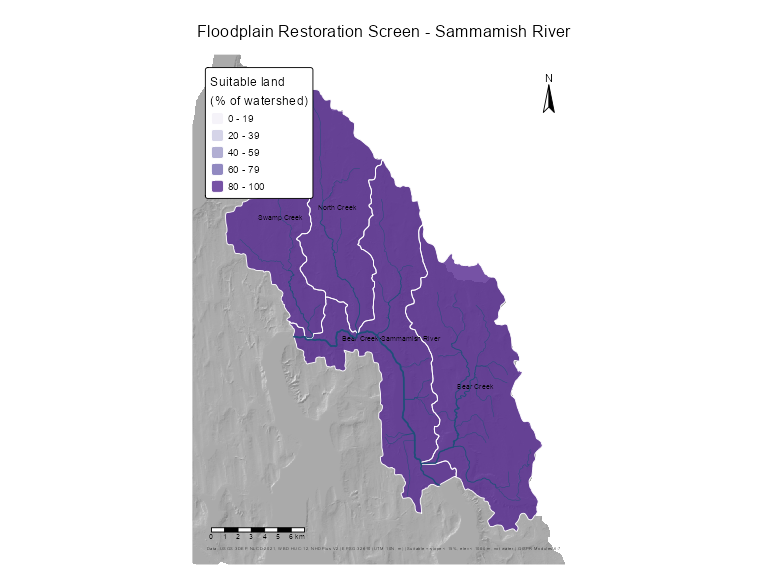

[plot mode] fit legend/component: Some legend items or map compoments
do not fit well, and are therefore rescaled.
ℹ Set the tmap option `component.autoscale = FALSE` to disable
  rescaling.

In [ ]:
# [R] The same reusable function in R — carry this into Module 8
library(tmap)
library(sf)

map_watersheds <- function(ws, streams = NULL, hs = NULL,
                           column   = "pct_suitable",
                           breaks   = c(0, 20, 40, 60, 80, 100),
                           palette  = "brewer.purples",
                           title    = "Floodplain Restoration Screen",
                           credits  = CREDITS,
                           out_path = NULL, dpi = 300) {
  # Fixed `breaks` by default — so every map this function draws is comparable to every other one.
  # That is the entire reason it takes breaks, not style.
  layers <- Filter(Negate(is.null), list(ws, streams, hs))
  do.call(assert_aligned, layers)

  m <- if (!is.null(hs)) {
    tm_shape(hs, bbox = st_bbox(st_buffer(ws, 2500))) +
      tm_raster(col.scale = tm_scale_continuous(values = "brewer.greys"), col.legend = tm_legend_hide(),
                col_alpha = 0.5) +
      tm_shape(ws)
  } else tm_shape(ws)
  m <- m + tm_polygons(fill = column, col = "white", fill_alpha = 0.8,
                       fill.scale  = tm_scale_intervals(style = "fixed", breaks = breaks, values = palette),
                       fill.legend = tm_legend(title = "Suitable land\n(% of watershed)")) +
    tm_text("watershed_name", size = 0.5)
  if (!is.null(streams)) {
    s <- st_intersection(streams, st_union(ws))
    m <- m + tm_shape(s) + tm_lines(col = "#1f4e79", lwd = "lwd", lwd.scale = tm_scale_asis(),
                                    lwd.legend = tm_legend_hide())
  }
  m <- m +
    tm_scalebar(position = c("left", "bottom")) +
    tm_compass(type = "arrow", position = c("right", "top")) +
    tm_credits(credits, size = 0.5, position = c("left", "bottom")) +
    tm_title(title) +
    tm_layout(frame = FALSE, legend.position = c("left", "top"))
  if (!is.null(out_path)) tmap_save(m, out_path, dpi = dpi, width = 8, height = 8)
  m
}

# ── THE PAYOFF: one map per sub-basin, identical cartography, one loop ─────
for (sb in unique(watersheds$subbasin)) {
  sel <- watersheds[watersheds$subbasin == sb, ]
  p   <- file.path(OUT, paste0("map_", gsub(" ", "_", tolower(sb)), "_r.png"))
  map_watersheds(sel, streams, hs, title = paste("Floodplain Restoration Screen -", sb), out_path = p, dpi = 150)
  cat(sprintf("  OK %-20s -> %s\n", sb, basename(p)))
}
cat("\nIdentical breaks, identical legend, identical furniture. Re-run it next year.\n")

# Show one
map_watersheds(watersheds[watersheds$subbasin == "Sammamish River", ], streams, hs,
               title = "Floodplain Restoration Screen - Sammamish River")

### 🔧 Try it yourself — the reusable function ⭐ *(extra credit — optional)*

1. Add a `basemap=True` argument that calls `contextily.add_basemap()` — and handle the network failure
   gracefully, because an agency firewall will block it.
2. Add a `comparison_safe=True` guard that **refuses** to run if someone passes `scheme=` instead of
   `bins=`. Make the function enforce the lesson.
3. Add an `interactive=True` branch that returns a `folium` map instead of a Figure — same breaks, same
   colours, same legend text. One function, both media.
4. Call it with `column="pct_forest"` and `cmap="Greens"`. What else has to change for the map to be honest?
   (Hint: `legend_title`, `labels`, the credits.)
5. Point it at one of your own agency's layers. What breaks? That's your Module 8 backlog.

---

## 🍍 Module 7 — Self-Check Questions

✅ **Required for the homework.** Every question is answered somewhere in Sections 1–8 — scroll back and re-run cells as
much as you like. Write your answers in the **answers cell right below** (double-click it to edit). A sentence or two each
is plenty; where a question asks for code, paste the line.

**Symbology**
1. Why is a choropleth of a raw total (stream km, salmon counted) almost always wrong? What are the *two* correct
   alternatives?
2. You have NLCD land cover with 15 classes. Why is `cmap="viridis"` the wrong choice?
3. Roughly 1 in 12 men has some form of colour vision deficiency. What does that mean for a red-green
   map in a public meeting of 60 people — and what's your obligation as a public agency?

**Classification**
4. Explain in one sentence why Jenks is wrong for a two-map comparison, even though it's "optimal."
5. What does `mapclassify.Quantiles(vals, k=5).counts` return, and why does that explain why quantile maps
   always look good?
6. Write the GeoPandas argument that pins breaks at the WAC temperature criteria (12, 16, 17.5, 20). Now the tmap equivalent.
   Which one spells it `quantiles`, and which `quantile`?

**Cartographic elements**
7. Five of 15 watersheds have no salmon observations. What happens to them if you omit `missing_kwds`, and what does a
   reader conclude?
8. Which two elements make a map *verifiable* rather than merely attractive? Defend your pick.
9. When is a north arrow redundant? When is a scale bar redundant?

**Layering and CRS**
10. The course geodatabase is in EPSG:2926; the rasters are in EPSG:32610. Plot both on one matplotlib Axes without
    reprojecting. What warning do you get? What does the figure look like?
11. Write the assertion you'd put at the top of any multi-layer plotting script.

**Interactive**
12. What single line must come before `folium.GeoJson(gdf)`, and what happens if you forget it?
13. `key_on="feature.properties.watershed_id"` — what breaks if you typo it, and how would you notice?
14. When would you reach for `leafmap`/`mapview` over `folium`/`leaflet`? Give the one-sentence rule.
15. NHDPlus V2 was compiled at 1:100,000. Why is `max_zoom=18` an honesty problem, not a technical one?
16. Which `leafmap` backend exports standalone HTML without Jupyter widgets, and why does that matter on JupyterHub?

### ✏️ Your answers — Self-Check Questions

*(Double-click to edit. One or two sentences each; paste code where asked.)*

1. 
2. 
3. 
4. 
5. 
6. 
7. 
8. 
9. 
10. 
11. 
12. 
13. 
14. 
15. 
16. 

---
## ✅ Module 7 Homework — Run It and Explain It

This week's homework is deliberately light: show that the notebook runs for you on the course data, and that you can explain
what the maps are doing. Submit before the next session.

### Required

**1. Run Sections 1–8 (50 pts)**
- Copy the course data into `data/` (Section 1 table or the copy helper), then run every cell in **Sections 1–8** in order.
- Python is enough; R cells are welcome. 🏠 LOCAL ONLY cells (ArcPy, R-ArcGIS Bridge) count as run if they print their
  "not available" note.
- **Save the notebook with its outputs showing** — the maps and printouts are the evidence that it ran.
- If a cell fails and you can't fix it, leave the error showing and add a markdown cell underneath saying what you tried.
  A documented failure earns credit; a blank cell doesn't.

**2. Answer the 🍍 Self-Check Questions (50 pts)**
- Answer all 16 in the **✏️ Your answers** cell. One or two sentences each; paste code where a question asks for it.

### ⭐ Extra credit (optional)

| Item | What to submit |
|---|---|
| **🔧 Try it yourself** prompts | Do any of them in a new cell under the prompt, with a sentence on what you saw |
| **Section 9 — Lab** | Your 300 dpi report map (`outputs/module7/LAB_report_map_300dpi.png`) and your own `DEFENCE` sentence: *"I used ___ breaks because ___."* |
| **Section 10 — Function** | The sub-basin maps from `map_watersheds()`, plus one change of your own (a Try-it-yourself idea, or a different field) |

### How to submit
As with other labs you can submit one or several Jupyter Notebook .ipynb files in the Assignment 7 portal in Canvas showing outputs and completed content.  You can als commit the notebook (with outputs) to your GitHub repo — the same repo as Modules 2–6 — and tag the commit
`module7-deliverable`. Include any extra-credit PNGs from `outputs/module7/`. **Don't commit the `data/` folder**: add
`data/` to `.gitignore`; it's course data, not your work. You can also upload the notebook(s) with your nanme or initials as the suffix in JupyterLab for Classroom showing the output. If you don't post your notebooks or content directly in the Assignment portal in Canvas just indicate there where we should look for the homework.

---

**Stuck?** Post in Ed Discussion — tag `#module7`. Include your error message, the cell that failed, and
your OS/environment. If you solved something tricky, share how — the whole cohort benefits.

---

### Coming next — Module 8: End-to-End Workflows

Tonight the map was the destination. In Module 8 it becomes **the last cell of a pipeline** — raw data to
finished PNG in one script, re-run when the data changes. `hillshade()`, `assert_aligned()`, and `map_watersheds()`
come with you.